# DOS Convergence Analysis — Full Run (146 Materials)

## Objective
Extend the MADAS framework (Kuban, Rigamonti, Draxl, *Digital Discovery* 2024) to assess
numerical convergence across the FHI-aims Numerical_Errors dataset by measuring DOS shape
similarity across different k-point/basis-function settings, independent of material.

## Methodology
Each material in this dataset was computed at its original unit-cell volume, and again at
one or two successive +5%-expanded volumes (per the numerical-errors paper's methodology),
across a range of k-point grids and basis-set sizes. For each material:

1. **Corrected DOS fingerprint grid** — `delta_rho_max = global_max_dos × 1.05` (887.59),
   fixing a grid-height bug where the untuned default (5.5) clipped tall DOS peaks,
   particularly in rare-earth compounds (f-electron physics).
2. **Volume-group splitting** — calculations are grouped by unit-cell volume (gap-based
   clustering), so the original and expanded-volume structures are never compared directly
   against each other in the same similarity heatmap.
3. **Row-similarity sorting** — within each volume group, calculations are ordered by their
   mean similarity to every other calculation in that group (ascending: least similar to
   peers first, most similar last), revealing convergence structure as clean diagonal blocks.

Each material below shows its name and unit cell, one heatmap panel per volume group, and a
k-points/basis-functions subplot underneath each heatmap (same sort order), so any block
boundary in the heatmap can be checked directly against the numerical setting that caused it.

## Scope
**146 of 161 materials** are included:
- 13 excluded — incomplete calculation counts (Ar4, Ba2, Be2, Ca4, Cd2, Hg2, Kr4, Mg2, Ne4,
  Rn4, Sr4, Xe4, Zn2)
- 2 excluded — **Cs2, Cu4** — pending review (ambiguous volume-clustering result between
  detection methods; flagged for Martin's input)

## Result
All 146 materials processed successfully with 0 failures.

## Step 1: Setup and corrected DOS fingerprint grid
Loads every per-material MADAS database (`.db` files), finds the largest DOS value across the whole dataset, and builds one shared fingerprint grid whose height is that maximum × 1.05. Using the same grid for all materials keeps similarity values comparable between them, and the extra height prevents tall DOS peaks from being clipped. Paths at the top point to a local copy of the data and need adjusting on your machine.

In [3]:
# --- Imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from madas import MaterialsDatabase
from madas.fingerprints import DOSFingerprint

# --- Paths (adjust if your repo root differs) ---
repo_root = Path("/home/ahmed/SOL_Research/dos-convergence-analysis")
database_dir = repo_root / "notebooks" / "data" / "full_run"   # wherever your .db files live
volume_test_dir = repo_root / "results" / "full_run_row_sorted"  # new output folder for this notebook
volume_test_dir.mkdir(parents=True, exist_ok=True)

# --- Rebuild the corrected DOS fingerprint grid (delta_rho_max = global_max_dos * 1.05) ---
database_files = sorted(database_dir.glob("*.db"))

global_max_dos = 0.0
for db_path in database_files:
    mat_db = MaterialsDatabase(filename=str(db_path))
    for entry in mat_db:
        try:
            dos_values = np.asarray(entry.data["electronic_dos_values"], dtype=float)
        except (KeyError, TypeError):
            continue
        this_max = float(np.max(dos_values))
        if this_max > global_max_dos:
            global_max_dos = this_max

safe_delta_rho_max = global_max_dos * 1.05
grid = DOSFingerprint.get_default_grid().create(
    n_pix=2048,
    delta_rho_min=0.5,
    delta_rho_max=safe_delta_rho_max,
    cutoff=[-8, 12],
)

print("global_max_dos:", round(global_max_dos, 2))
print("Corrected grid delta_rho_max:", round(safe_delta_rho_max, 2))

global_max_dos: 845.32
Corrected grid delta_rho_max: 887.59


## Step 2: Helper functions
- `assign_volume_groups` splits a material's calculations into groups by unit-cell volume (a new group starts wherever consecutive sorted volumes differ by more than 2 %), so the original and the +5 % expanded structures are never compared in the same heatmap.
- `print_material_header` prints the formula, number of atoms and cell parameters.
- `get_sorted_order_by_row_similarity` orders a group's calculations by their mean similarity to all the others (ascending), which turns the similarity matrix into clean diagonal blocks.

In [10]:
# --- Assign each calculation to a volume group (gap-based clustering) ---
def assign_volume_groups(mat_db, relative_gap_threshold=0.02):
    """
    For every calculation in a material's database, determine its unit-cell
    volume and assign it to a volume group (0, 1, 2, ...) based on genuine
    gaps in the sorted volume values.
    """
    id_volume_pairs = []
    for entry in mat_db:
        try:
            vol = float(entry.atoms.get_volume())
        except Exception:
            continue
        id_volume_pairs.append((entry.mid, vol))

    id_volume_pairs.sort(key=lambda pair: pair[1])

    groups = []
    for calc_id, vol in id_volume_pairs:
        if not groups:
            groups.append([(calc_id, vol)])
            continue
        prev_vol = groups[-1][-1][1]
        if (vol - prev_vol) / prev_vol > relative_gap_threshold:
            groups.append([(calc_id, vol)])
        else:
            groups[-1].append((calc_id, vol))

    id_to_group = {}
    group_centers = []
    for group_index, group in enumerate(groups):
        group_centers.append(round(float(np.mean([v for _, v in group])), 3))
        for calc_id, _ in group:
            id_to_group[calc_id] = group_index

    return id_to_group, group_centers


# --- Material header: name + structure ---
def print_material_header(material_name, mat_db):
    example_entry = next(iter(mat_db))
    formula = example_entry.atoms.get_chemical_formula()
    n_atoms = len(example_entry.atoms)
    cell = example_entry.atoms.get_cell().cellpar()
    print(f"\n{'='*70}")
    print(f"Material: {material_name}   (formula: {formula}, {n_atoms} atoms/cell)")
    print(f"Cell: a={cell[0]:.2f} b={cell[1]:.2f} c={cell[2]:.2f} Å, "
          f"α={cell[3]:.1f} β={cell[4]:.1f} γ={cell[5]:.1f}°")
    print(f"{'='*70}")


# --- Row-similarity sort: mean similarity to peers within the same volume group ---
def get_sorted_order_by_row_similarity(full_values, id_to_position, group_ids):
    """
    Sort a volume group's calculation IDs by mean similarity to every OTHER
    calculation in the same group (row/column average, excluding self).
    Ascending: least similar to peers first, most similar last.
    """
    positions = [id_to_position[cid] for cid in group_ids]
    sub_matrix = full_values[np.ix_(positions, positions)]
    n = sub_matrix.shape[0]
    row_sums = sub_matrix.sum(axis=1) - 1.0
    row_means = row_sums / (n - 1)
    id_and_mean = list(zip(group_ids, row_means))
    id_and_mean.sort(key=lambda pair: pair[1])
    return [pair[0] for pair in id_and_mean]

In [11]:
# Quick check that the function actually returns something
test_ids = list(id_to_group.keys())[:5]
print(get_sorted_order_by_row_similarity(full_values, id_to_position, test_ids))

NameError: name 'full_values' is not defined

## Step 3: Plotting and test runs
`plot_volume_split_heatmaps_row_sorted` draws one similarity heatmap per volume group, with the k-point count and number of basis functions underneath, using the same sort order. It is first tested on a few materials (Ac2Cl6, As6, AgKO3) before the full run below.

In [15]:
def plot_volume_split_heatmaps_row_sorted(material_name, mat_db, id_to_group, group_centers, save_dir):
    full_matrix_obj = mat_db.get_similarity_matrix("DOS", name="DOS")
    full_values = np.asarray(full_matrix_obj.matrix)
    full_ids = list(full_matrix_obj.mids)
    id_to_position = {cid: i for i, cid in enumerate(full_ids)}

    n_groups = len(group_centers)
    fig, axes = plt.subplots(
    2, n_groups,
    figsize=(6.5 * n_groups, 7.5),
    gridspec_kw={"height_ratios": [3, 1], "wspace": 0.4, "hspace": 0.3},
)
    if n_groups == 1:
        axes = axes.reshape(2, 1)

    for group_index in range(n_groups):
        group_ids = [cid for cid, g in id_to_group.items() if g == group_index]
        sorted_ids = get_sorted_order_by_row_similarity(full_values, id_to_position, group_ids)
        positions = [id_to_position[cid] for cid in sorted_ids]

        sub_matrix = full_values[np.ix_(positions, positions)]
        heatmap_ax = axes[0, group_index]
        im = heatmap_ax.imshow(sub_matrix, cmap="jet", vmin=0, vmax=1, origin="lower")
        heatmap_ax.set_title(
            f"{material_name} — volume {group_index + 1} "
            f"({group_centers[group_index]} Å³, n={len(positions)}, row-sorted)"
        )
        if group_index == 0:
            heatmap_ax.set_ylabel("Calculation index (sorted by row-similarity)")
        heatmap_ax.set_xticklabels([])

        settings_ax = axes[1, group_index]
        total_kpts_list, n_func_list = [], []
        for calc_id in sorted_ids:
            entry = mat_db[calc_id]
            try:
                kpt_grid = entry.data["kpoints"]
                total_kpts_list.append(kpt_grid[0] * kpt_grid[1] * kpt_grid[2])
                n_func_list.append(entry.data["n_basis_functions"])
            except (KeyError, TypeError, IndexError):
                total_kpts_list.append(np.nan)
                n_func_list.append(np.nan)

        calc_index = np.arange(len(sorted_ids))
        settings_ax.plot(calc_index, total_kpts_list, label=r"$N_{kpt}$", linewidth=1)
        settings_ax.plot(calc_index, n_func_list, label=r"$N_{func}$", linewidth=1)
        settings_ax.set_yscale("log")
        settings_ax.set_xlabel("Calculation index (sorted by row-similarity)")
        if group_index == 0:
            settings_ax.set_ylabel("Value (log scale)")
        settings_ax.legend(fontsize=8)

    # Colorbar attached to ALL subplots (top and bottom rows) so widths stay aligned
    fig.colorbar(im, ax=axes[:, :].ravel().tolist(), label="Similarity coefficient", shrink=0.6)

    save_path = save_dir / f"{material_name}_volume_split_row_sorted.svg"
    fig.savefig(save_path, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path.exists())


Material: Ac2Cl6   (formula: Ac2Cl6, 8 atoms/cell)
Cell: a=7.64 b=7.64 c=4.56 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:08:11,554 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ac2Cl6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [230.506, 242.031]


  0%|          | 0/288 [00:00<?, ?it/s]

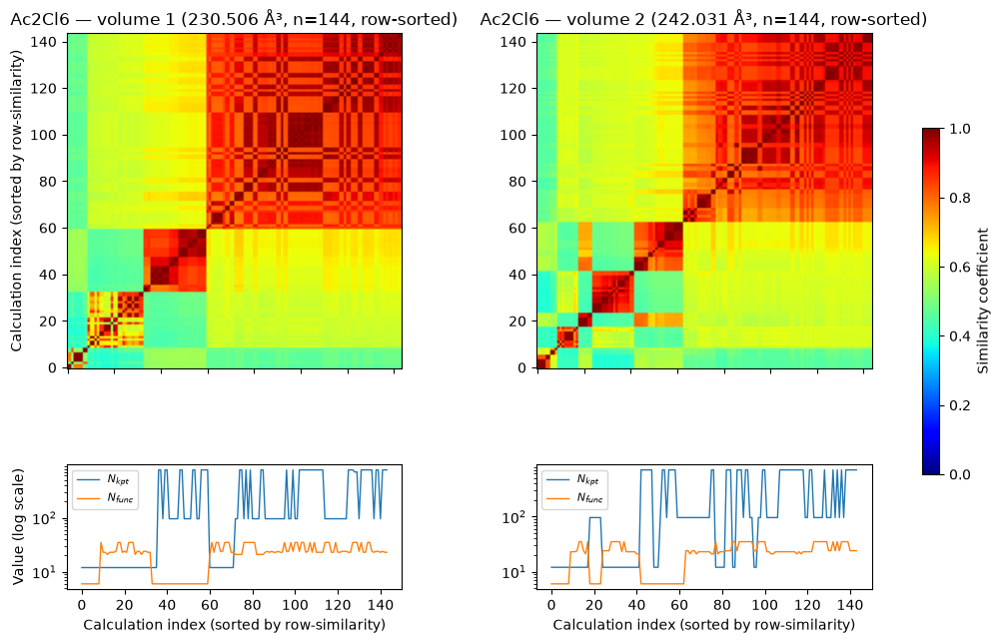

Saved: True

Material: As6   (formula: As6, 6 atoms/cell)
Cell: a=3.88 b=3.88 c=10.97 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:08:15,764 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/As6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [136.392, 143.212, 150.372]


  0%|          | 0/319 [00:00<?, ?it/s]

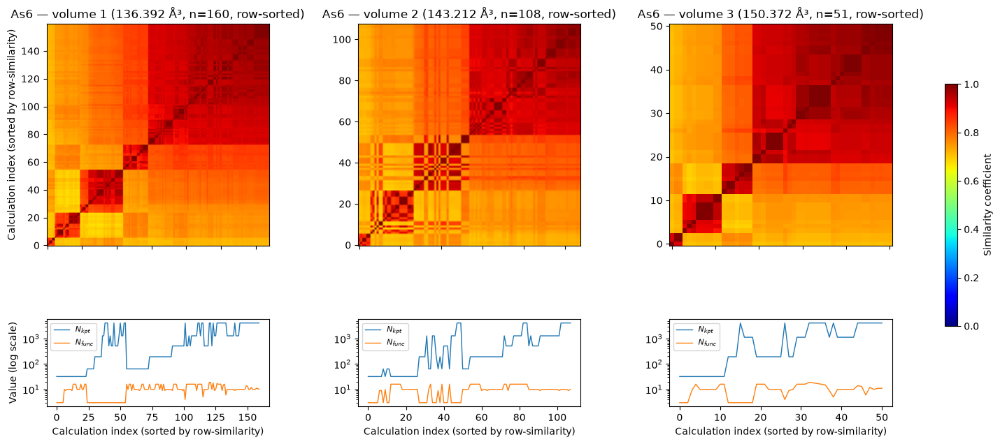

Saved: True


In [16]:
test_materials = ["Ac2Cl6", "As6"]

for material_name in test_materials:
    mat_db = MaterialsDatabase(filename=str(database_dir / f"{material_name}.db"))
    print_material_header(material_name, mat_db)
    id_to_group, group_centers = assign_volume_groups(mat_db)
    print(f"Volume groups: {group_centers}")
    plot_volume_split_heatmaps_row_sorted(material_name, mat_db, id_to_group, group_centers, volume_test_dir)


Material: AgKO3   (formula: AgKO3, 5 atoms/cell)
Cell: a=4.19 b=4.19 c=4.19 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:18:30,127 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/AgKO3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [73.358]


  0%|          | 0/144 [00:00<?, ?it/s]

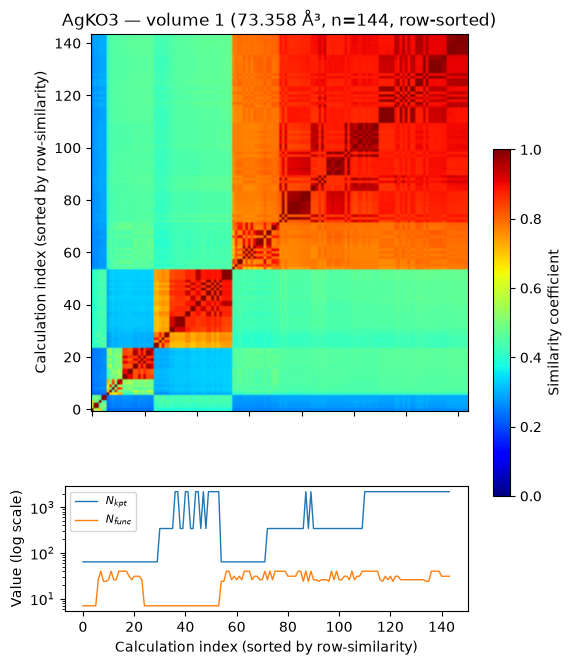

Saved: True


In [17]:
mat_db = MaterialsDatabase(filename=str(database_dir / "AgKO3.db"))
print_material_header("AgKO3", mat_db)
id_to_group, group_centers = assign_volume_groups(mat_db)
print(f"Volume groups: {group_centers}")
plot_volume_split_heatmaps_row_sorted("AgKO3", mat_db, id_to_group, group_centers, volume_test_dir)

## Step 4: Full run
Reads the results table to select the materials with complete calculation sets (excluding Cs2 and Cu4, which are pending review), then loops over them, saving one SVG heatmap per material and logging any failures. The last cell checks that the number of saved SVGs matches the number of materials in the run.

In [19]:
import pandas as pd

results_df = pd.read_csv("/home/ahmed/SOL_Research/dos-convergence-analysis/results/full_run/all_materials_results.csv")  # adjust path to your local copy

# Materials pending Martin's input on volume-clustering ambiguity
materials_pending_review = ["Cs2", "Cu4"]

# Full run list: complete calculations, excluding the pending-review pair
full_run_materials = results_df[
    (results_df["calculation_count_complete"] == True)
    & (~results_df["formula"].isin(materials_pending_review))
]["formula"].tolist()

print(f"Full run: {len(full_run_materials)} materials")
print(f"Excluded (incomplete): {13} materials")
print(f"Excluded (pending Martin): {materials_pending_review}")

Full run: 146 materials
Excluded (incomplete): 13 materials
Excluded (pending Martin): ['Cs2', 'Cu4']



Material: Ac2Cl6   (formula: Ac2Cl6, 8 atoms/cell)
Cell: a=7.64 b=7.64 c=4.56 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:26:29,895 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ac2Cl6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [230.506, 242.031]


  0%|          | 0/288 [00:00<?, ?it/s]

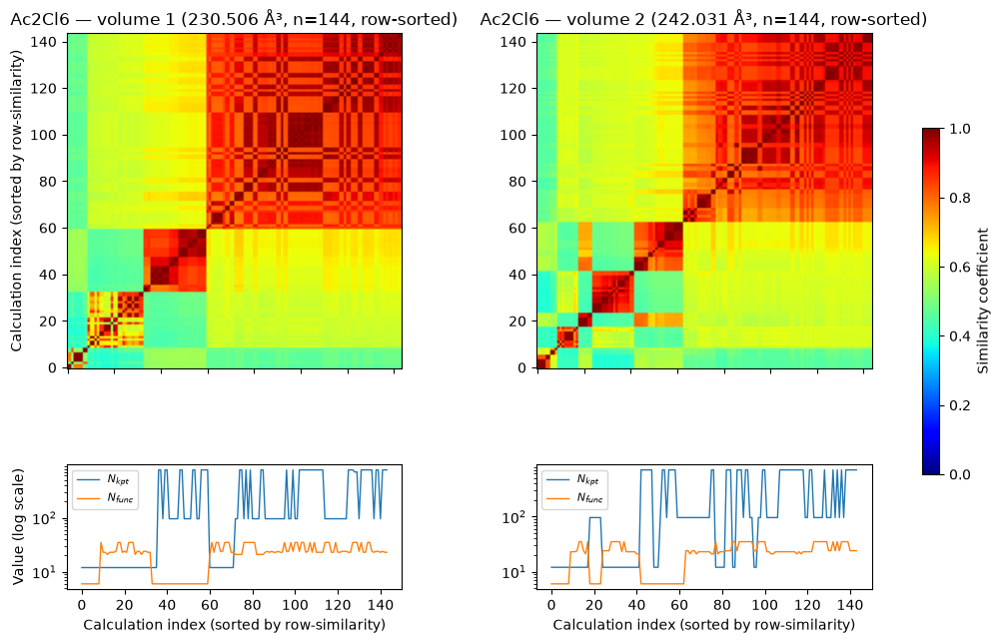

Saved: True

Material: Ag4   (formula: Ag4, 4 atoms/cell)
Cell: a=4.16 b=4.16 c=4.16 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:26:34,609 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ag4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [72.212, 75.822]


  0%|          | 0/317 [00:00<?, ?it/s]

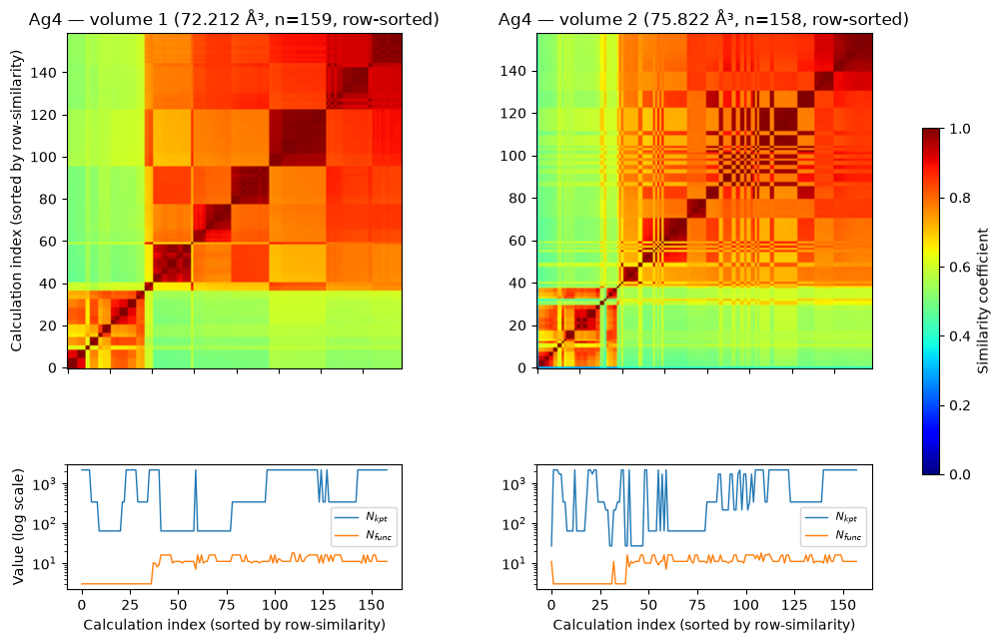

Saved: True

Material: Ag4Cl4   (formula: Ag4Cl4, 8 atoms/cell)
Cell: a=5.64 b=5.64 c=5.64 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:26:40,619 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ag4Cl4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [170.769, 179.308]


  0%|          | 0/288 [00:00<?, ?it/s]

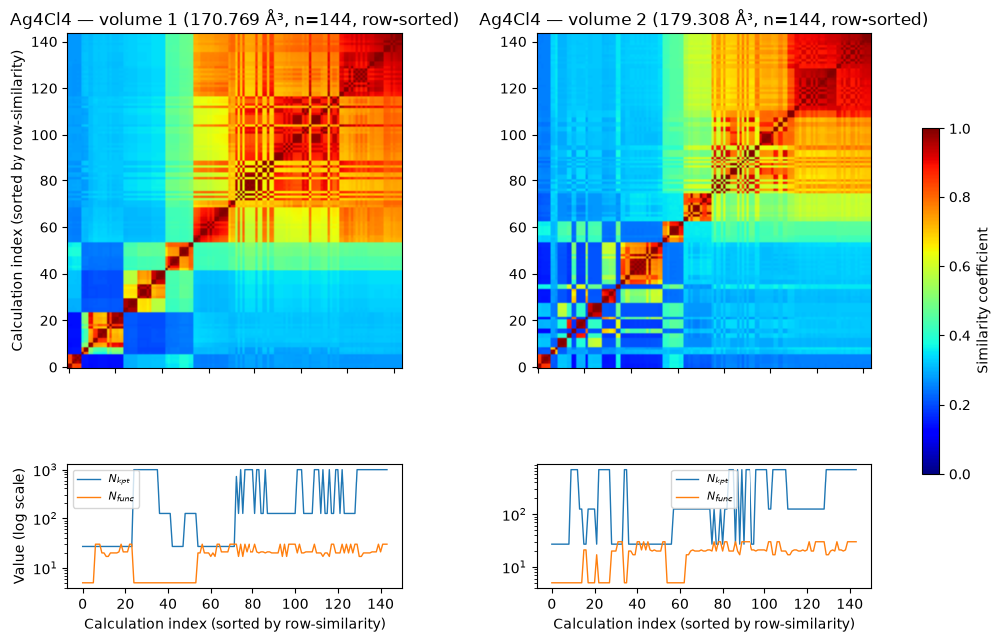

Saved: True

Material: AgKO3   (formula: AgKO3, 5 atoms/cell)
Cell: a=4.19 b=4.19 c=4.19 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:26:45,268 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/AgKO3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [73.358]


  0%|          | 0/144 [00:00<?, ?it/s]

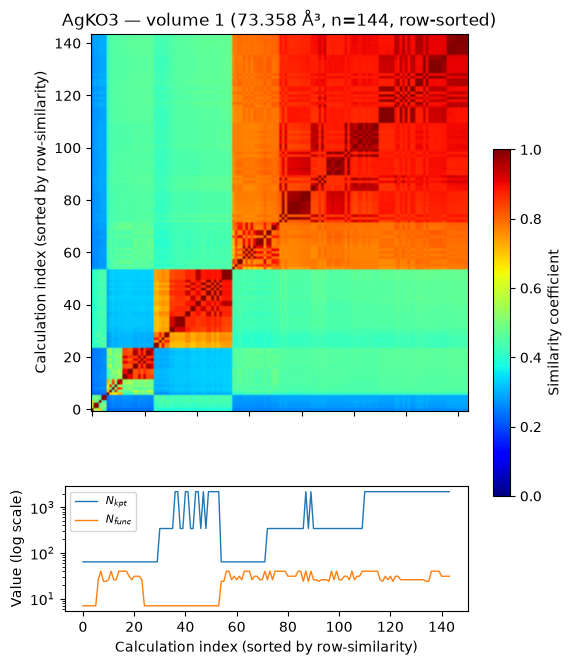

Saved: True

Material: Al4   (formula: Al4, 4 atoms/cell)
Cell: a=4.04 b=4.04 c=4.04 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [65.95, 69.247]


2026-09-06 15:26:48,946 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Al4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/323 [00:00<?, ?it/s]

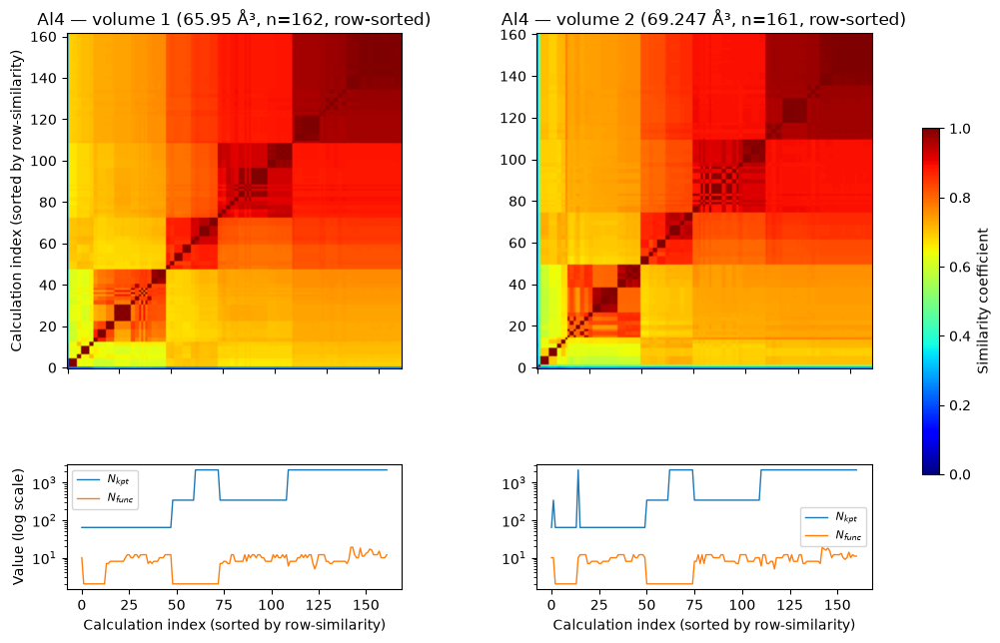

Saved: True

Material: Al4P4   (formula: Al4P4, 8 atoms/cell)
Cell: a=5.55 b=5.55 c=5.55 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [163.04, 171.192]


2026-09-06 15:26:54,864 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Al4P4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

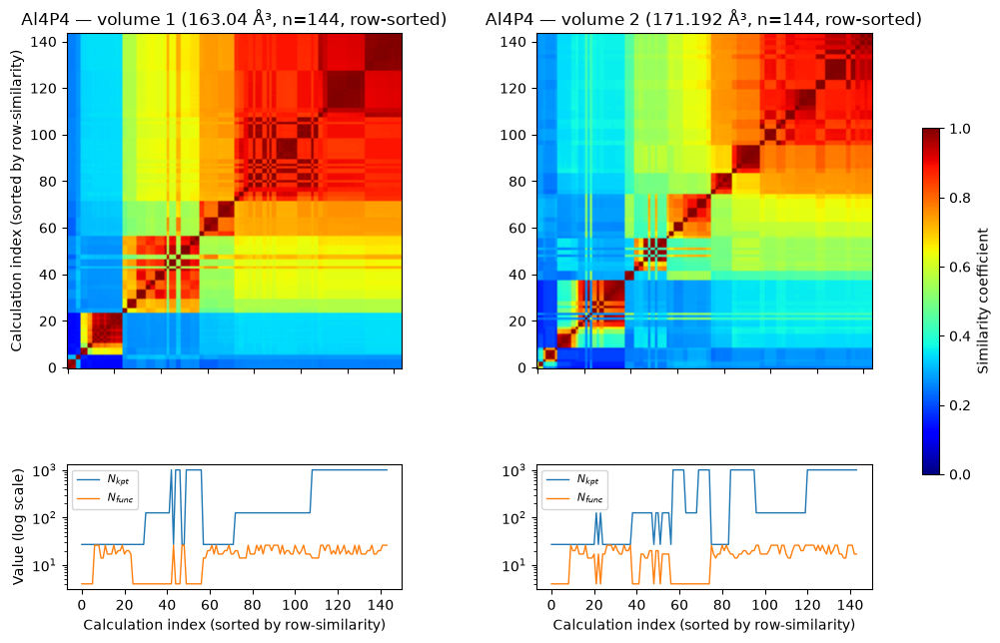

Saved: True

Material: AlGaO3   (formula: AlGaO3, 5 atoms/cell)
Cell: a=3.74 b=3.74 c=3.74 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:26:59,596 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/AlGaO3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [52.325]


  0%|          | 0/144 [00:00<?, ?it/s]

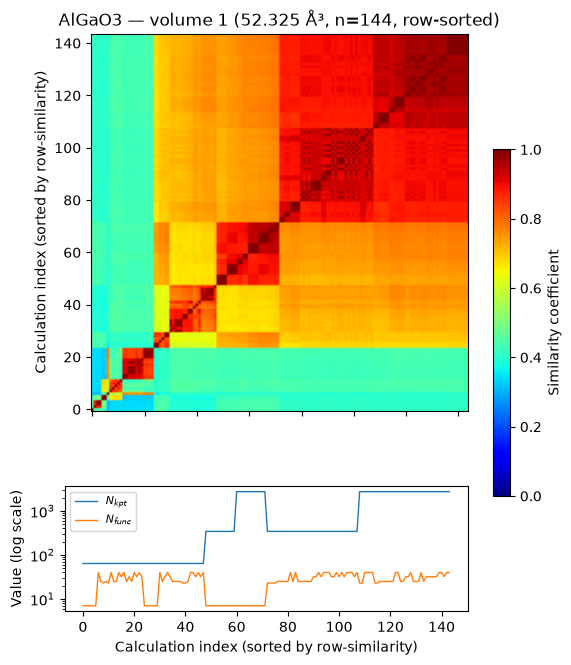

Saved: True

Material: As4Ga4   (formula: As4Ga4, 8 atoms/cell)
Cell: a=5.65 b=5.65 c=5.65 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:27:03,058 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/As4Ga4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [180.362, 189.38]


  0%|          | 0/288 [00:00<?, ?it/s]

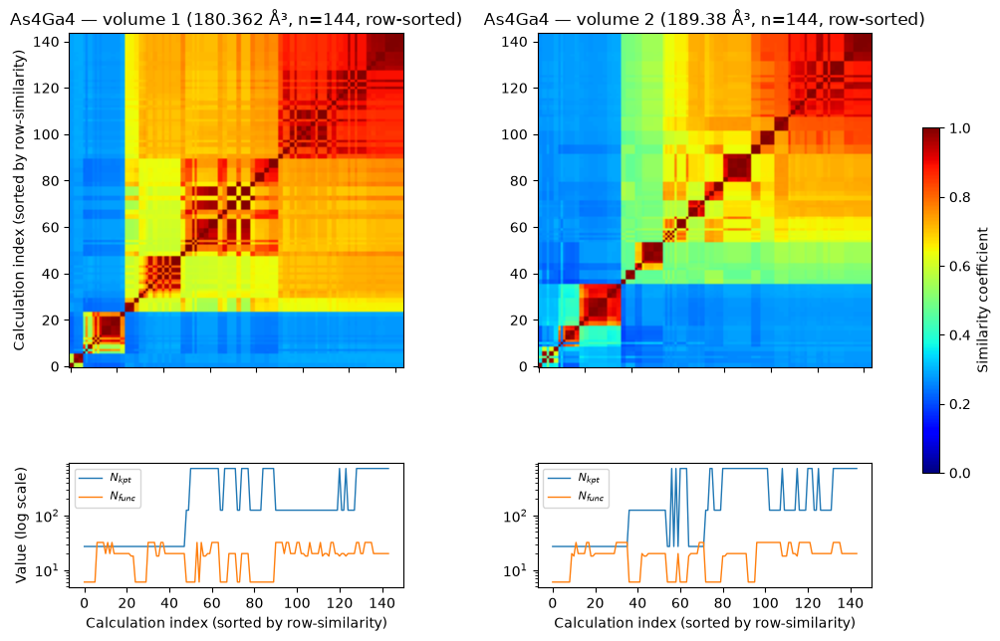

Saved: True

Material: As6   (formula: As6, 6 atoms/cell)
Cell: a=3.88 b=3.88 c=10.97 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:27:08,103 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/As6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [136.392, 143.212, 150.372]


  0%|          | 0/319 [00:00<?, ?it/s]

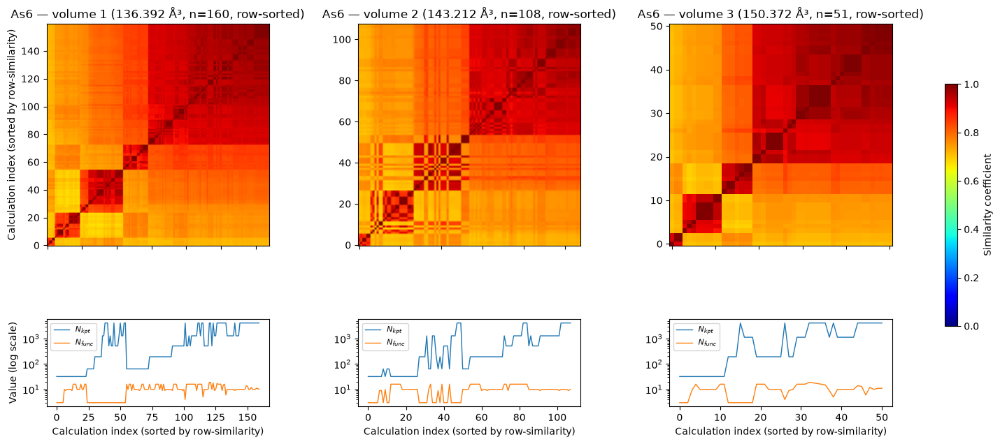

Saved: True

Material: Au4   (formula: Au4, 4 atoms/cell)
Cell: a=4.17 b=4.17 c=4.17 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:27:15,276 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Au4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [72.726, 76.362]


  0%|          | 0/321 [00:00<?, ?it/s]

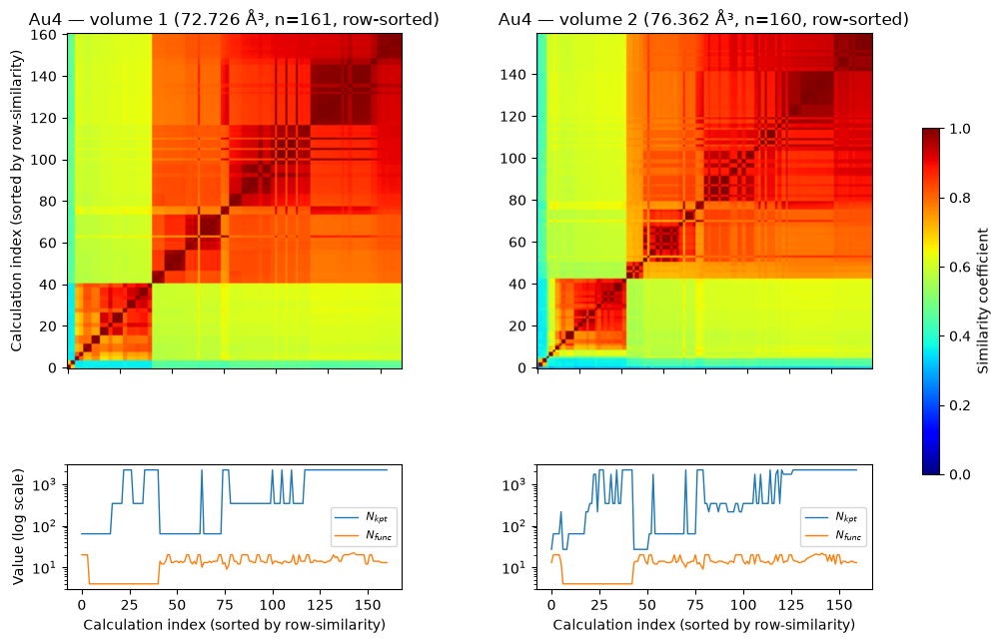

Saved: True

Material: Au4S2   (formula: Au4S2, 6 atoms/cell)
Cell: a=5.10 b=5.10 c=5.10 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:27:20,916 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Au4S2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [126.506, 132.831]


  0%|          | 0/288 [00:00<?, ?it/s]

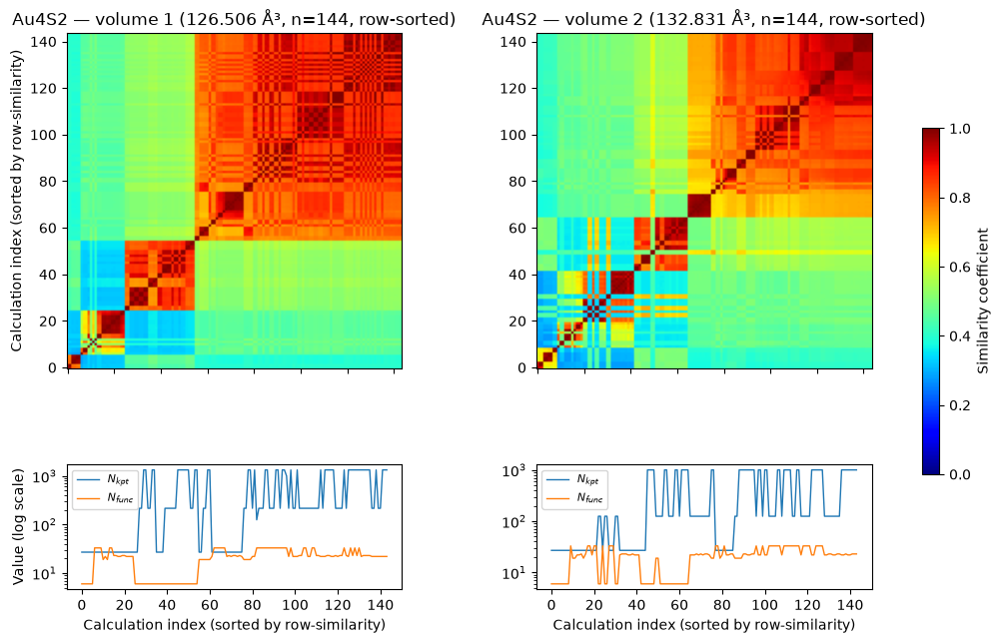

Saved: True

Material: B12   (formula: B12, 12 atoms/cell)
Cell: a=4.98 b=4.98 c=5.13 Å, α=119.0 β=61.0 γ=120.0°


2026-09-06 15:27:26,121 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/B12_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [87.025, 91.377, 95.946]


  0%|          | 0/323 [00:00<?, ?it/s]

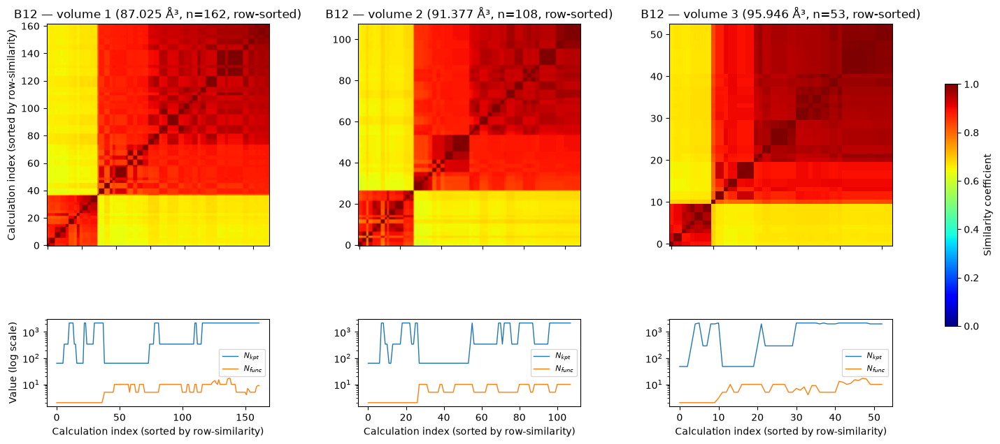

Saved: True

Material: B2N2   (formula: B2N2, 4 atoms/cell)
Cell: a=2.49 b=2.48 c=6.49 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:27:32,742 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/B2N2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [34.708, 36.443]


  0%|          | 0/288 [00:00<?, ?it/s]

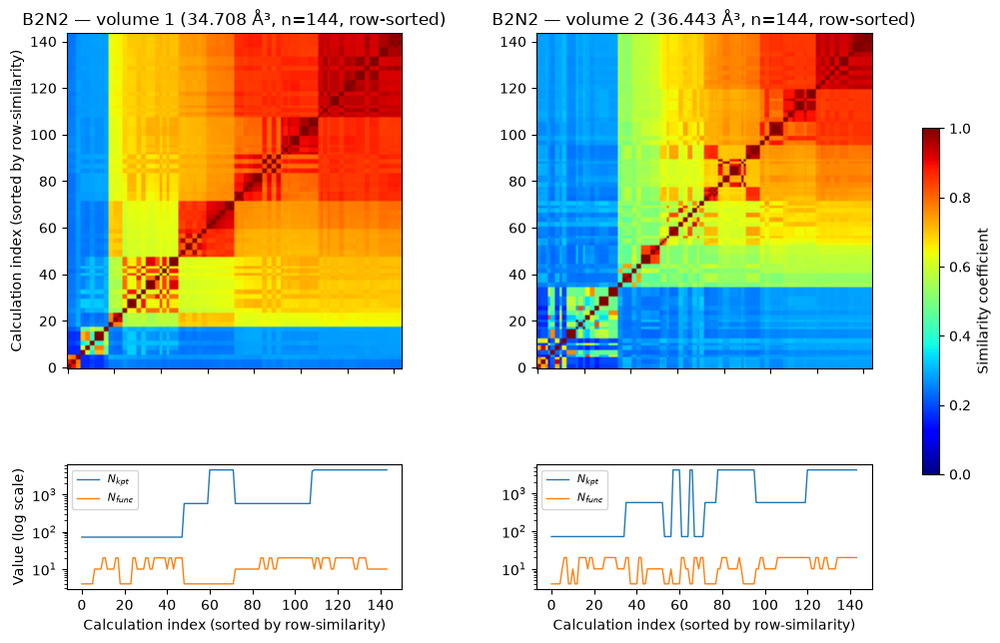

Saved: True

Material: BCoV2   (formula: BCoV2, 4 atoms/cell)
Cell: a=3.93 b=3.93 c=3.93 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:27:37,245 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/BCoV2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [42.833]


  0%|          | 0/144 [00:00<?, ?it/s]

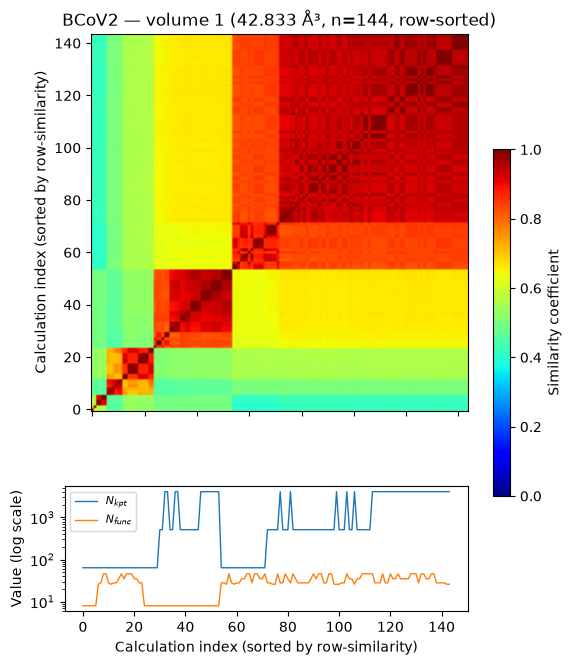

Saved: True

Material: BOs   (formula: BOs, 2 atoms/cell)
Cell: a=2.92 b=2.92 c=2.92 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:27:41,074 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/BOs_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [20.581, 21.61]


  0%|          | 0/288 [00:00<?, ?it/s]

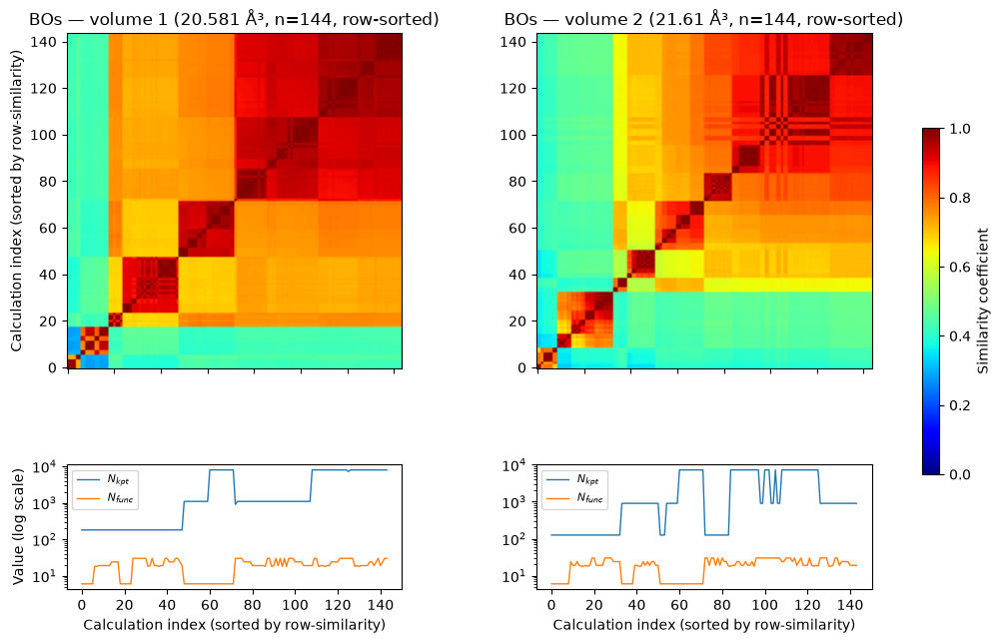

Saved: True

Material: Ba4O4   (formula: Ba4O4, 8 atoms/cell)
Cell: a=5.25 b=5.25 c=5.25 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:27:46,352 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ba4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [144.703, 151.938]


  0%|          | 0/288 [00:00<?, ?it/s]

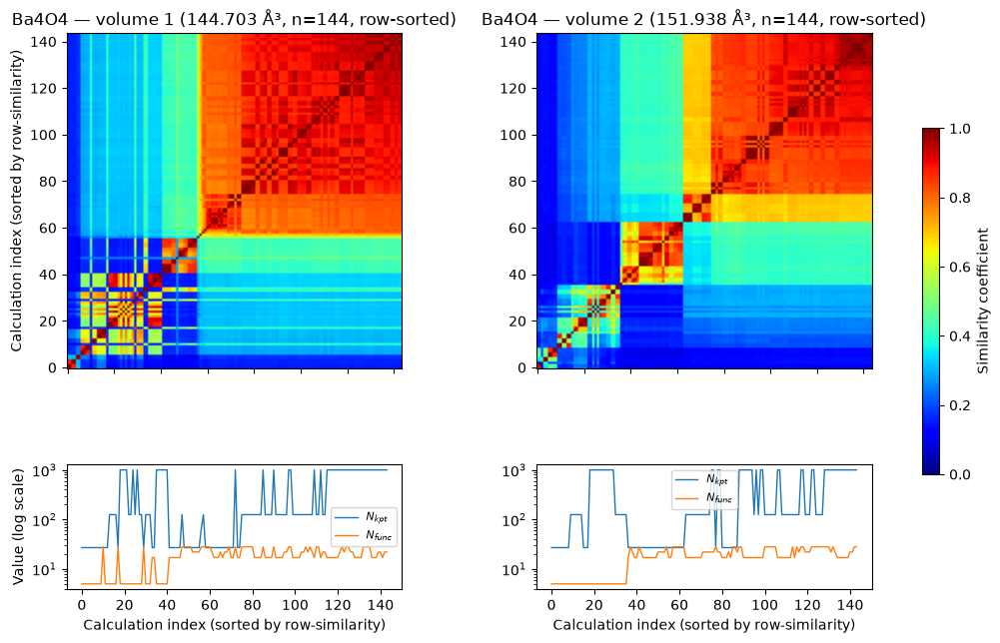

Saved: True

Material: BaK2Li   (formula: BaK2Li, 4 atoms/cell)
Cell: a=6.82 b=6.82 c=6.82 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:27:50,984 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/BaK2Li_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [224.515]


  0%|          | 0/144 [00:00<?, ?it/s]

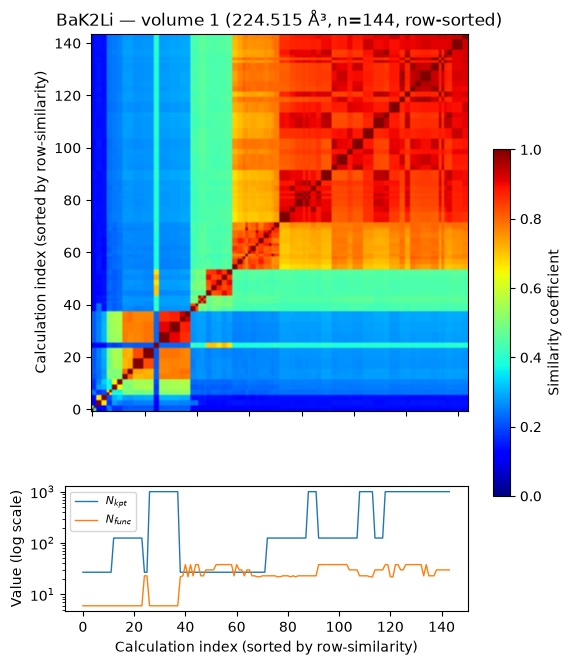

Saved: True

Material: Be4S4   (formula: Be4S4, 8 atoms/cell)
Cell: a=4.88 b=4.88 c=4.88 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [116.429, 122.25]


2026-09-06 15:27:54,525 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Be4S4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

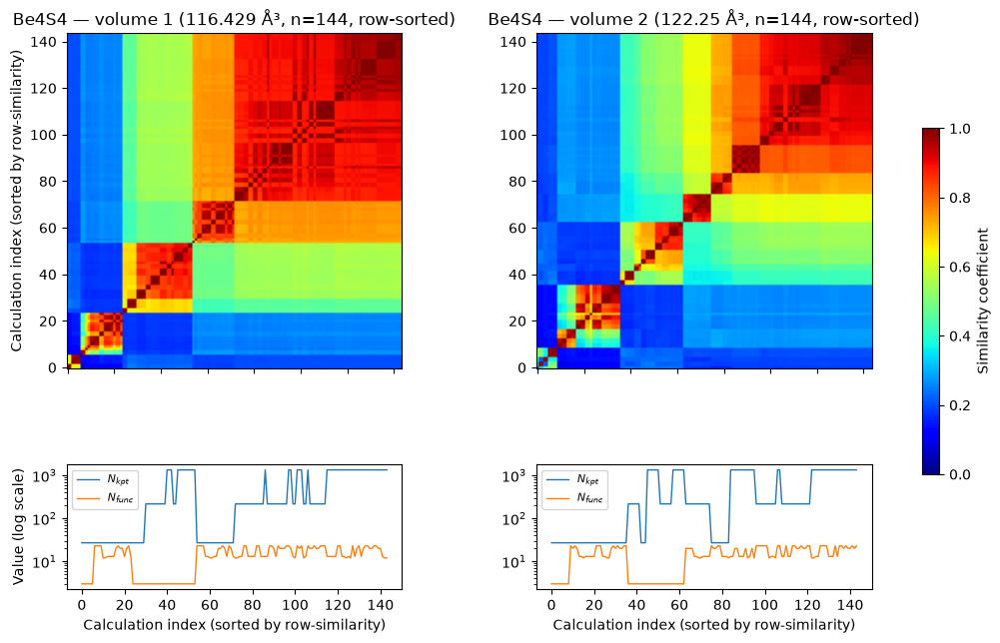

Saved: True

Material: Bi4F12   (formula: Bi4F12, 16 atoms/cell)
Cell: a=5.95 b=5.95 c=5.95 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:27:59,488 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Bi4F12_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [200.51, 210.535]


  0%|          | 0/288 [00:00<?, ?it/s]

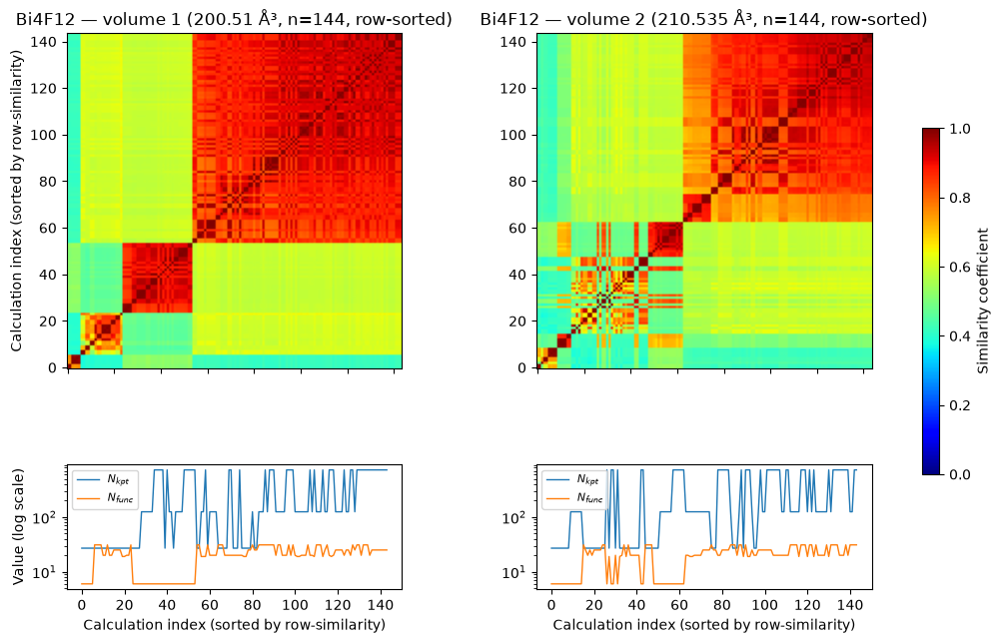

Saved: True

Material: Bi6   (formula: Bi6, 6 atoms/cell)
Cell: a=4.74 b=4.74 c=12.58 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:28:05,728 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Bi6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [222.141, 233.248, 244.911]


  0%|          | 0/321 [00:00<?, ?it/s]

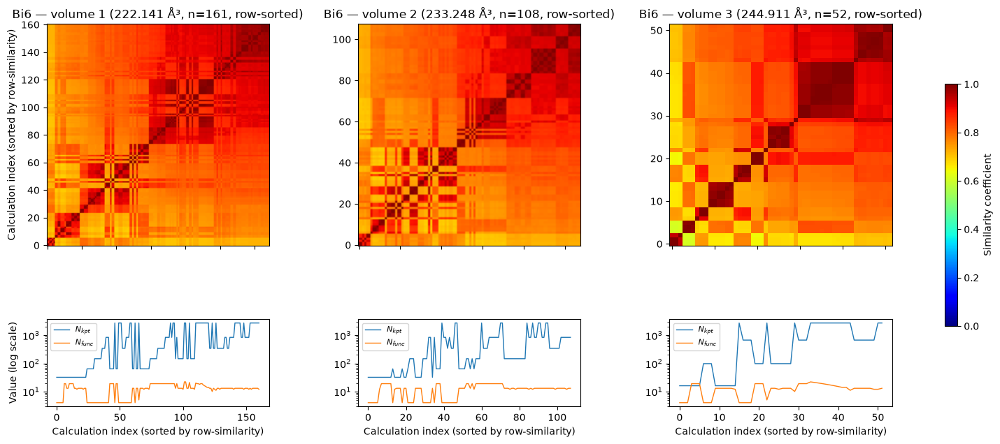

Saved: True

Material: Br4Cu4   (formula: Br4Cu4, 8 atoms/cell)
Cell: a=5.82 b=5.82 c=5.82 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:10,830 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Br4Cu4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [197.137, 206.994]


  0%|          | 0/288 [00:00<?, ?it/s]

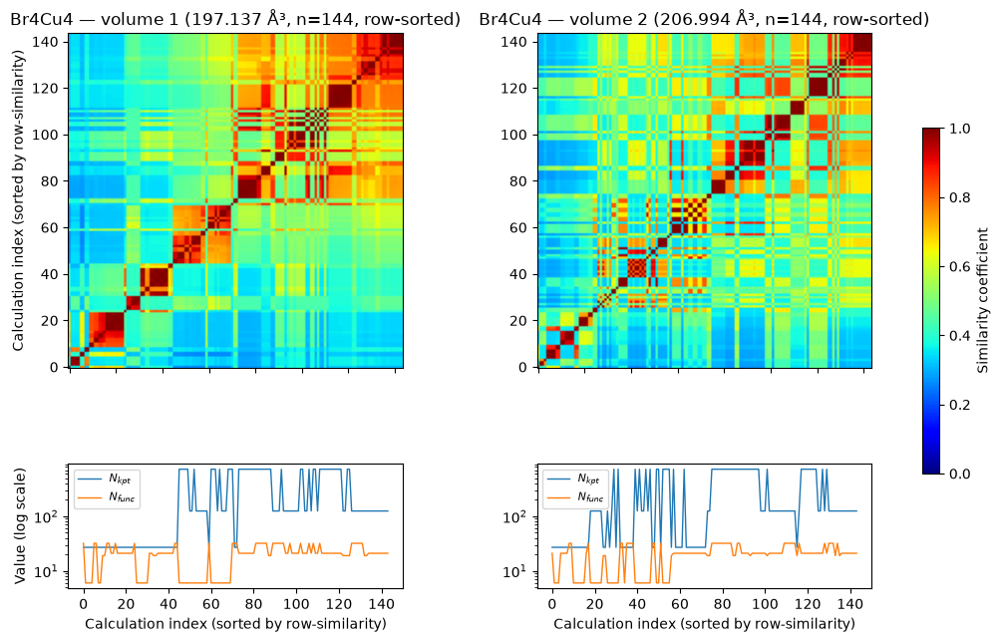

Saved: True

Material: Br4K4   (formula: Br4K4, 8 atoms/cell)
Cell: a=6.69 b=6.69 c=6.69 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:16,238 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Br4K4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [284.631, 298.862]


  0%|          | 0/288 [00:00<?, ?it/s]

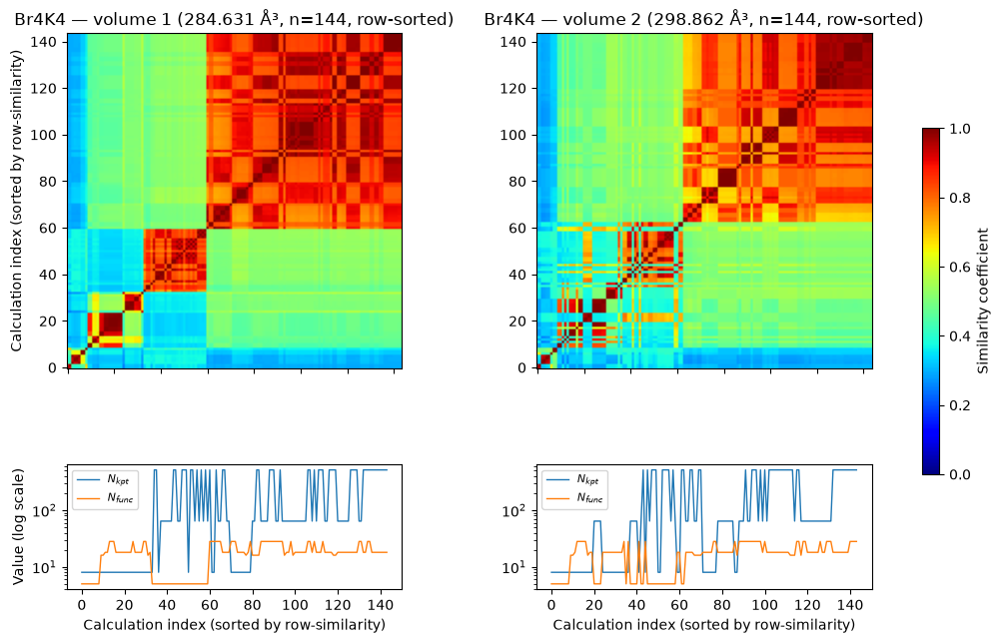

Saved: True

Material: Br8   (formula: Br8, 8 atoms/cell)
Cell: a=8.36 b=4.30 c=9.18 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:20,861 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Br8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [314.219, 329.93]


  0%|          | 0/321 [00:00<?, ?it/s]

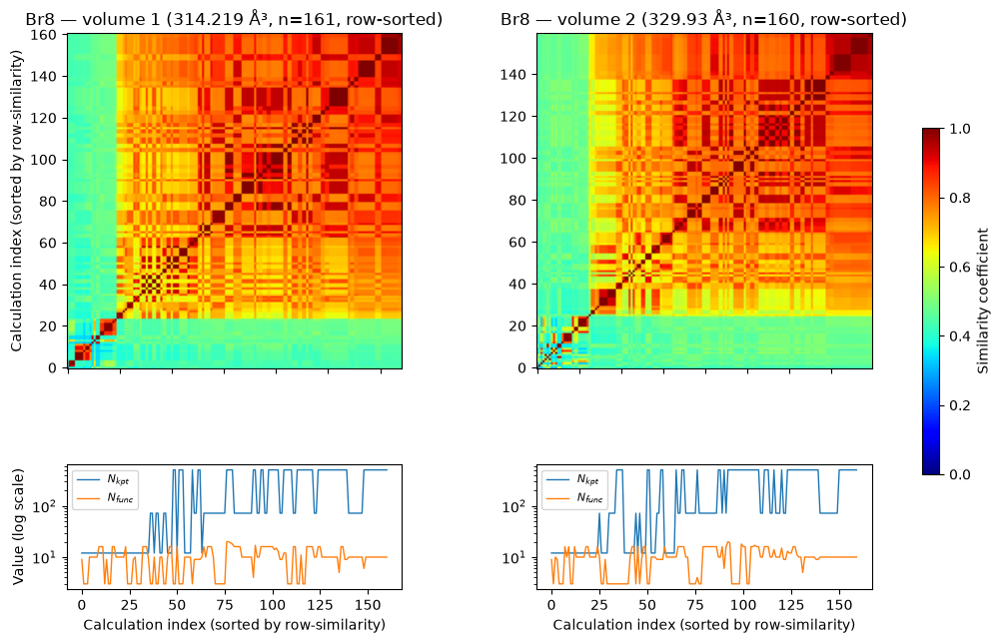

Saved: True

Material: C4   (formula: C4, 4 atoms/cell)
Cell: a=2.47 b=2.47 c=8.84 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:28:26,444 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [46.657, 48.989]


  0%|          | 0/325 [00:00<?, ?it/s]

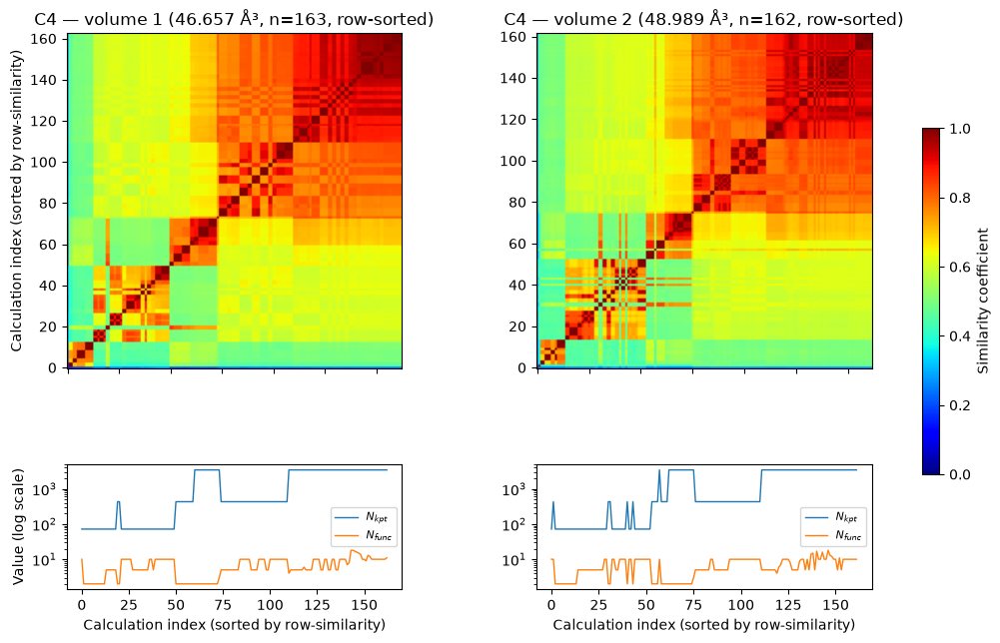

Saved: True

Material: C4Hf4   (formula: C4Hf4, 8 atoms/cell)
Cell: a=4.71 b=4.71 c=4.71 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [99.446, 104.418]


2026-09-06 15:28:31,941 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Hf4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

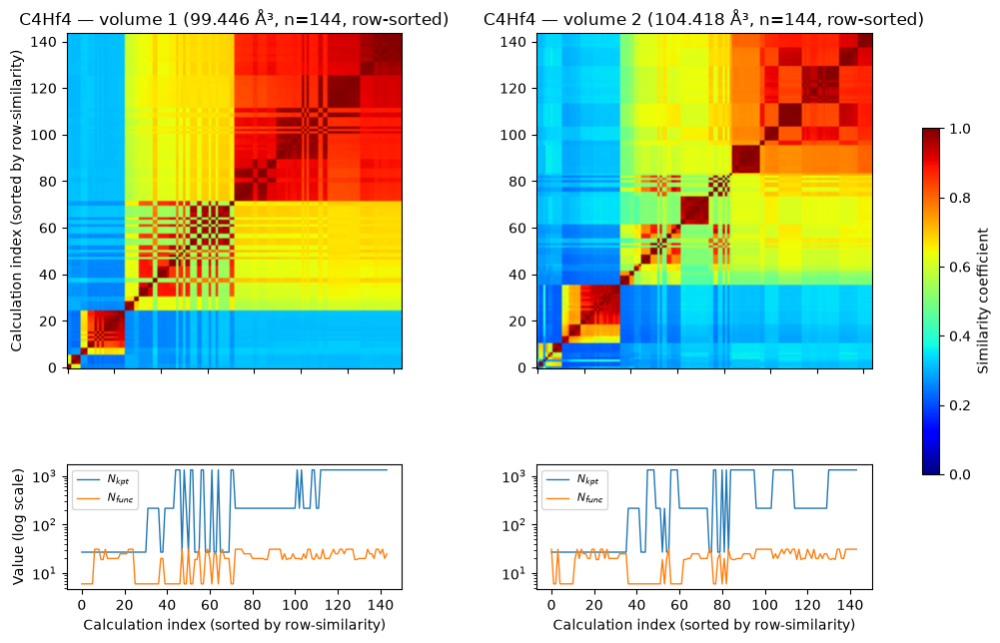

Saved: True

Material: C4Nb4   (formula: C4Nb4, 8 atoms/cell)
Cell: a=4.45 b=4.45 c=4.45 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:37,188 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Nb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [88.383, 92.802]


  0%|          | 0/288 [00:00<?, ?it/s]

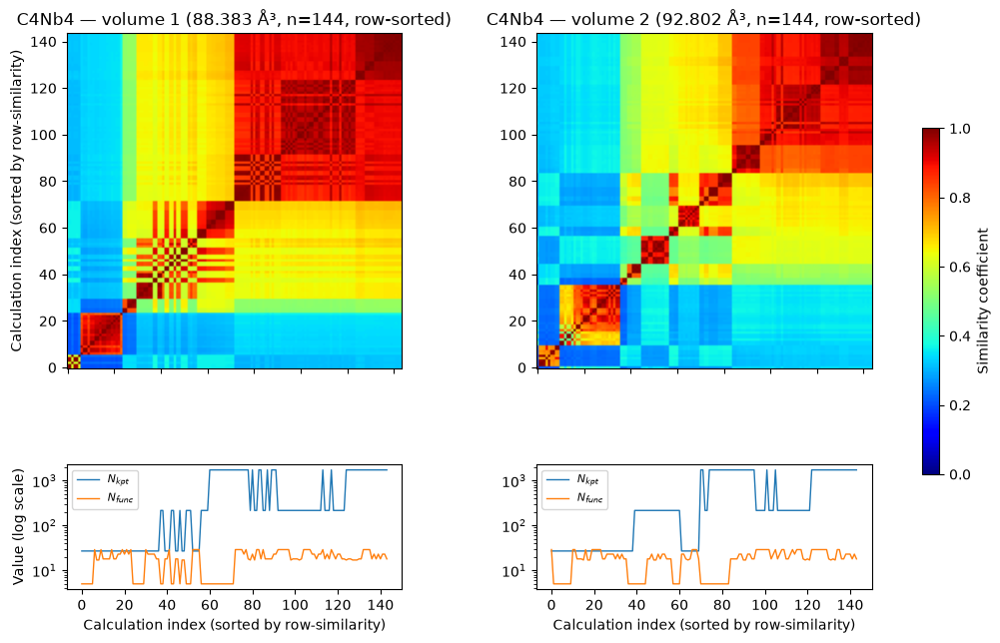

Saved: True

Material: C4Si4   (formula: C4Si4, 8 atoms/cell)
Cell: a=4.36 b=4.36 c=4.36 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:41,799 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Si4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [82.831, 86.972]


  0%|          | 0/288 [00:00<?, ?it/s]

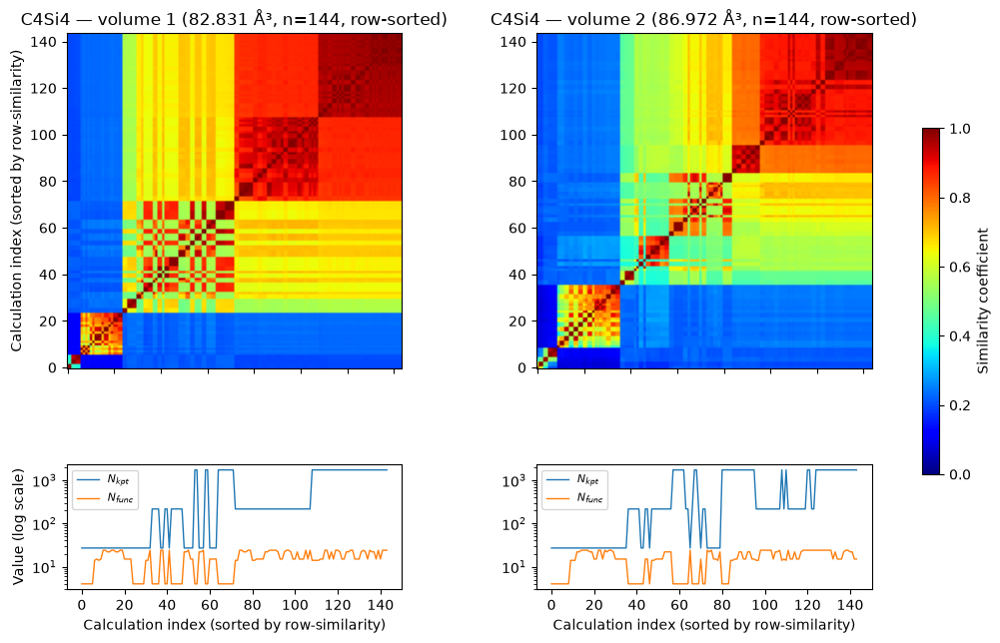

Saved: True

Material: C4Ta4   (formula: C4Ta4, 8 atoms/cell)
Cell: a=4.45 b=4.45 c=4.45 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:47,330 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Ta4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [88.299, 92.714]


  0%|          | 0/288 [00:00<?, ?it/s]

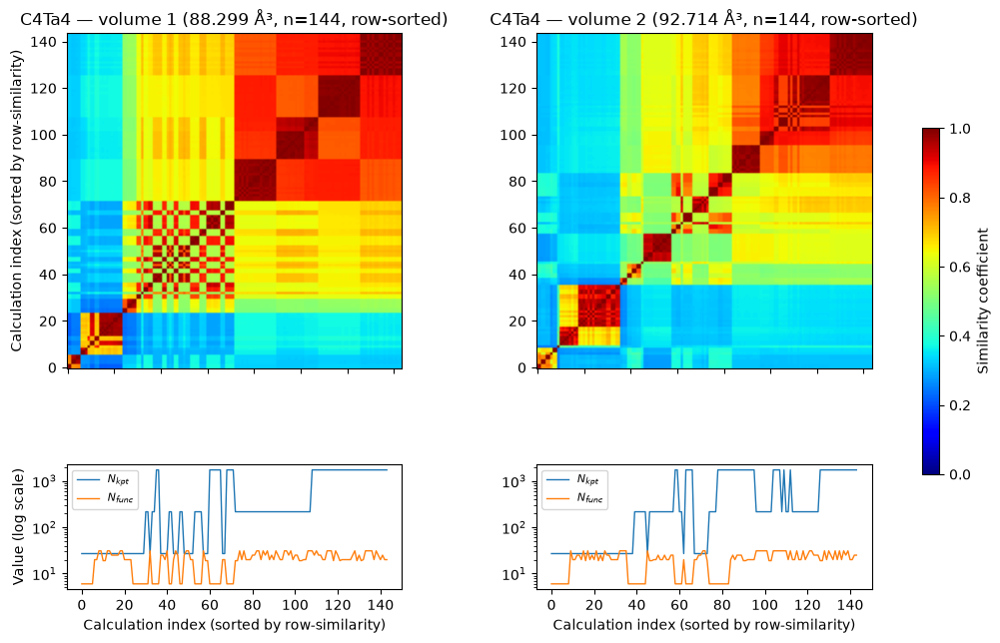

Saved: True

Material: C4Th4   (formula: C4Th4, 8 atoms/cell)
Cell: a=5.43 b=5.43 c=5.43 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:52,724 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Th4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [152.273, 159.887]


  0%|          | 0/288 [00:00<?, ?it/s]

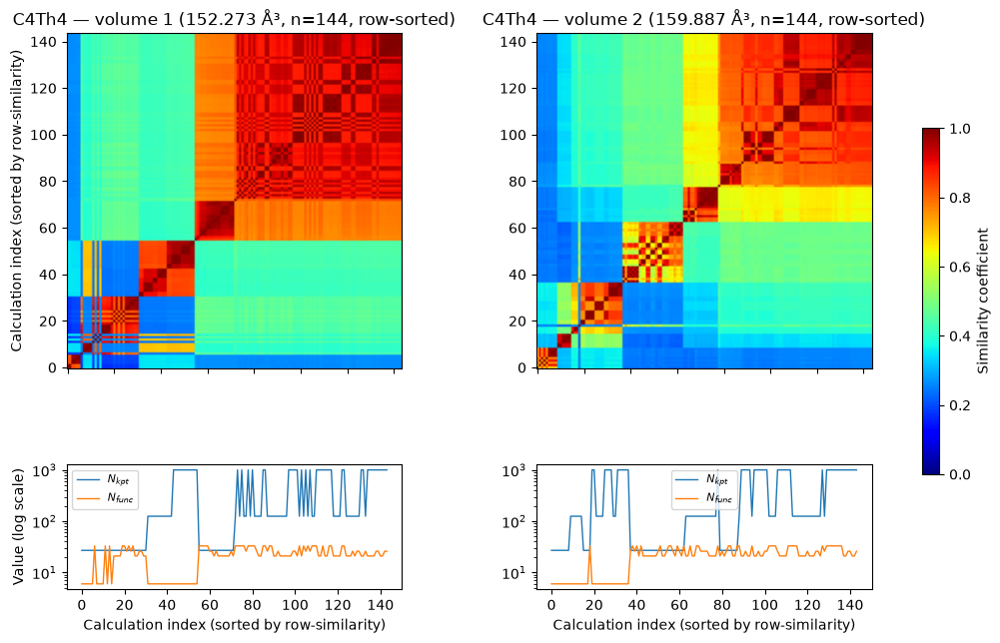

Saved: True

Material: C4Ti4   (formula: C4Ti4, 8 atoms/cell)
Cell: a=4.41 b=4.41 c=4.41 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:28:57,618 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Ti4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [81.408, 85.478]


  0%|          | 0/288 [00:00<?, ?it/s]

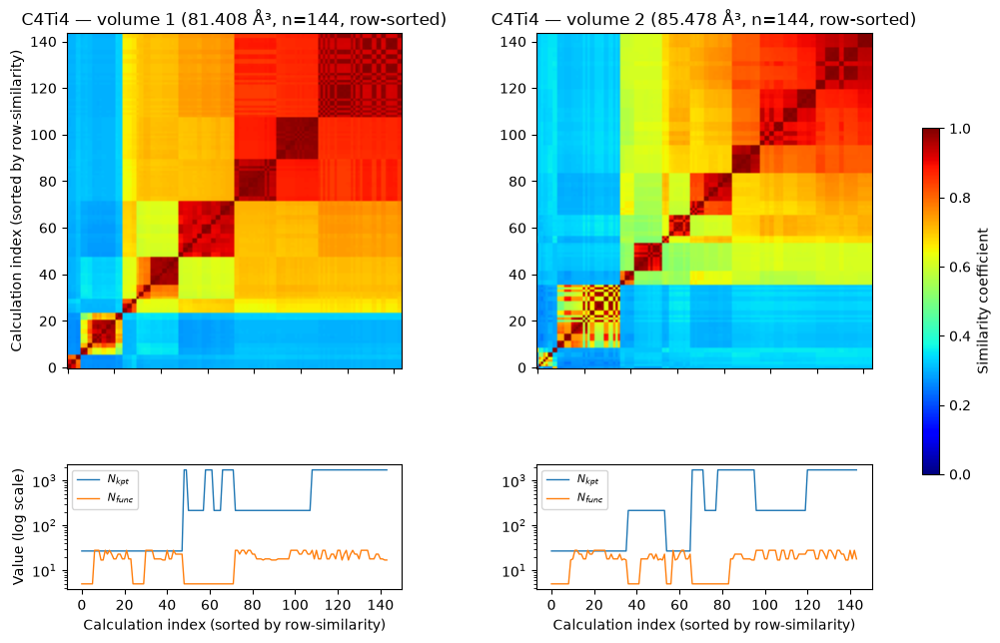

Saved: True

Material: C4V4   (formula: C4V4, 8 atoms/cell)
Cell: a=4.17 b=4.17 c=4.17 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:02,306 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4V4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [72.355, 75.973]


  0%|          | 0/288 [00:00<?, ?it/s]

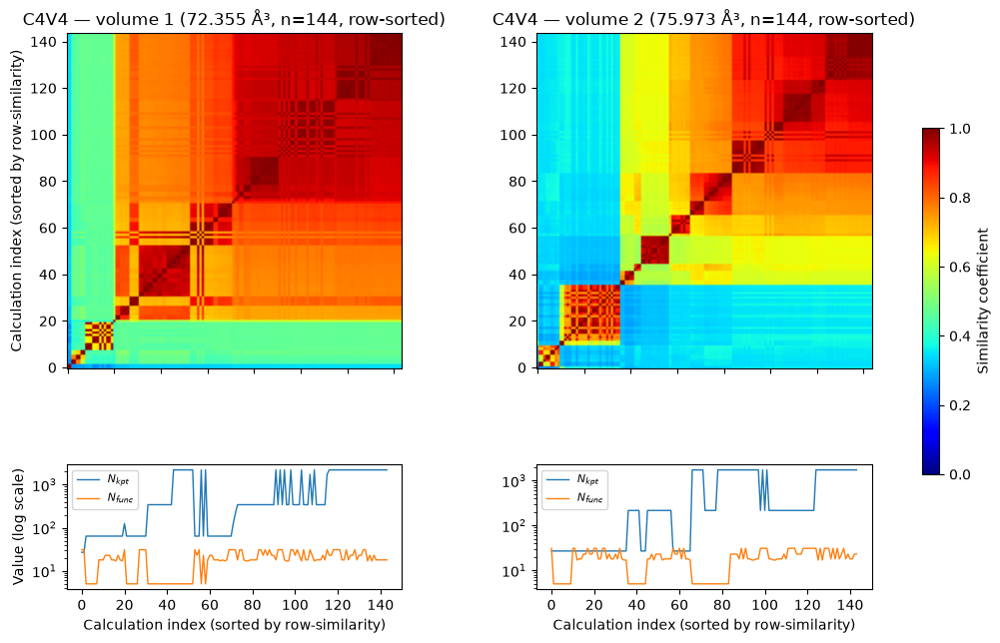

Saved: True

Material: C4Zr4   (formula: C4Zr4, 8 atoms/cell)
Cell: a=4.70 b=4.70 c=4.70 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:07,100 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/C4Zr4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [103.558, 108.736]


  0%|          | 0/288 [00:00<?, ?it/s]

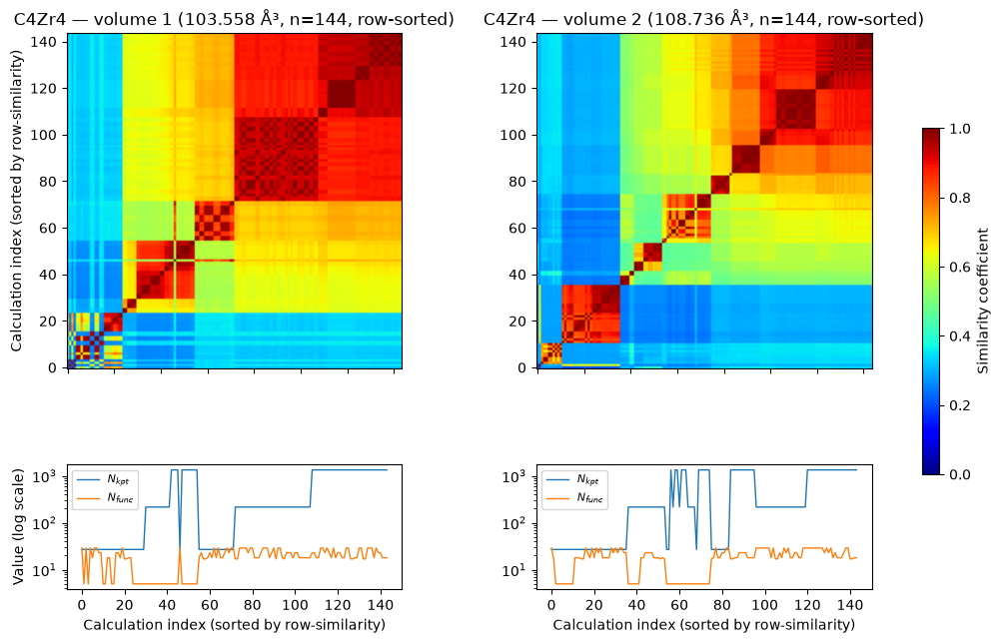

Saved: True

Material: CMo   (formula: CMo, 2 atoms/cell)
Cell: a=2.95 b=2.95 c=2.88 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:29:12,523 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/CMo_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [20.612, 21.642]


  0%|          | 0/288 [00:00<?, ?it/s]

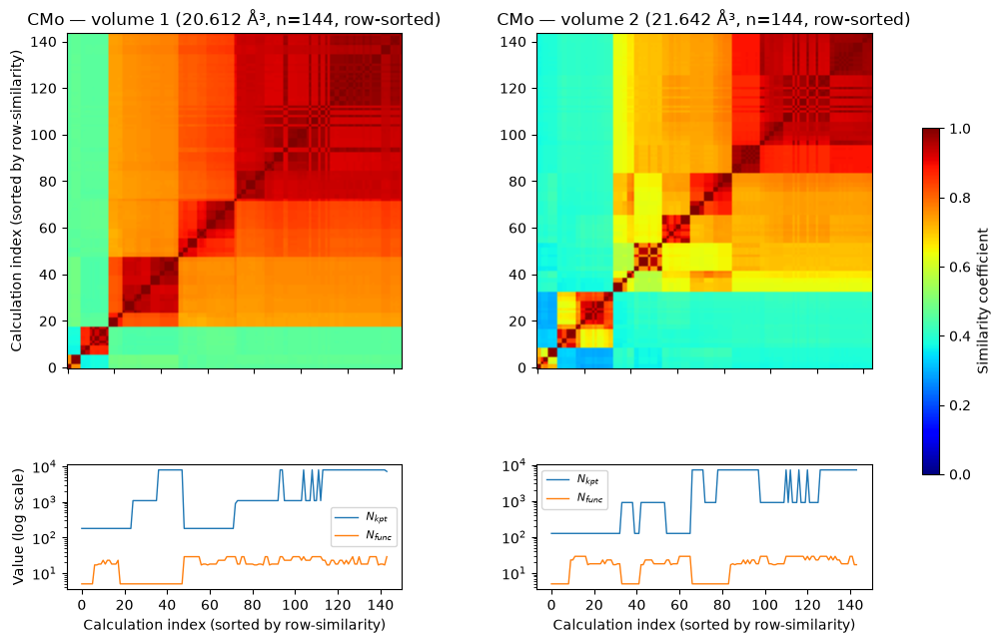

Saved: True

Material: CO3Ru   (formula: CO3Ru, 5 atoms/cell)
Cell: a=3.52 b=3.52 c=3.52 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:16,824 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/CO3Ru_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [43.786]


  0%|          | 0/144 [00:00<?, ?it/s]

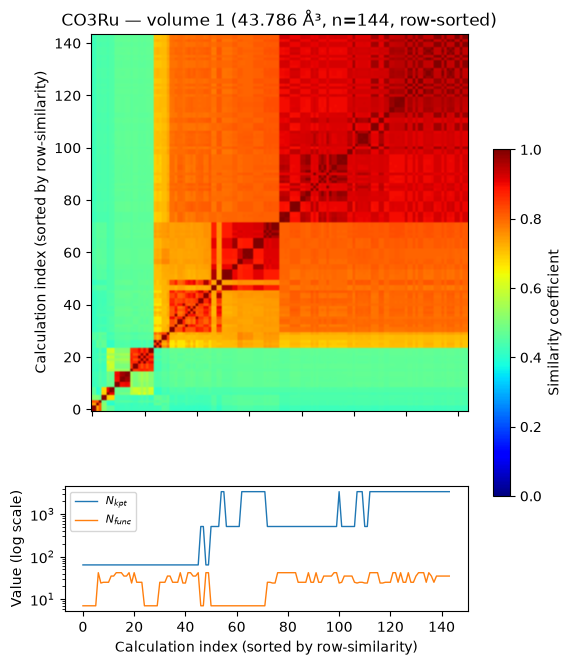

Saved: True

Material: CW   (formula: CW, 2 atoms/cell)
Cell: a=2.89 b=2.89 c=2.84 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:29:20,473 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/CW_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [20.537, 21.563]


  0%|          | 0/288 [00:00<?, ?it/s]

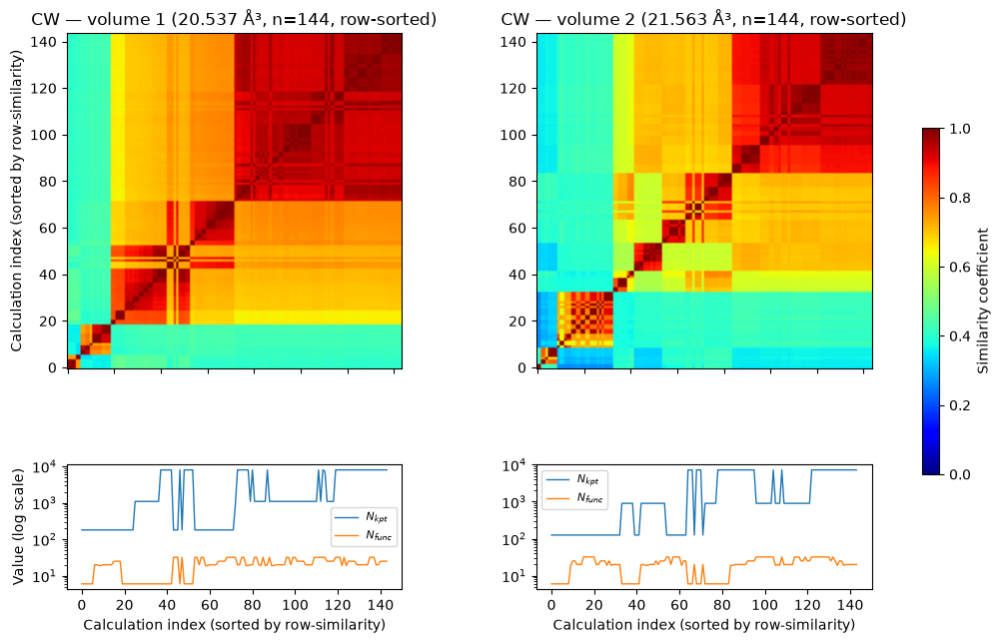

Saved: True

Material: Ca2CdP   (formula: Ca2CdP, 4 atoms/cell)
Cell: a=5.26 b=5.26 c=5.26 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:29:25,296 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ca2CdP_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [102.892]


  0%|          | 0/144 [00:00<?, ?it/s]

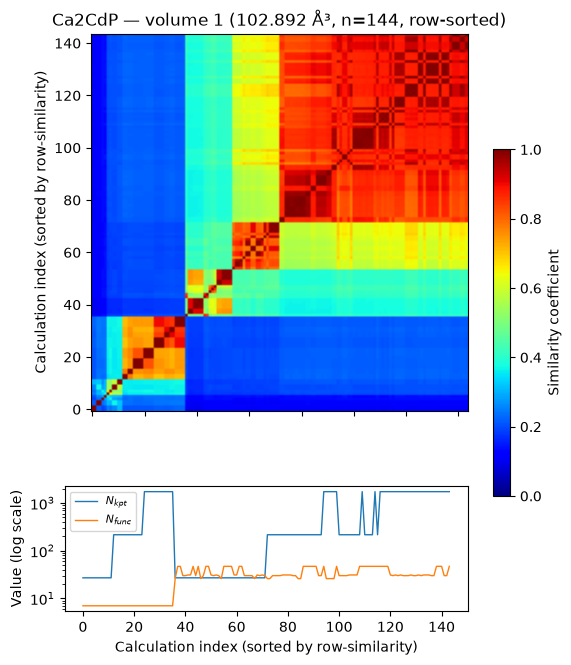

Saved: True

Material: Ca4O4   (formula: Ca4O4, 8 atoms/cell)
Cell: a=4.89 b=4.89 c=4.89 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [111.354, 116.922]


2026-09-06 15:29:28,297 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ca4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

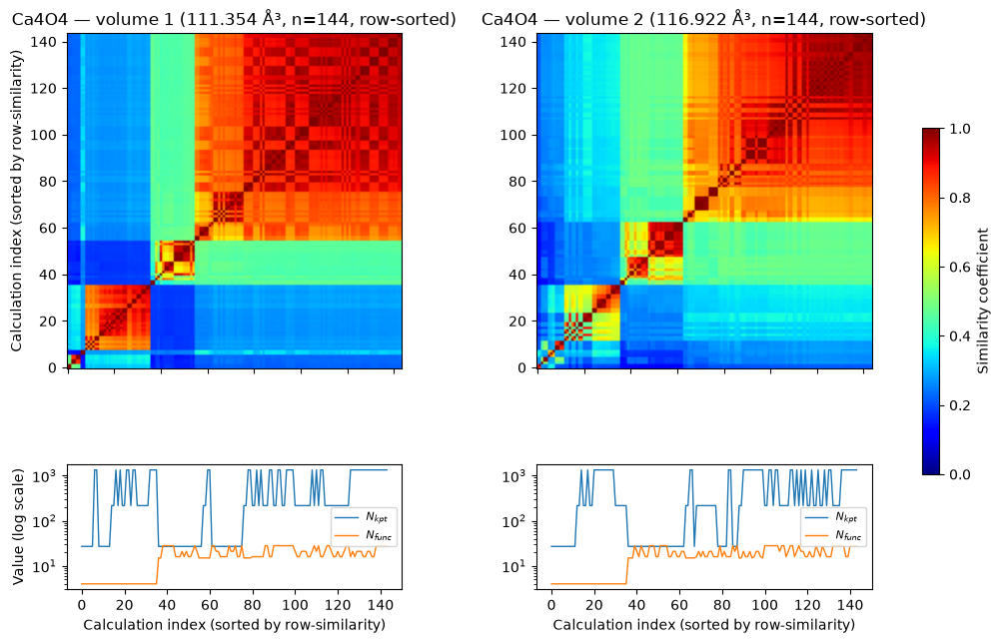

Saved: True

Material: Cd2Se2   (formula: Cd2Se2, 4 atoms/cell)
Cell: a=4.37 b=4.37 c=7.13 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:29:33,207 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cd2Se2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [112.547, 118.174]


  0%|          | 0/288 [00:00<?, ?it/s]

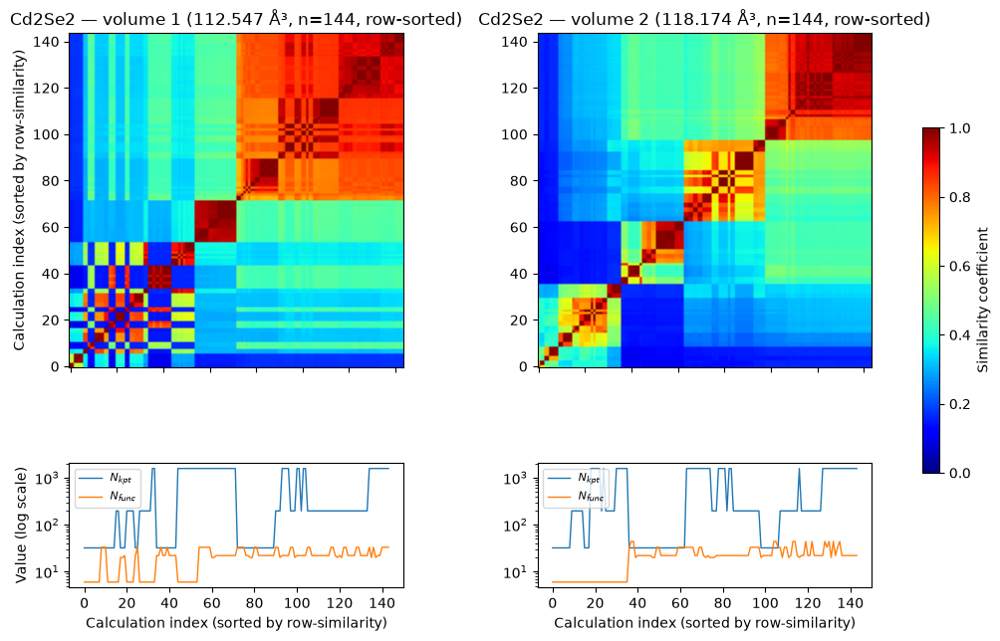

Saved: True

Material: Cd4O4   (formula: Cd4O4, 8 atoms/cell)
Cell: a=4.77 b=4.77 c=4.77 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:41,549 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cd4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [103.466, 108.639]


  0%|          | 0/576 [00:00<?, ?it/s]

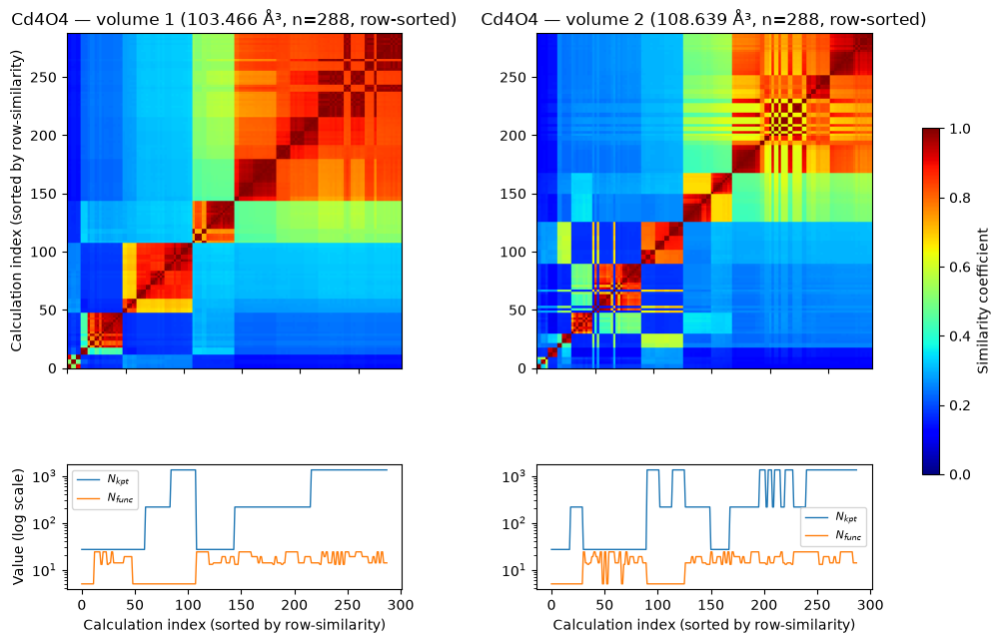

Saved: True

Material: Ce4N4   (formula: Ce4N4, 8 atoms/cell)
Cell: a=5.10 b=5.10 c=5.10 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:50,488 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ce4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [126.506, 132.831]


  0%|          | 0/288 [00:00<?, ?it/s]

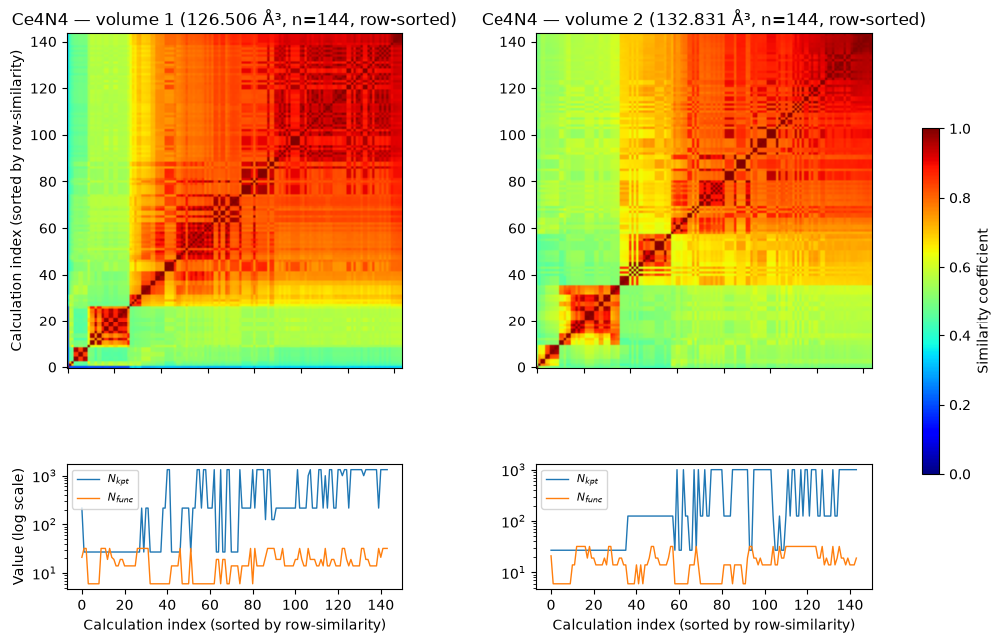

Saved: True

Material: Cl4Cu4   (formula: Cl4Cu4, 8 atoms/cell)
Cell: a=5.50 b=5.50 c=5.50 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:29:55,360 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl4Cu4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [158.077, 165.981]


  0%|          | 0/288 [00:00<?, ?it/s]

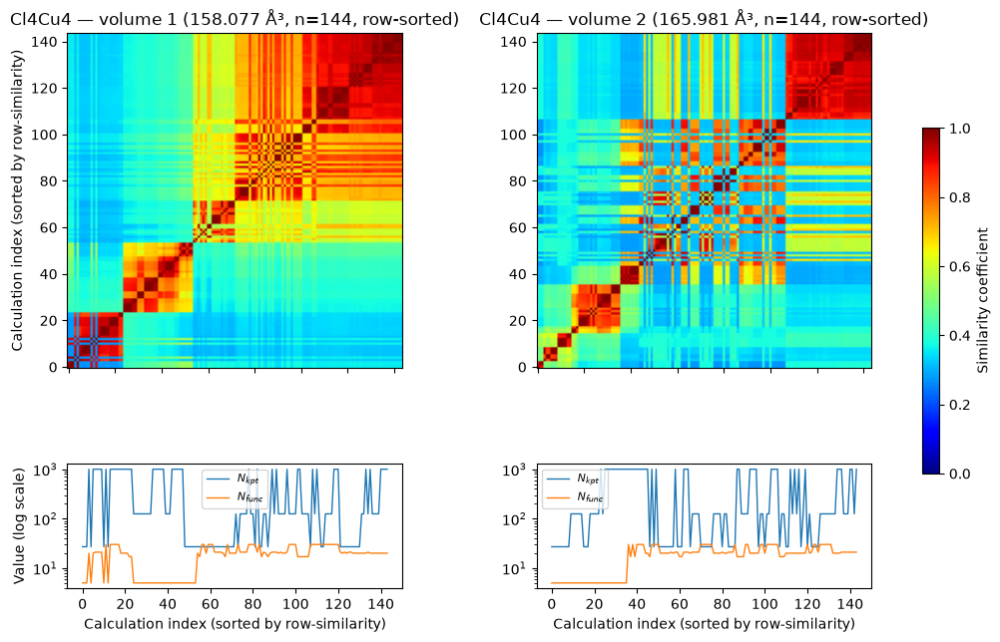

Saved: True

Material: Cl4K4   (formula: Cl4K4, 8 atoms/cell)
Cell: a=6.39 b=6.39 c=6.39 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:01,501 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl4K4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [249.048, 261.501]


  0%|          | 0/288 [00:00<?, ?it/s]

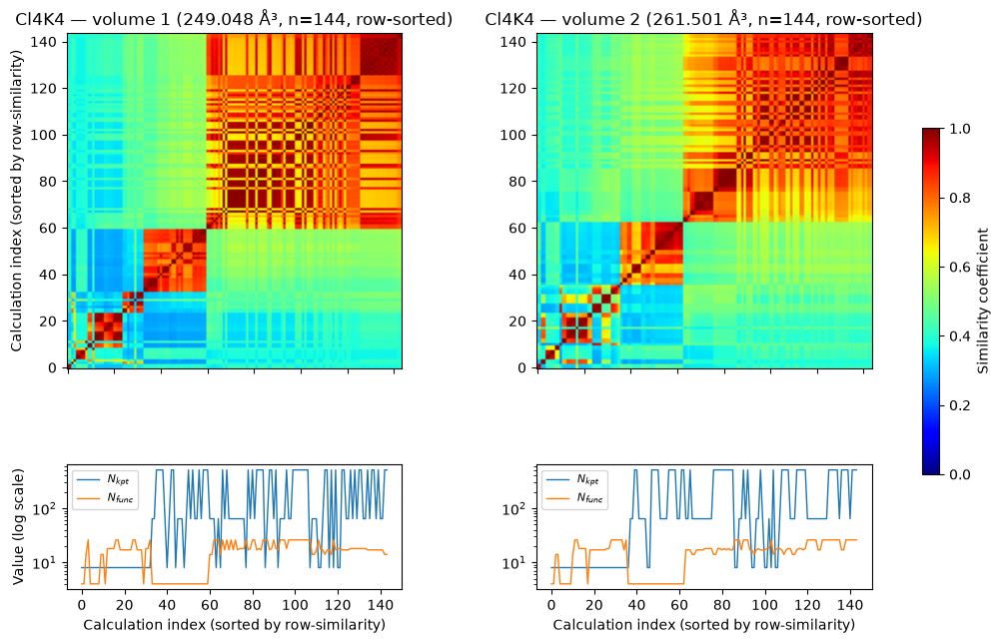

Saved: True

Material: Cl4Na4   (formula: Cl4Na4, 8 atoms/cell)
Cell: a=5.64 b=5.64 c=5.64 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:06,580 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl4Na4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [179.425, 188.397]


  0%|          | 0/288 [00:00<?, ?it/s]

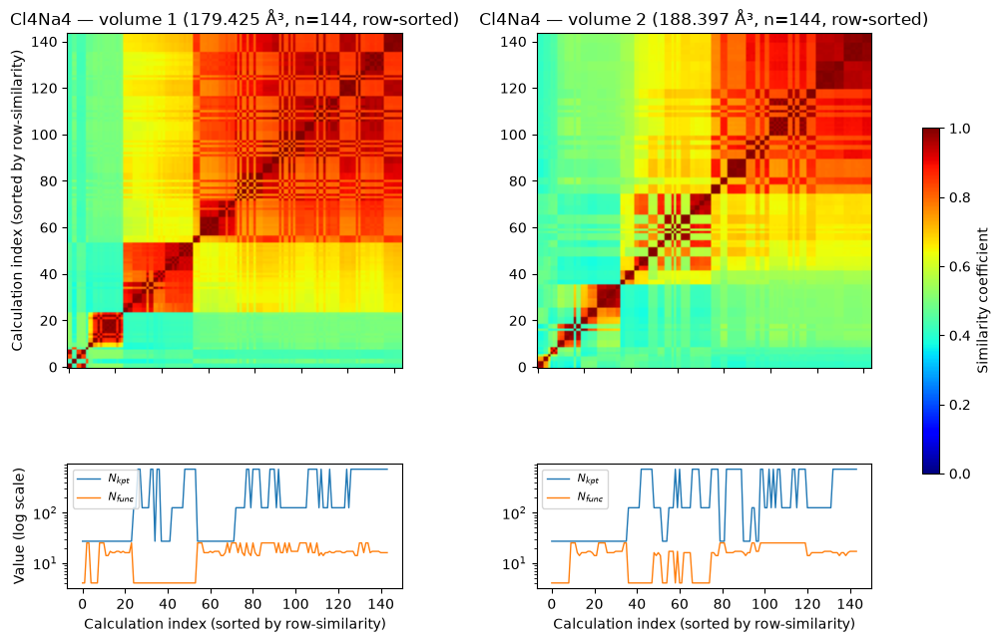

Saved: True

Material: Cl4Rb4   (formula: Cl4Rb4, 8 atoms/cell)
Cell: a=6.59 b=6.59 c=6.59 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:11,011 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl4Rb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [286.165, 300.473]


  0%|          | 0/288 [00:00<?, ?it/s]

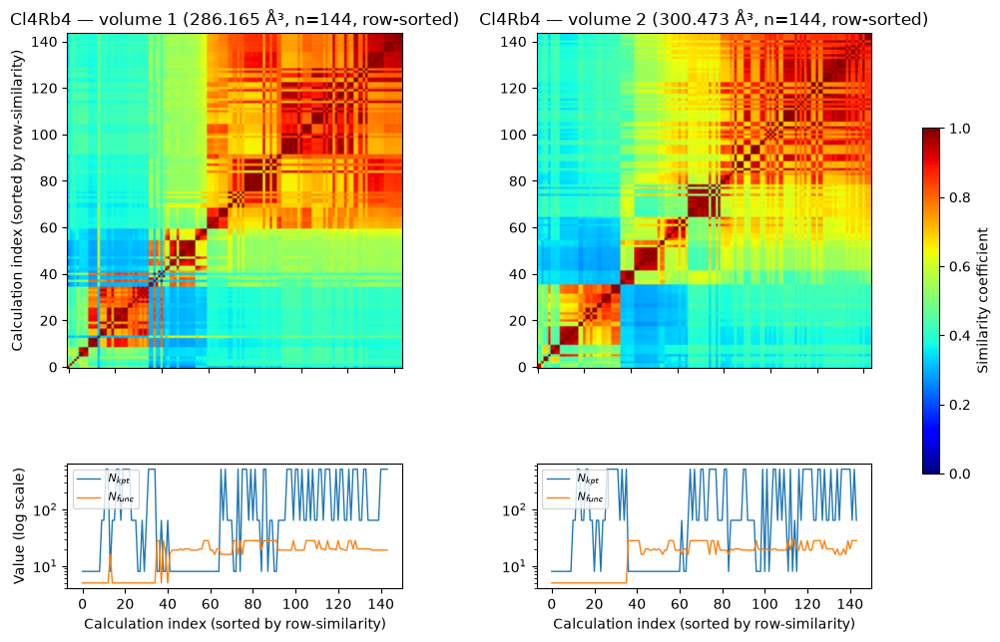

Saved: True

Material: Cl6La2   (formula: Cl6La2, 8 atoms/cell)
Cell: a=7.48 b=7.48 c=4.37 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:30:15,952 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl6La2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [211.845, 222.437]


  0%|          | 0/288 [00:00<?, ?it/s]

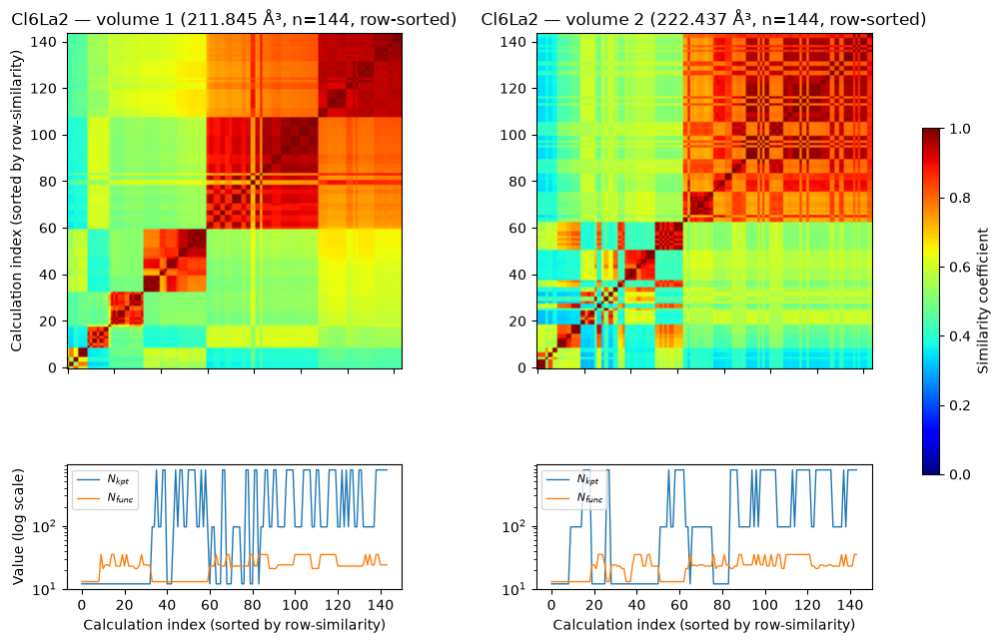

Saved: True

Material: Cl8   (formula: Cl8, 8 atoms/cell)
Cell: a=7.91 b=4.42 c=9.18 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:20,605 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cl8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [305.428, 320.7]


  0%|          | 0/329 [00:00<?, ?it/s]

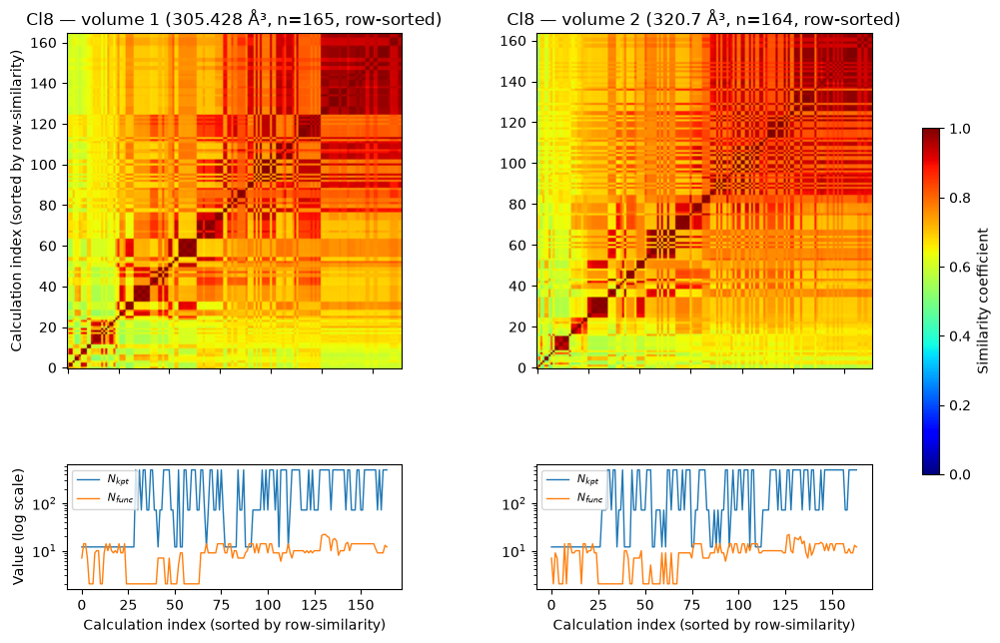

Saved: True

Material: ClCs   (formula: ClCs, 2 atoms/cell)
Cell: a=4.19 b=4.19 c=4.19 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [69.935, 73.431]


2026-09-06 15:30:25,830 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/ClCs_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

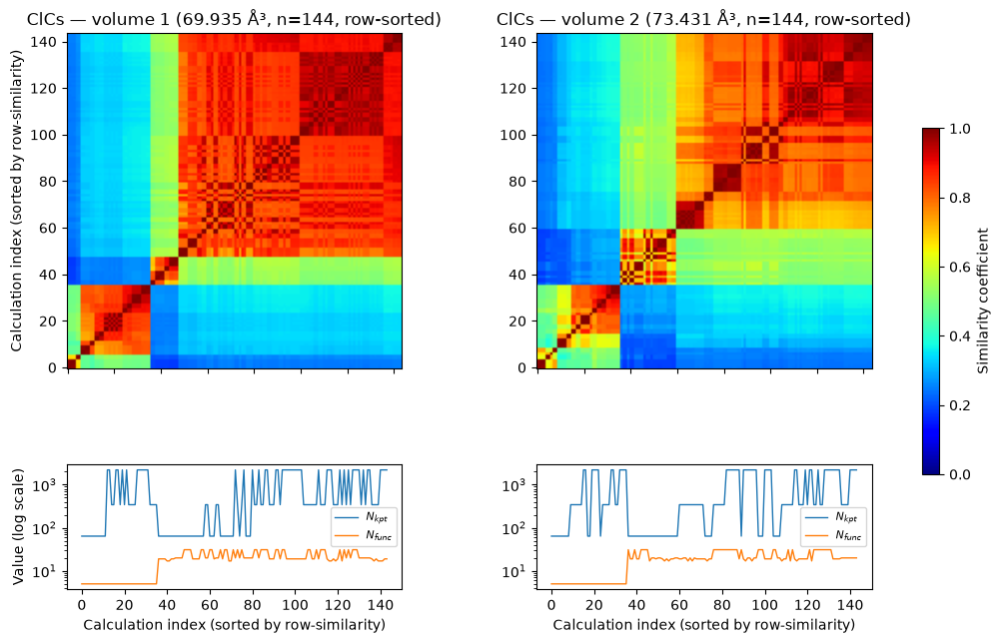

Saved: True

Material: ClLi2Sn   (formula: ClLi2Sn, 4 atoms/cell)
Cell: a=5.17 b=5.17 c=5.17 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:30:30,145 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/ClLi2Sn_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [97.675]


  0%|          | 0/144 [00:00<?, ?it/s]

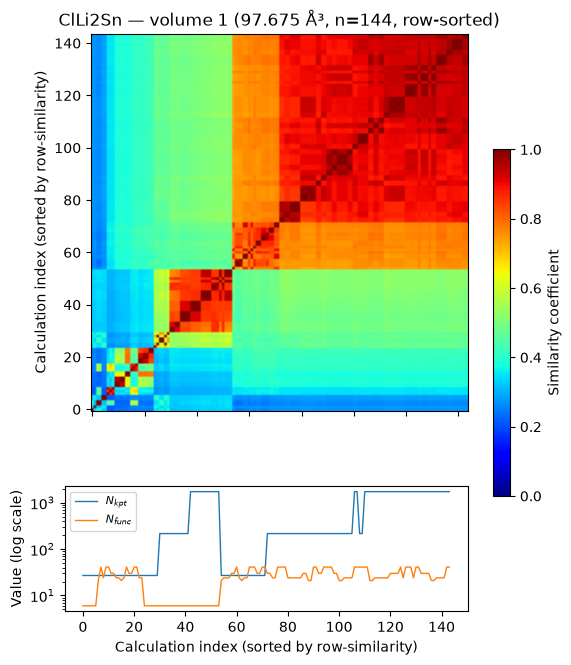

Saved: True

Material: ClTl   (formula: ClTl, 2 atoms/cell)
Cell: a=3.84 b=3.84 c=3.84 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:33,272 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/ClTl_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [56.694, 59.529]


  0%|          | 0/288 [00:00<?, ?it/s]

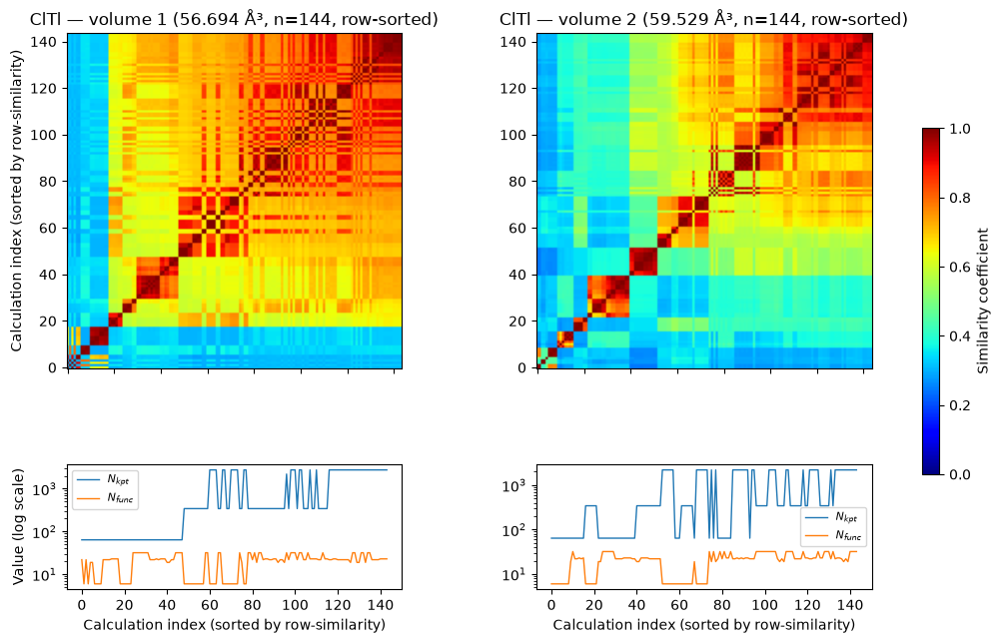

Saved: True

Material: Co2   (formula: Co2, 2 atoms/cell)
Cell: a=2.54 b=2.54 c=4.10 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:30:37,921 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Co2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [21.762, 22.85]


  0%|          | 0/325 [00:00<?, ?it/s]

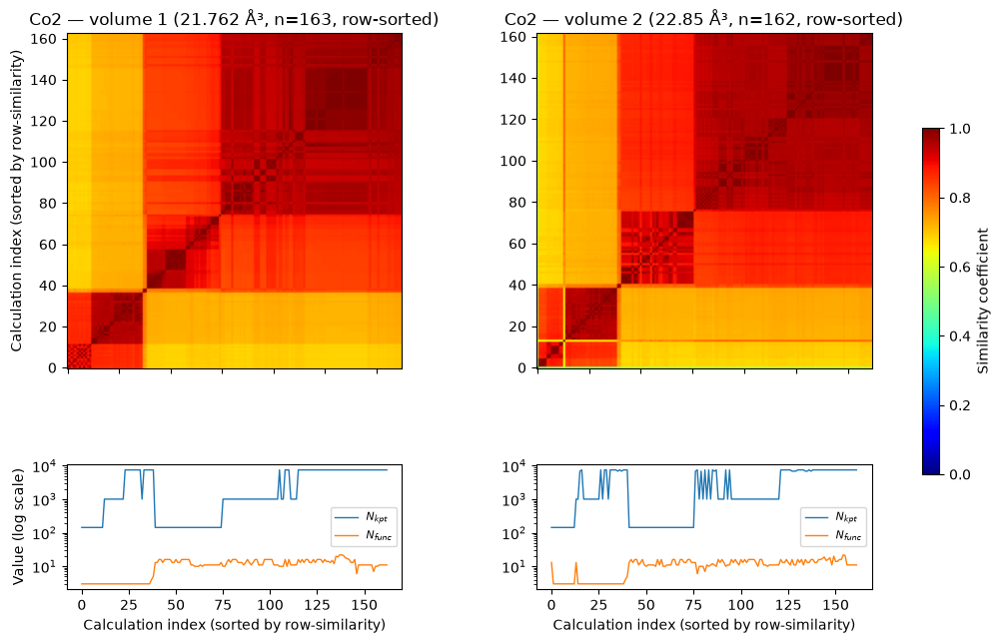

Saved: True

Material: Co4O4   (formula: Co4O4, 8 atoms/cell)
Cell: a=4.26 b=4.26 c=4.26 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:43,115 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Co4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [77.205, 81.066]


  0%|          | 0/288 [00:00<?, ?it/s]

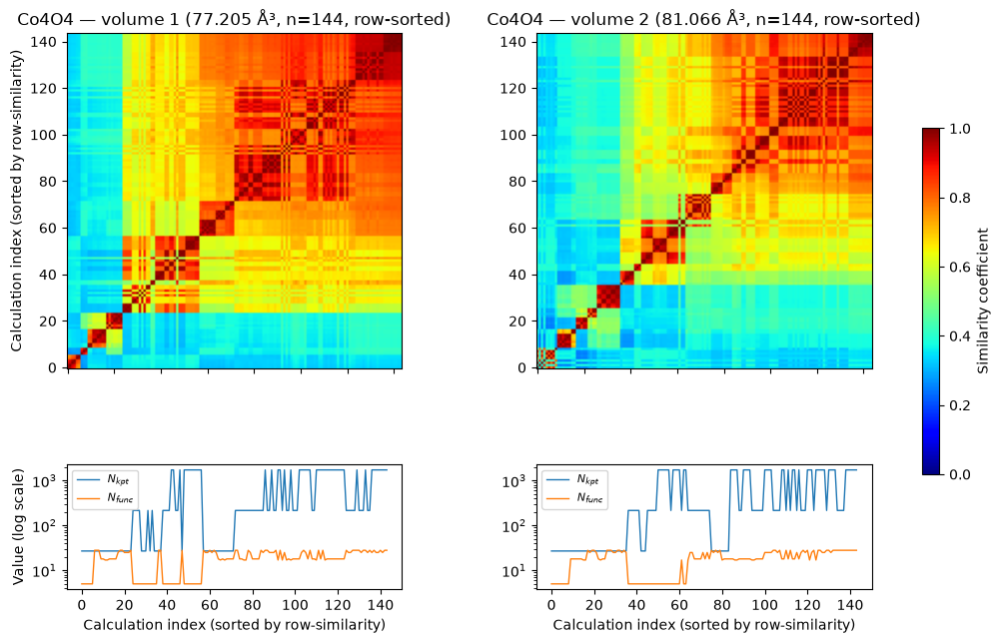

Saved: True

Material: Cr2   (formula: Cr2, 2 atoms/cell)
Cell: a=2.87 b=2.87 c=2.87 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:48,225 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cr2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [23.665, 24.848]


  0%|          | 0/333 [00:00<?, ?it/s]

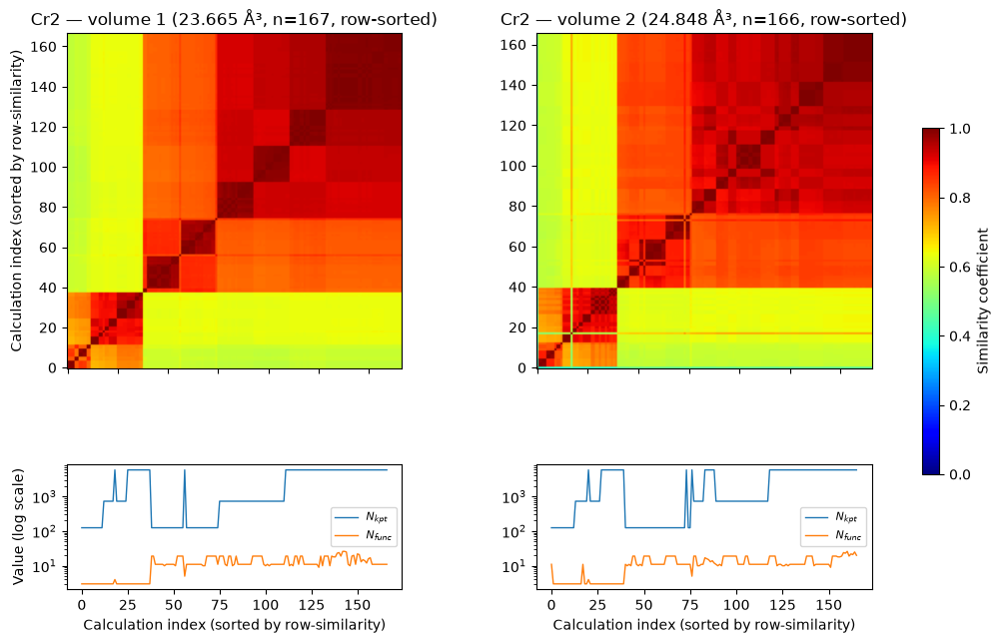

Saved: True

Material: Cr4N4   (formula: Cr4N4, 8 atoms/cell)
Cell: a=4.15 b=4.15 c=4.15 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:30:54,013 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Cr4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [71.422, 74.993]


  0%|          | 0/288 [00:00<?, ?it/s]

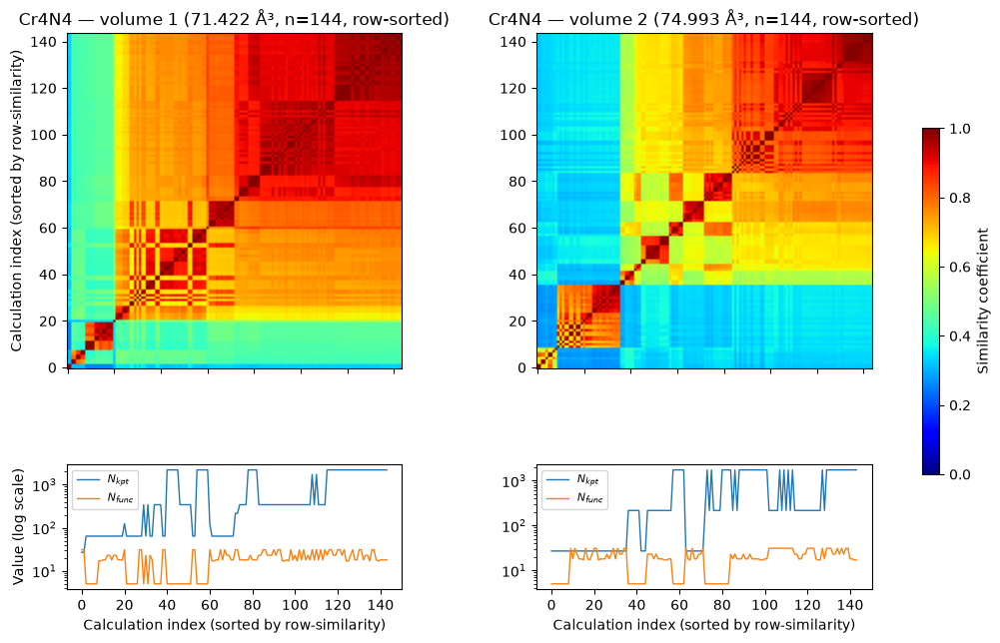

Saved: True

Material: CuFe2Ni   (formula: CuFe2Ni, 4 atoms/cell)
Cell: a=3.80 b=3.80 c=3.80 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:30:58,348 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/CuFe2Ni_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [38.652]


  0%|          | 0/144 [00:00<?, ?it/s]

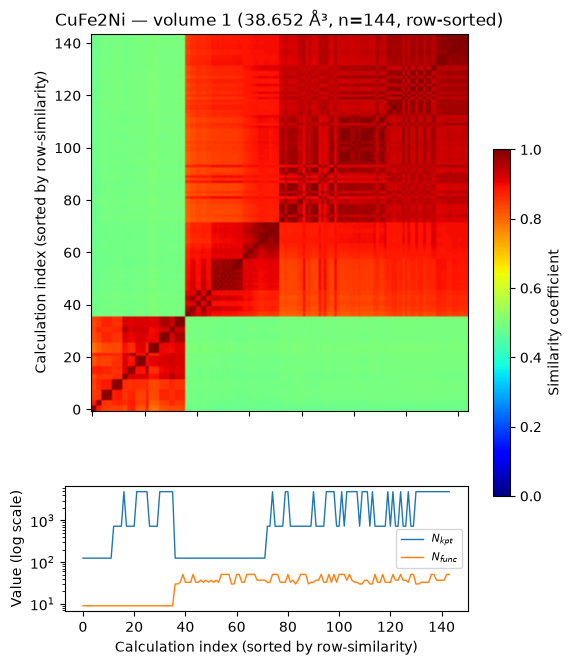

Saved: True

Material: Dy4N4   (formula: Dy4N4, 8 atoms/cell)
Cell: a=4.89 b=4.89 c=4.89 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [116.93, 122.777]


2026-09-06 15:31:01,662 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Dy4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

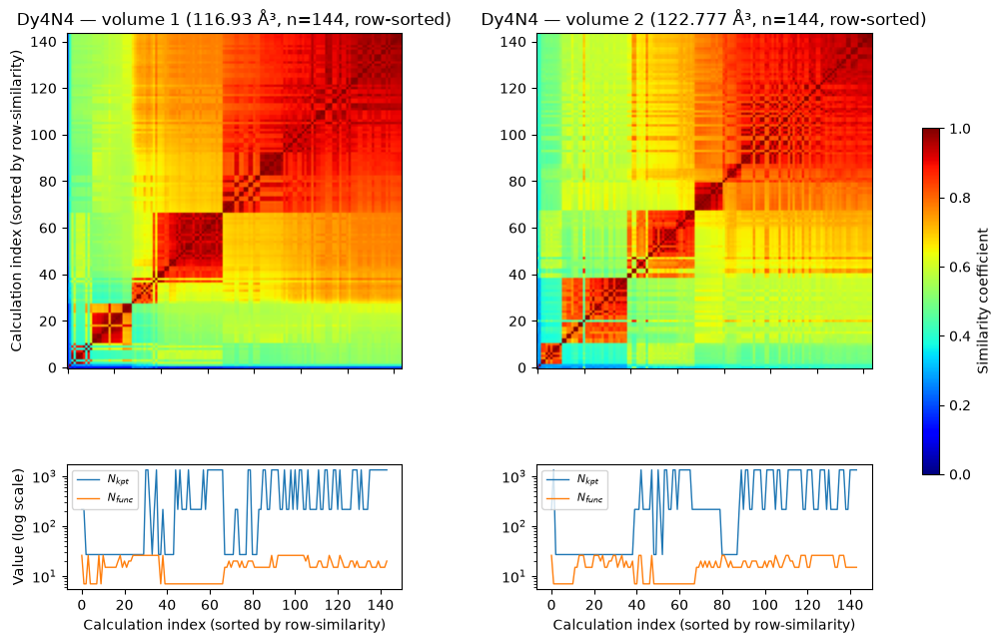

Saved: True

Material: Er4N4   (formula: Er4N4, 8 atoms/cell)
Cell: a=4.91 b=4.91 c=4.91 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:06,709 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Er4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [112.679, 118.312]


  0%|          | 0/288 [00:00<?, ?it/s]

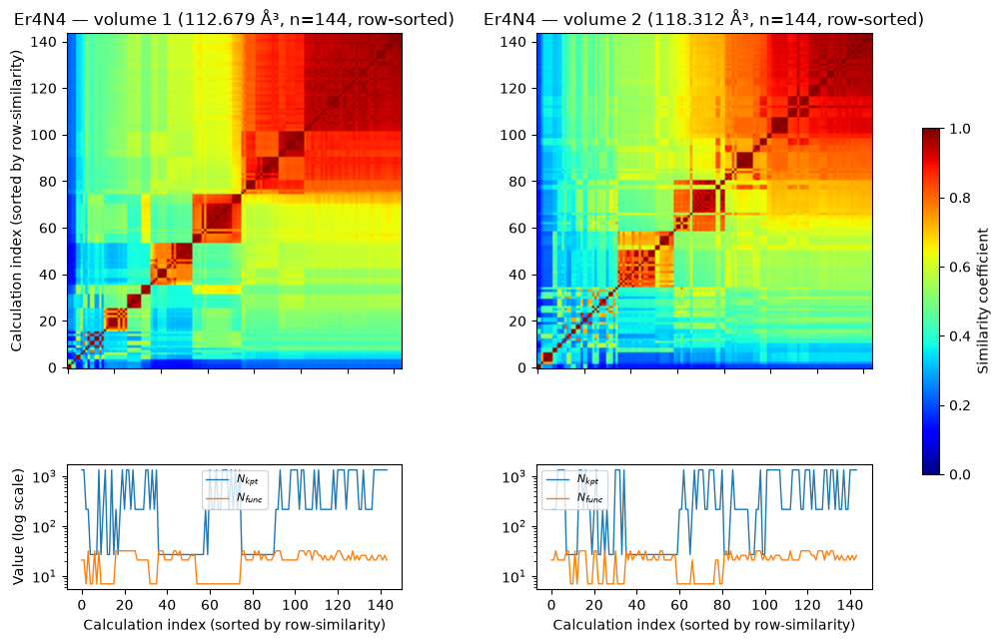

Saved: True

Material: Eu4S4   (formula: Eu4S4, 8 atoms/cell)
Cell: a=5.96 b=5.96 c=5.96 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:11,866 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Eu4S4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [212.242, 222.854]


  0%|          | 0/288 [00:00<?, ?it/s]

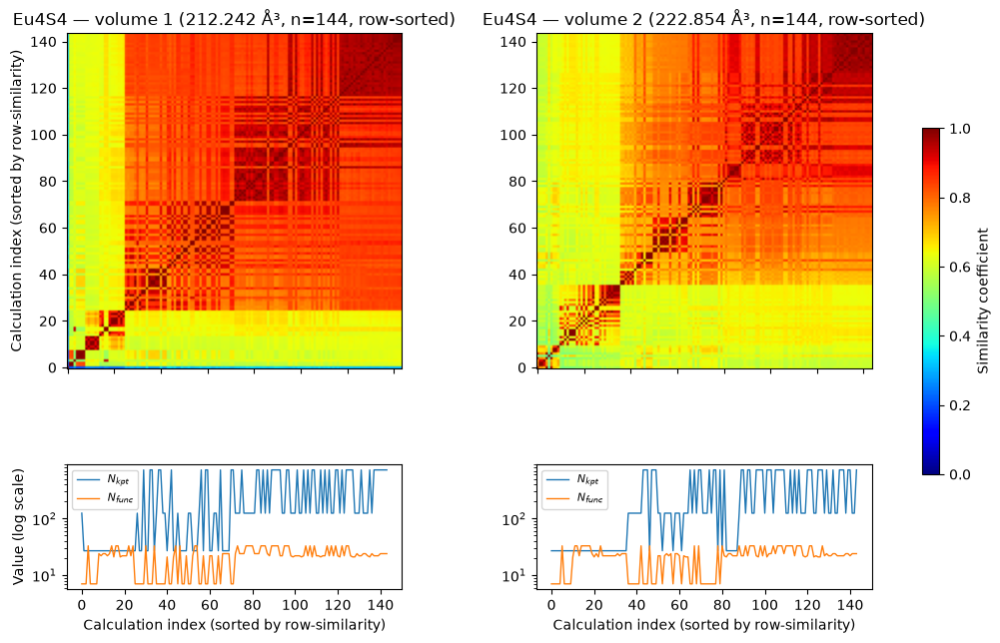

Saved: True

Material: F4Li4   (formula: F4Li4, 8 atoms/cell)
Cell: a=4.05 b=4.05 c=4.05 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:16,062 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/F4Li4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [66.43, 69.752]


  0%|          | 0/288 [00:00<?, ?it/s]

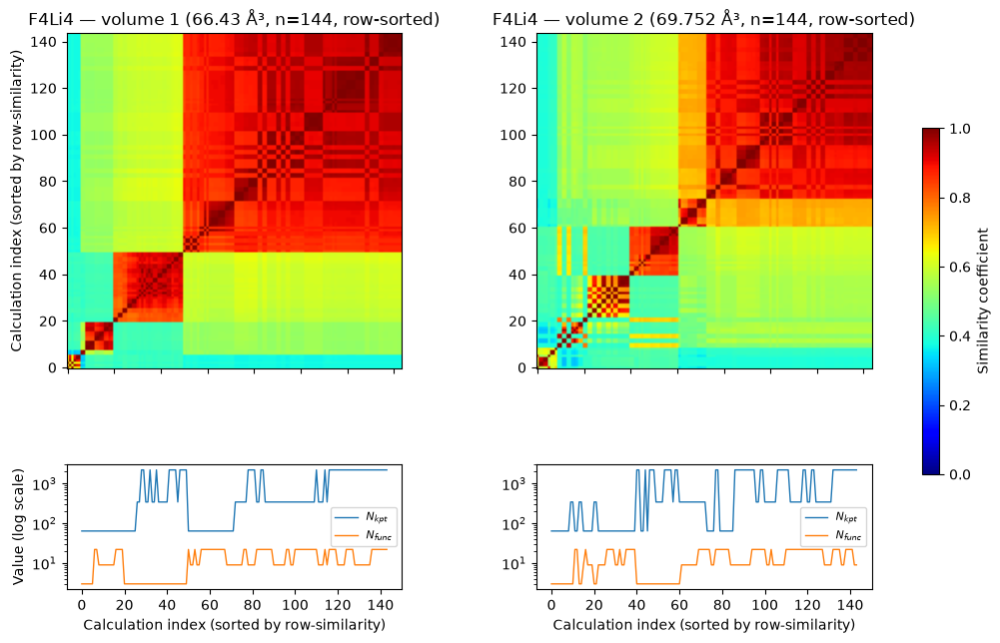

Saved: True

Material: F4Na4   (formula: F4Na4, 8 atoms/cell)
Cell: a=4.84 b=4.84 c=4.84 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:21,277 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/F4Na4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [107.85, 113.243]


  0%|          | 0/288 [00:00<?, ?it/s]

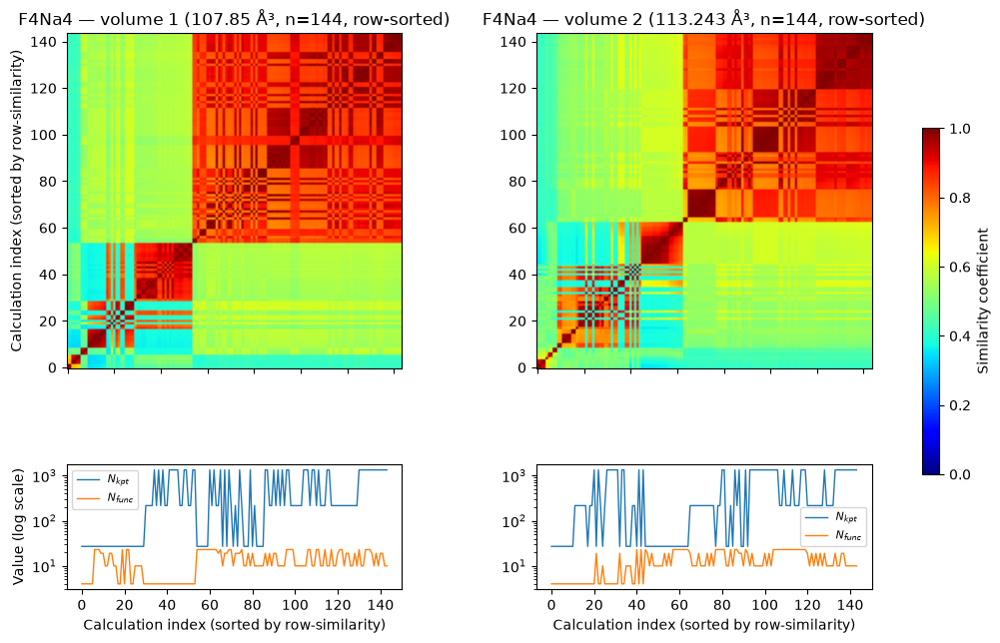

Saved: True

Material: F8   (formula: F8, 8 atoms/cell)
Cell: a=6.37 b=3.81 c=7.15 Å, α=90.0 β=96.8 γ=90.0°


2026-09-06 15:31:25,752 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/F8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [156.187, 163.997, 172.196]


  0%|          | 0/321 [00:00<?, ?it/s]

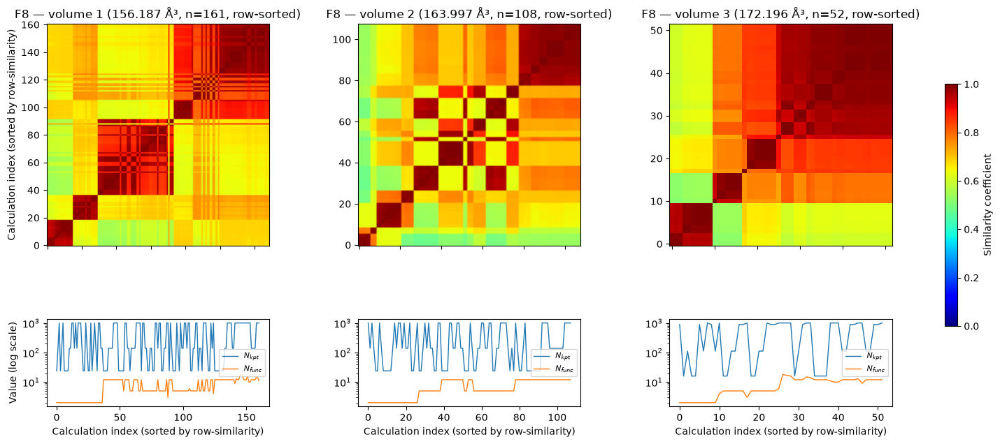

Saved: True

Material: F8Hg4   (formula: F8Hg4, 12 atoms/cell)
Cell: a=5.63 b=5.63 c=5.63 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:31,036 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/F8Hg4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [170.031, 178.533]


  0%|          | 0/288 [00:00<?, ?it/s]

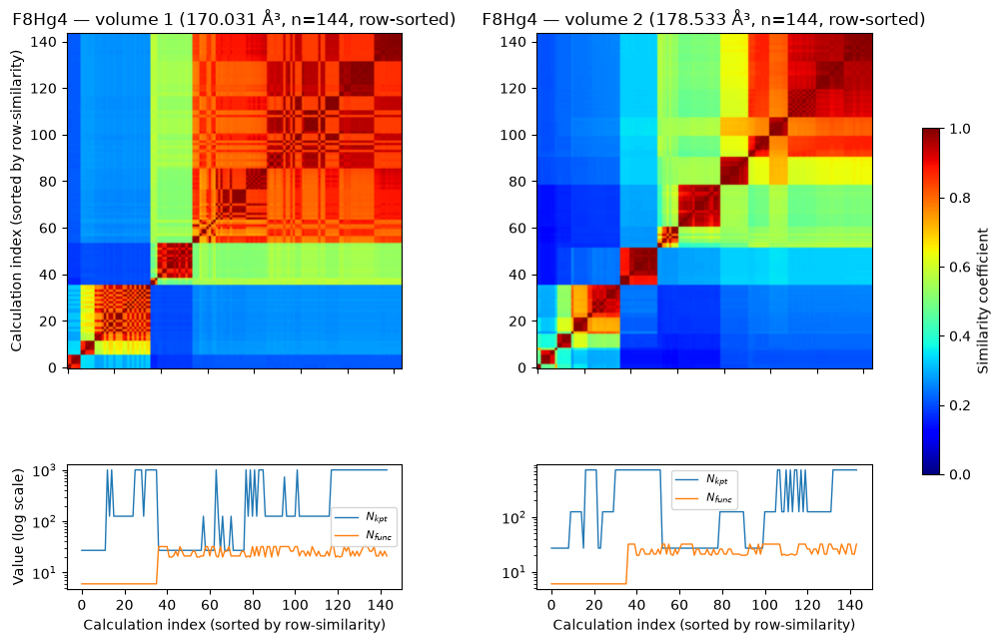

Saved: True

Material: F8Ra4   (formula: F8Ra4, 12 atoms/cell)
Cell: a=6.47 b=6.47 c=6.47 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:35,511 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/F8Ra4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [258.231, 271.143]


  0%|          | 0/288 [00:00<?, ?it/s]

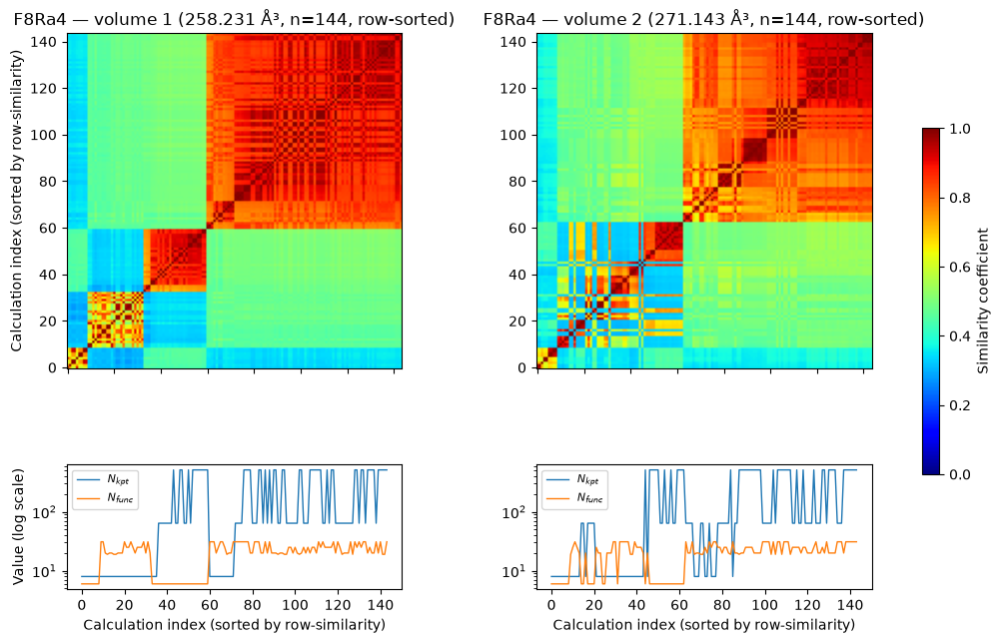

Saved: True

Material: Fe2   (formula: Fe2, 2 atoms/cell)
Cell: a=2.83 b=2.83 c=2.83 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:40,594 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Fe2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [22.75, 23.887]


  0%|          | 0/329 [00:00<?, ?it/s]

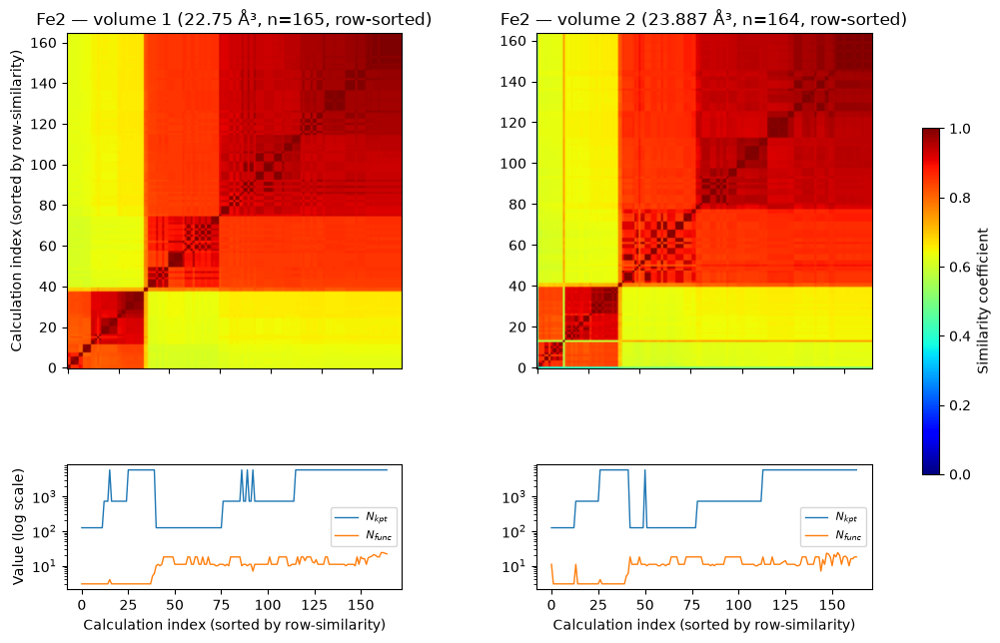

Saved: True

Material: Fe4O4   (formula: Fe4O4, 8 atoms/cell)
Cell: a=4.32 b=4.32 c=4.32 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:46,792 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Fe4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [80.79, 84.829]


  0%|          | 0/288 [00:00<?, ?it/s]

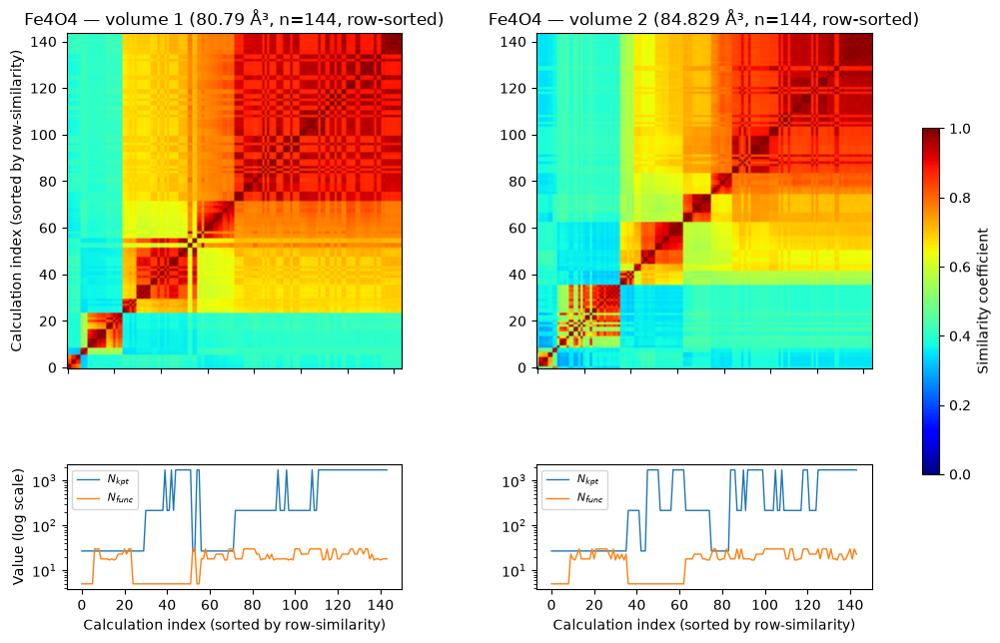

Saved: True

Material: Ga4P4   (formula: Ga4P4, 8 atoms/cell)
Cell: a=5.45 b=5.45 c=5.45 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:52,007 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ga4P4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [161.95, 170.047]


  0%|          | 0/288 [00:00<?, ?it/s]

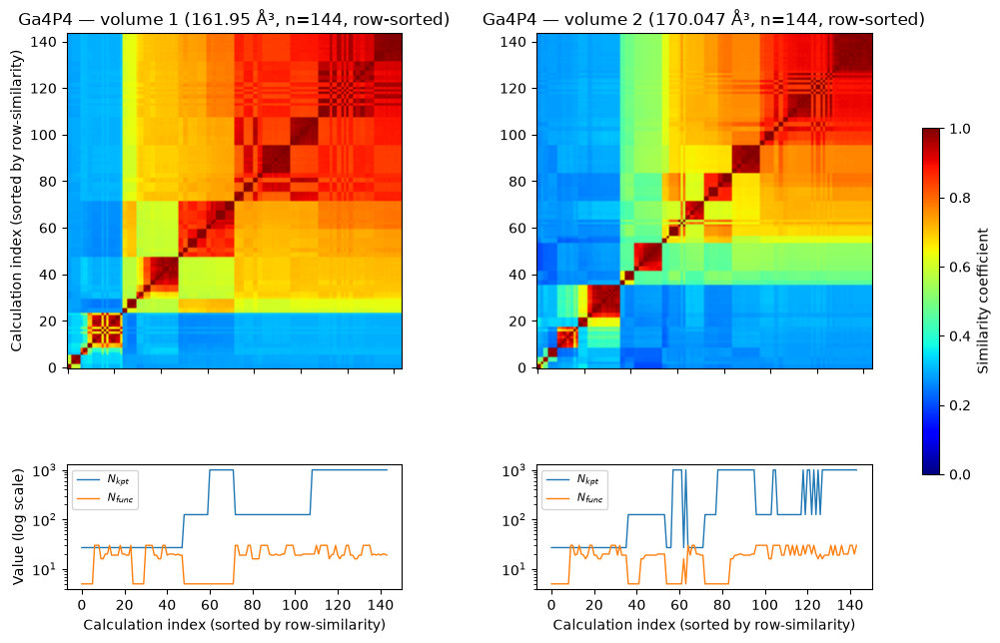

Saved: True

Material: Ga8   (formula: Ga8, 8 atoms/cell)
Cell: a=4.57 b=7.75 c=4.60 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:31:57,200 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ga8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [162.871, 171.015]


  0%|          | 0/319 [00:00<?, ?it/s]

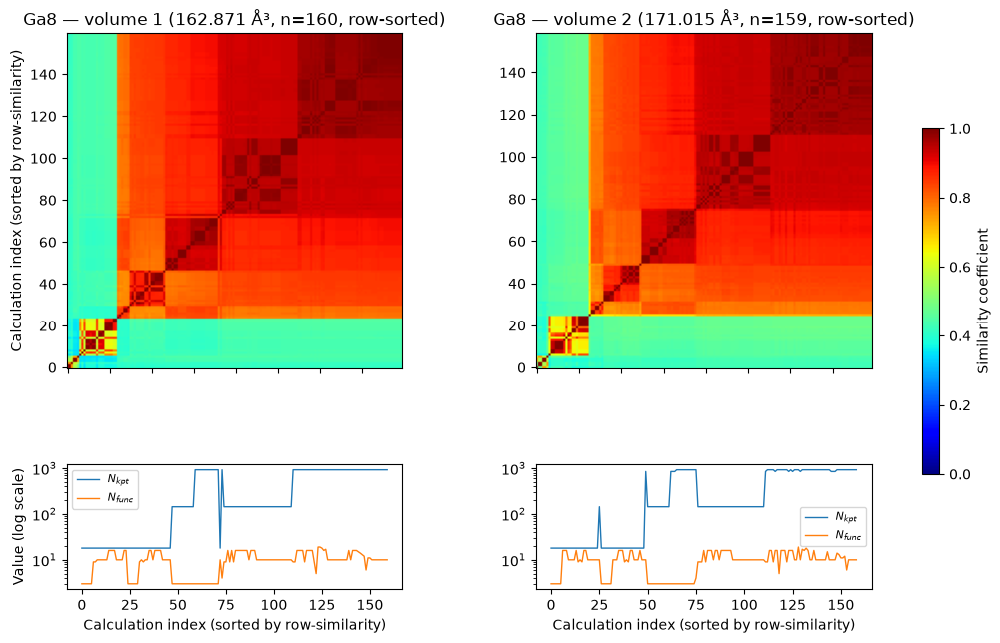

Saved: True

Material: Gd4N4   (formula: Gd4N4, 8 atoms/cell)
Cell: a=5.06 b=5.06 c=5.06 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:02,309 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Gd4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [123.357, 129.525]


  0%|          | 0/288 [00:00<?, ?it/s]

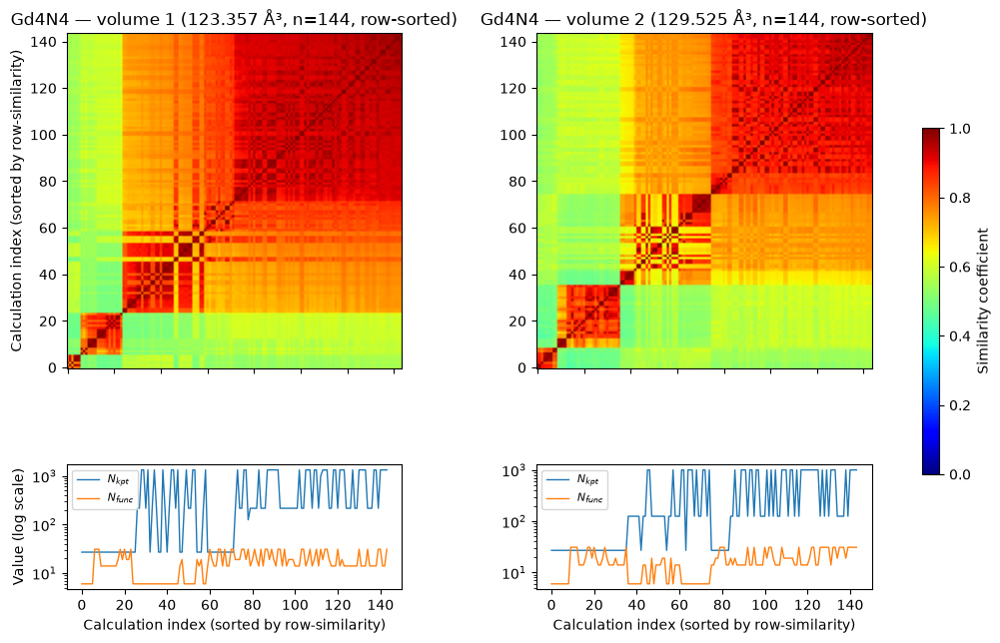

Saved: True

Material: Ge2   (formula: Ge2, 2 atoms/cell)
Cell: a=4.07 b=4.07 c=4.07 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:32:07,650 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ge2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [47.82, 50.211, 52.721]


  0%|          | 0/321 [00:00<?, ?it/s]

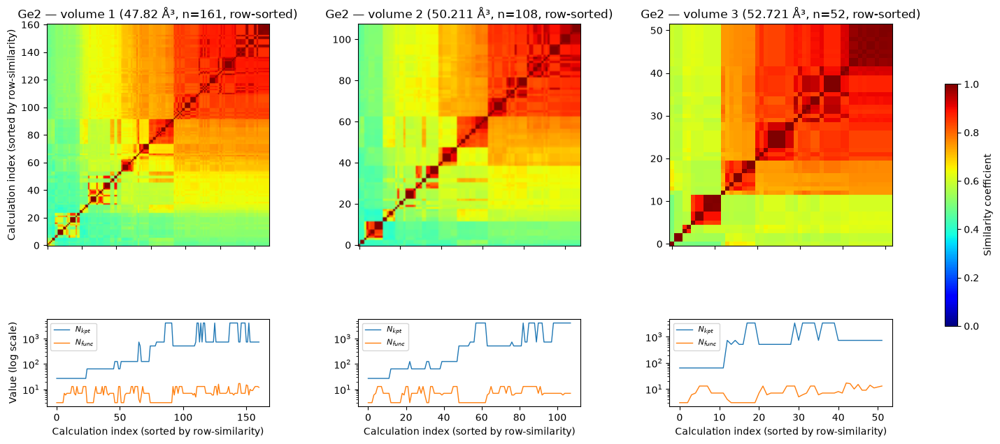

Saved: True

Material: Ge3Te3   (formula: Ge3Te3, 6 atoms/cell)
Cell: a=4.16 b=4.16 c=10.70 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:32:12,877 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ge3Te3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [160.695, 168.73]


  0%|          | 0/288 [00:00<?, ?it/s]

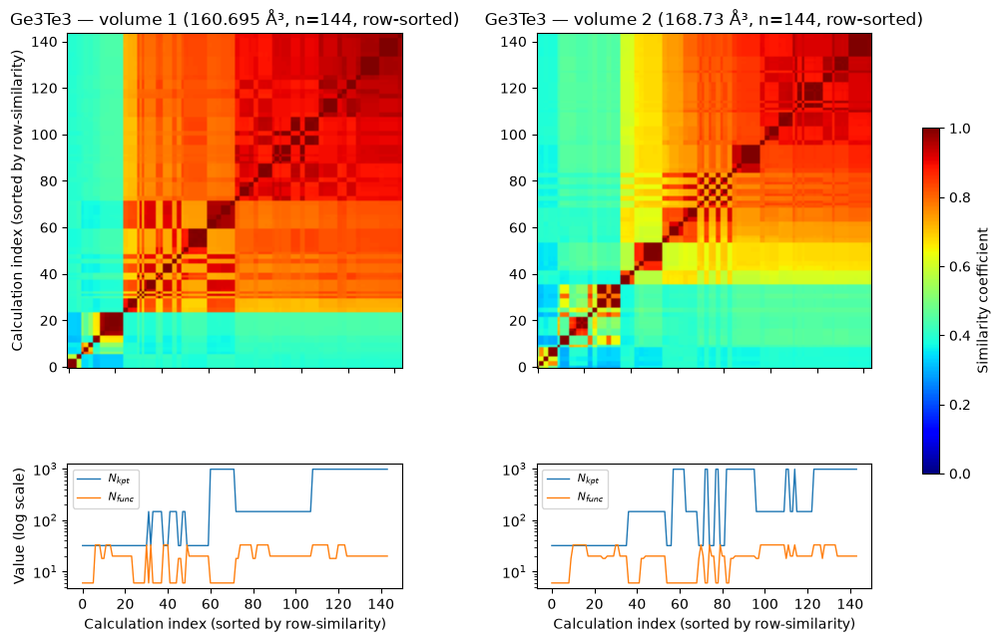

Saved: True

Material: Ge4Mg4N8   (formula: Ge4Mg4N8, 16 atoms/cell)
Cell: a=5.49 b=6.61 c=5.17 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:17,254 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ge4Mg4N8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [187.633]


  0%|          | 0/144 [00:00<?, ?it/s]

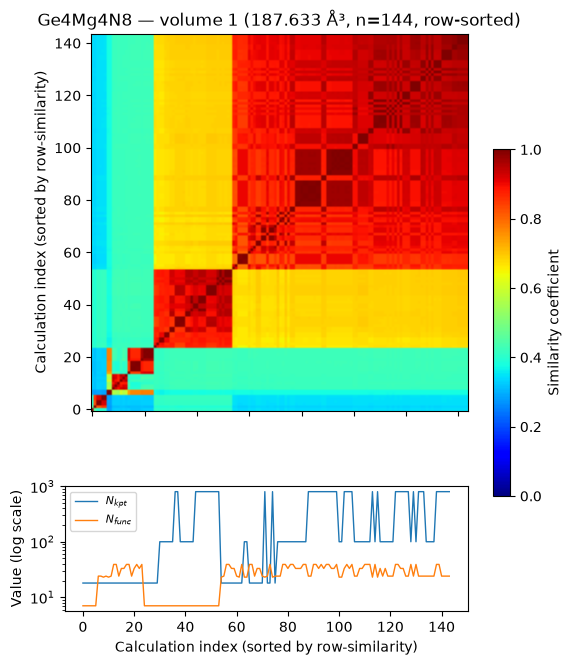

Saved: True

Material: H4   (formula: H4, 4 atoms/cell)
Cell: a=4.07 b=4.07 c=5.09 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:32:20,298 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/H4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [69.588, 73.067]


  0%|          | 0/307 [00:00<?, ?it/s]

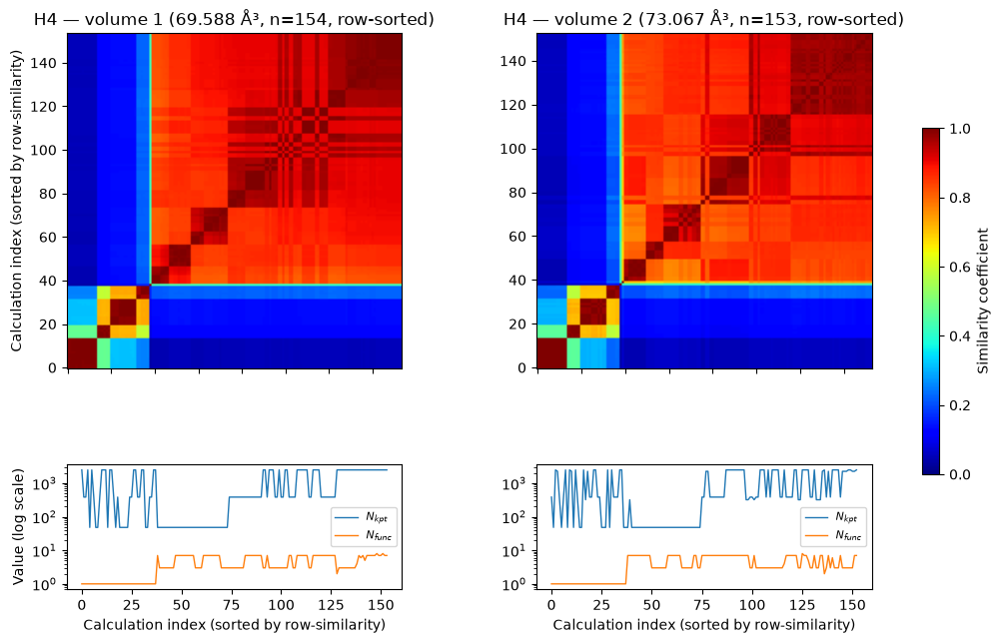

Saved: True

Material: H4Li4   (formula: H4Li4, 8 atoms/cell)
Cell: a=4.08 b=4.08 c=4.08 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:24,749 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/H4Li4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [68.072, 71.476]


  0%|          | 0/288 [00:00<?, ?it/s]

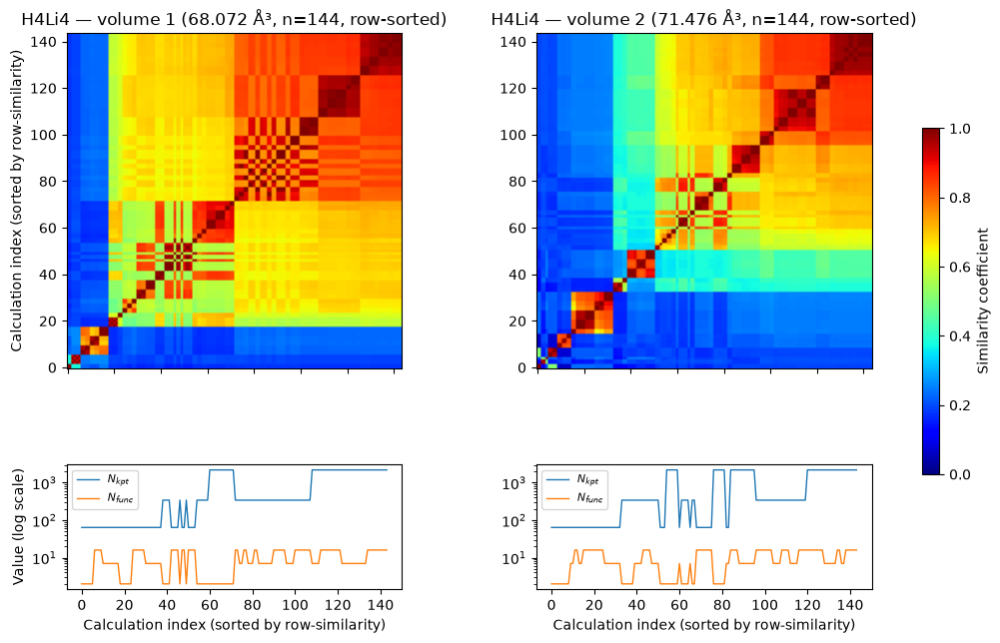

Saved: True

Material: He2   (formula: He2, 2 atoms/cell)
Cell: a=2.97 b=2.97 c=4.86 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:32:29,538 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/He2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [35.449, 37.222]


  0%|          | 0/307 [00:00<?, ?it/s]

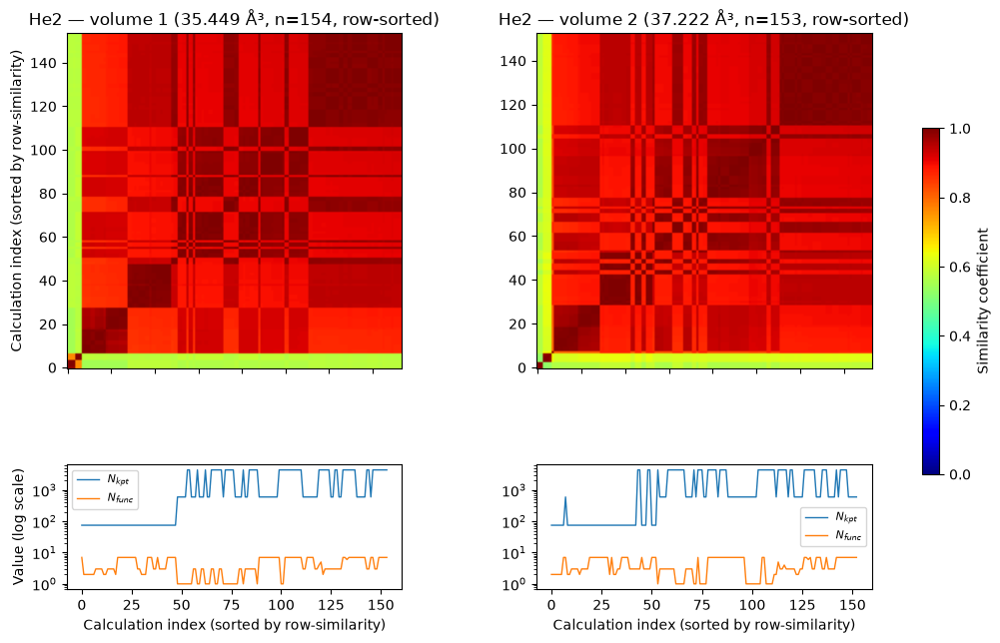

Saved: True

Material: Hf2   (formula: Hf2, 2 atoms/cell)
Cell: a=3.26 b=3.26 c=5.15 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:32:34,582 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Hf2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [44.993, 47.243]


  0%|          | 0/319 [00:00<?, ?it/s]

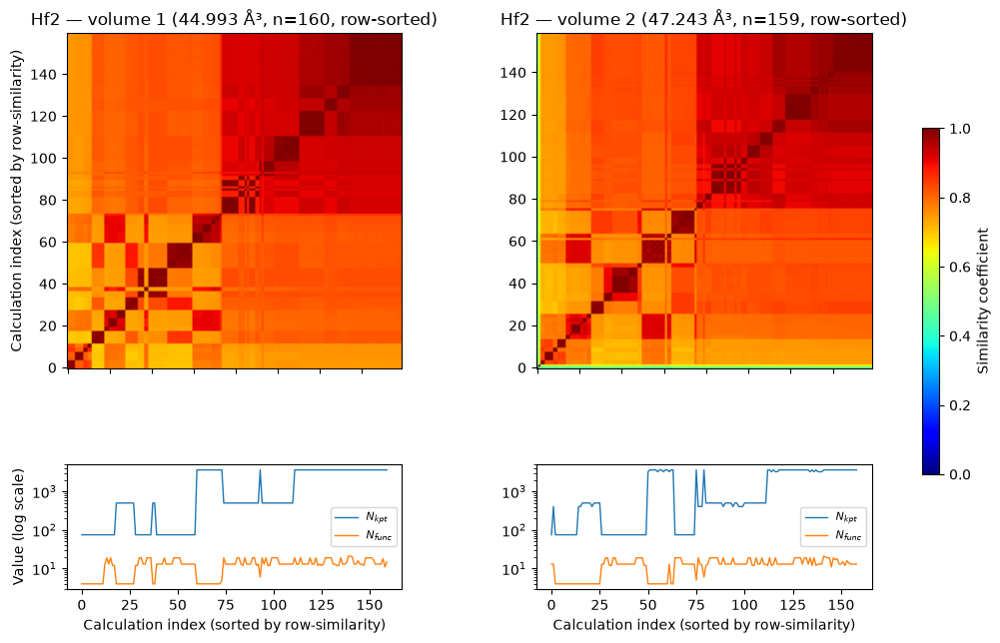

Saved: True

Material: Ho4N4   (formula: Ho4N4, 8 atoms/cell)
Cell: a=4.95 b=4.95 c=4.95 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:39,899 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ho4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [115.736, 121.523]


  0%|          | 0/288 [00:00<?, ?it/s]

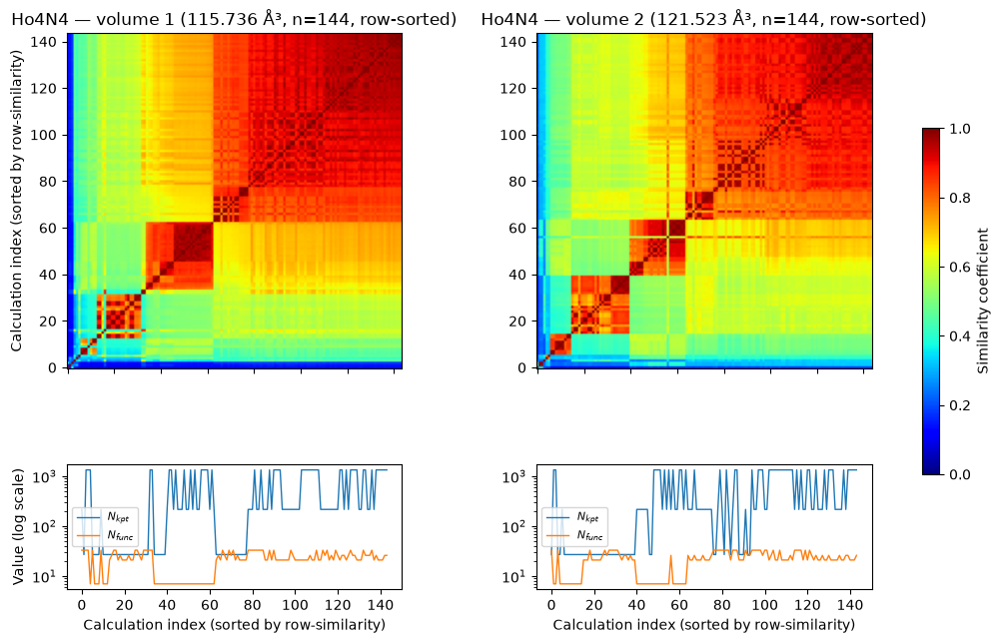

Saved: True

Material: I4Li4   (formula: I4Li4, 8 atoms/cell)
Cell: a=6.16 b=6.16 c=6.16 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:44,696 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/I4Li4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [222.545, 233.672]


  0%|          | 0/288 [00:00<?, ?it/s]

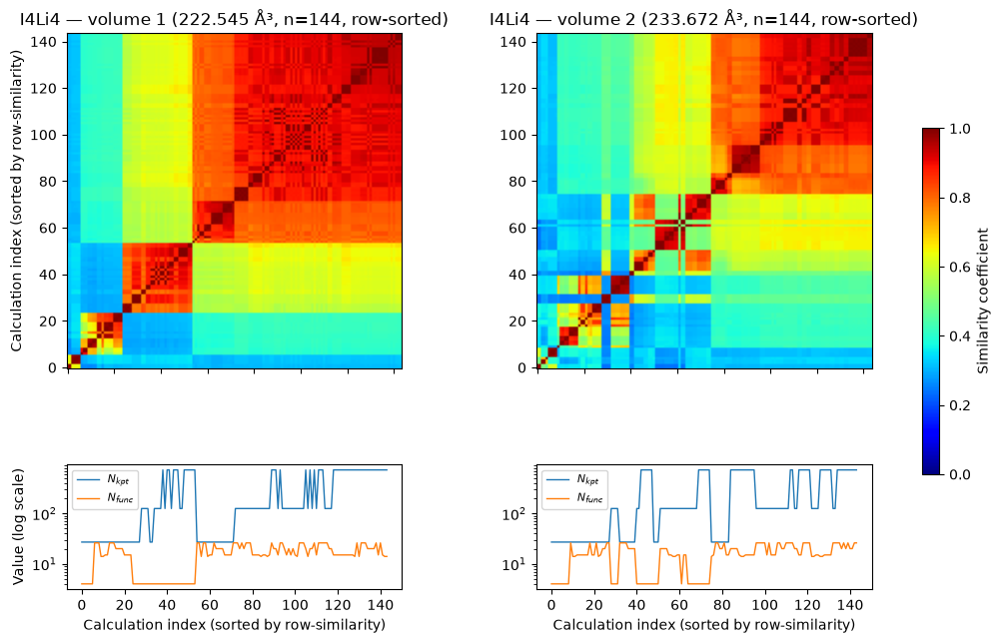

Saved: True

Material: I8   (formula: I8, 8 atoms/cell)
Cell: a=8.72 b=4.63 c=10.35 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [397.796, 417.685]


2026-09-06 15:32:49,409 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/I8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/319 [00:00<?, ?it/s]

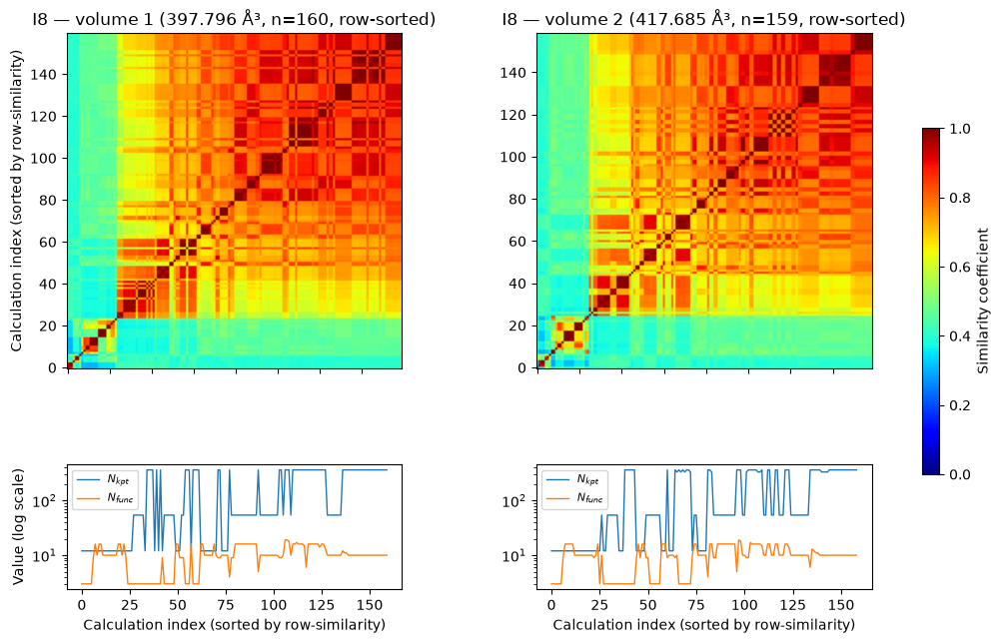

Saved: True

Material: In2   (formula: In2, 2 atoms/cell)
Cell: a=3.30 b=3.30 c=5.06 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:32:55,759 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/In2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [55.078, 57.832]


  0%|          | 0/319 [00:00<?, ?it/s]

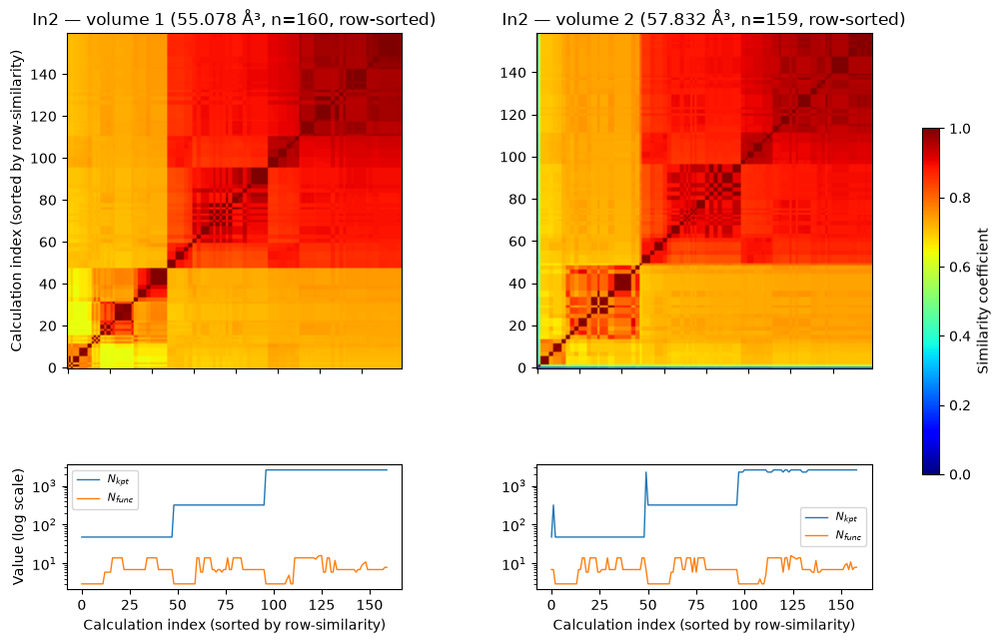

Saved: True

Material: In4P4   (formula: In4P4, 8 atoms/cell)
Cell: a=5.87 b=5.87 c=5.87 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:01,800 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/In4P4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [202.128, 212.234]


  0%|          | 0/576 [00:00<?, ?it/s]

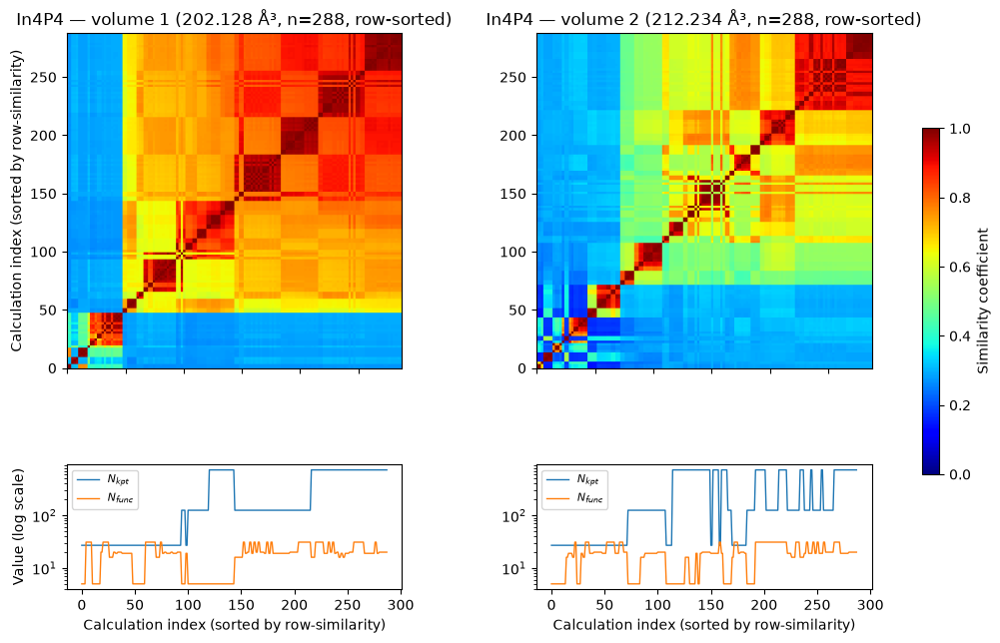

Saved: True

Material: In4Sb4   (formula: In4Sb4, 8 atoms/cell)
Cell: a=6.48 b=6.48 c=6.48 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:09,789 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/In4Sb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [272.022, 285.623]


  0%|          | 0/288 [00:00<?, ?it/s]

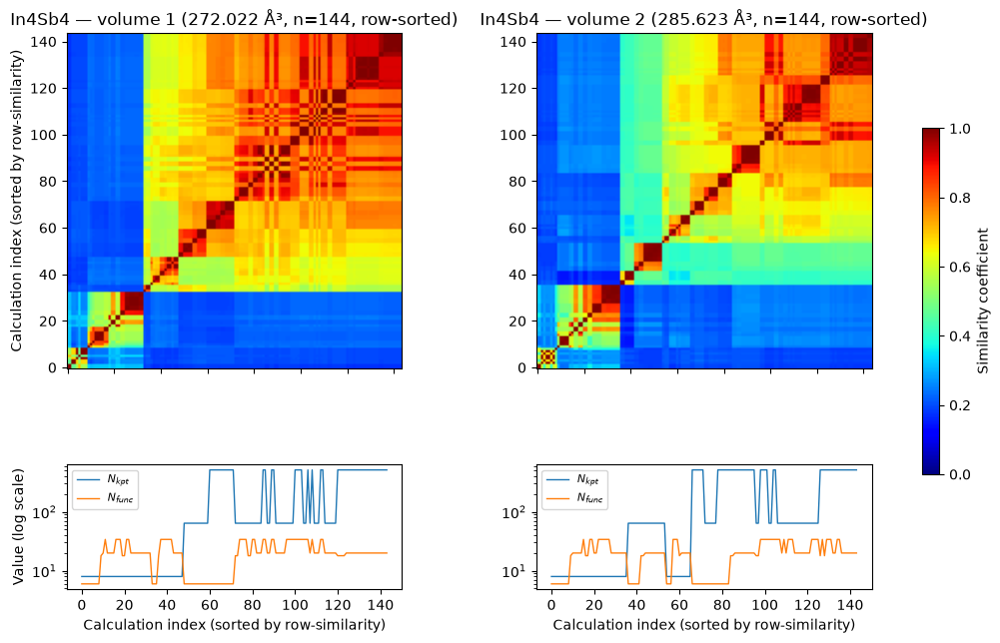

Saved: True

Material: Ir2O4   (formula: Ir2O4, 6 atoms/cell)
Cell: a=4.58 b=4.58 c=3.21 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:14,547 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ir2O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [64.107, 67.312]


  0%|          | 0/288 [00:00<?, ?it/s]

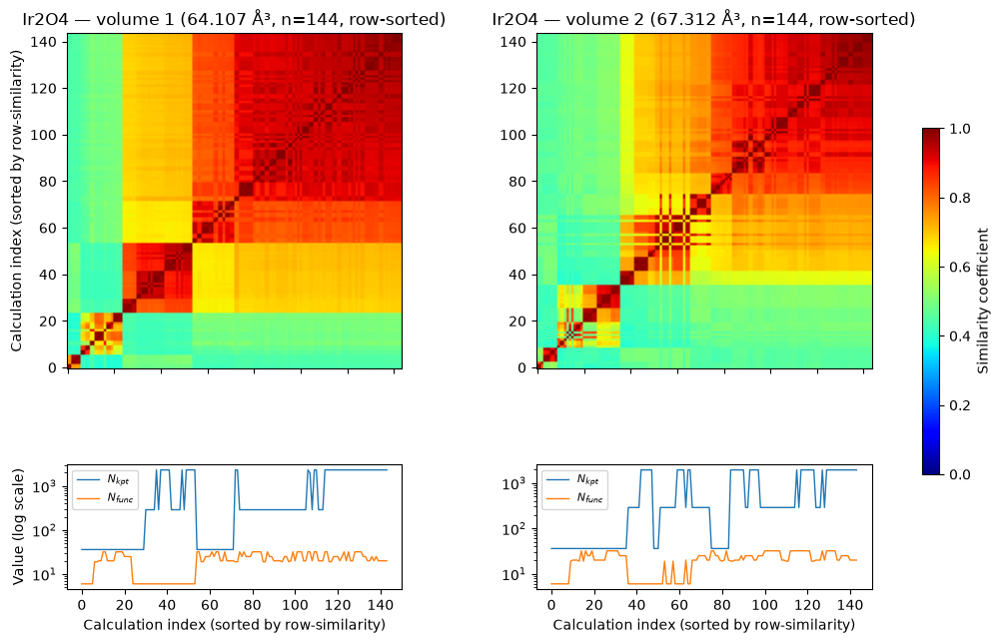

Saved: True

Material: Ir4   (formula: Ir4, 4 atoms/cell)
Cell: a=3.88 b=3.88 c=3.88 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:19,904 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ir4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [58.264, 61.178]


  0%|          | 0/319 [00:00<?, ?it/s]

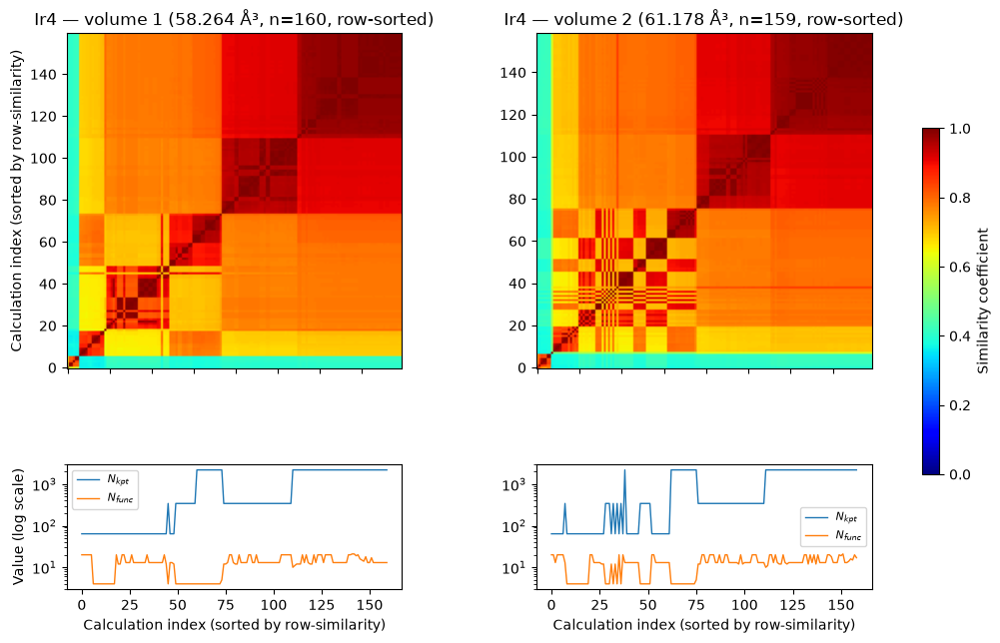

Saved: True

Material: IrNa2Zn   (formula: IrNa2Zn, 4 atoms/cell)
Cell: a=4.71 b=4.71 c=4.71 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:33:25,116 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/IrNa2Zn_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [73.763]


  0%|          | 0/144 [00:00<?, ?it/s]

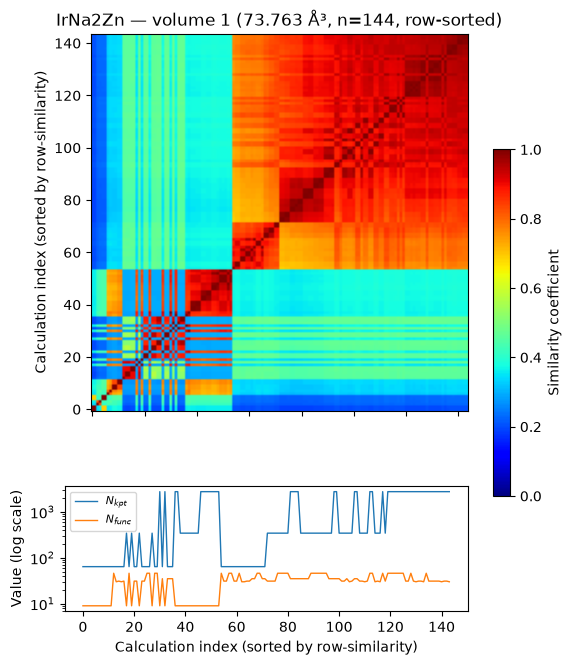

Saved: True

Material: K2   (formula: K2, 2 atoms/cell)
Cell: a=5.37 b=5.37 c=5.37 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:28,069 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/K2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [147.691, 155.076]


  0%|          | 0/323 [00:00<?, ?it/s]

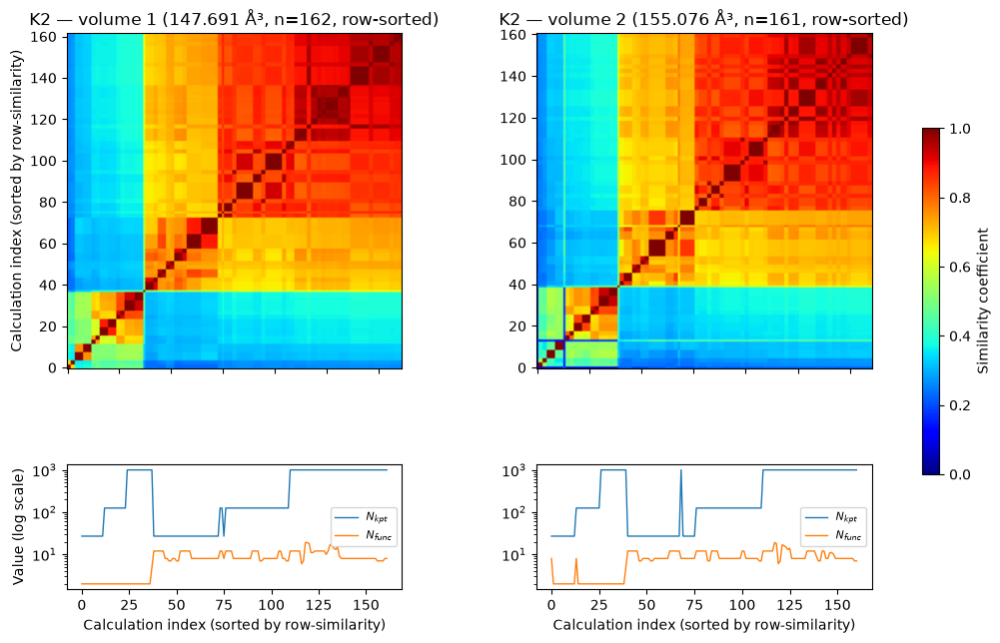

Saved: True

Material: Li3   (formula: Li3, 3 atoms/cell)
Cell: a=7.64 b=7.64 c=7.64 Å, α=23.2 β=23.2 γ=23.2°


2026-09-06 15:33:34,062 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Li3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [60.854, 63.897, 67.092]


  0%|          | 0/315 [00:00<?, ?it/s]

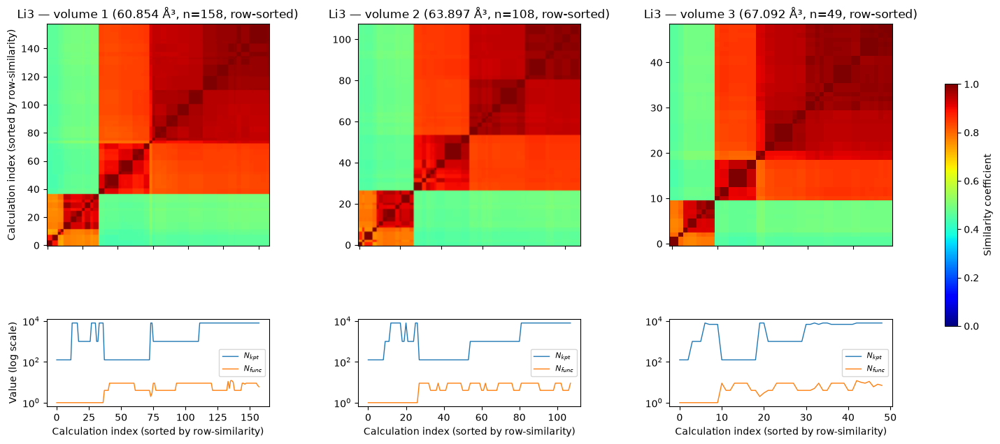

Saved: True

Material: Lu2   (formula: Lu2, 2 atoms/cell)
Cell: a=3.52 b=3.52 c=5.48 Å, α=90.0 β=90.0 γ=60.0°
Volume groups: [58.935, 61.882]


2026-09-06 15:33:39,374 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Lu2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/319 [00:00<?, ?it/s]

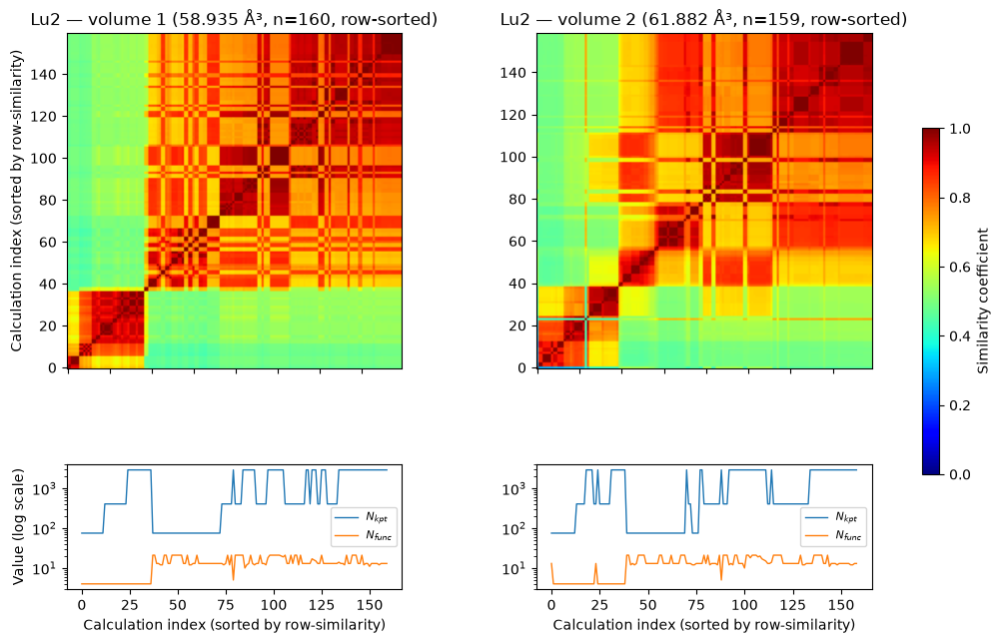

Saved: True

Material: Lu4N4   (formula: Lu4N4, 8 atoms/cell)
Cell: a=4.76 b=4.76 c=4.76 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:44,923 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Lu4N4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [107.843, 113.236]


  0%|          | 0/288 [00:00<?, ?it/s]

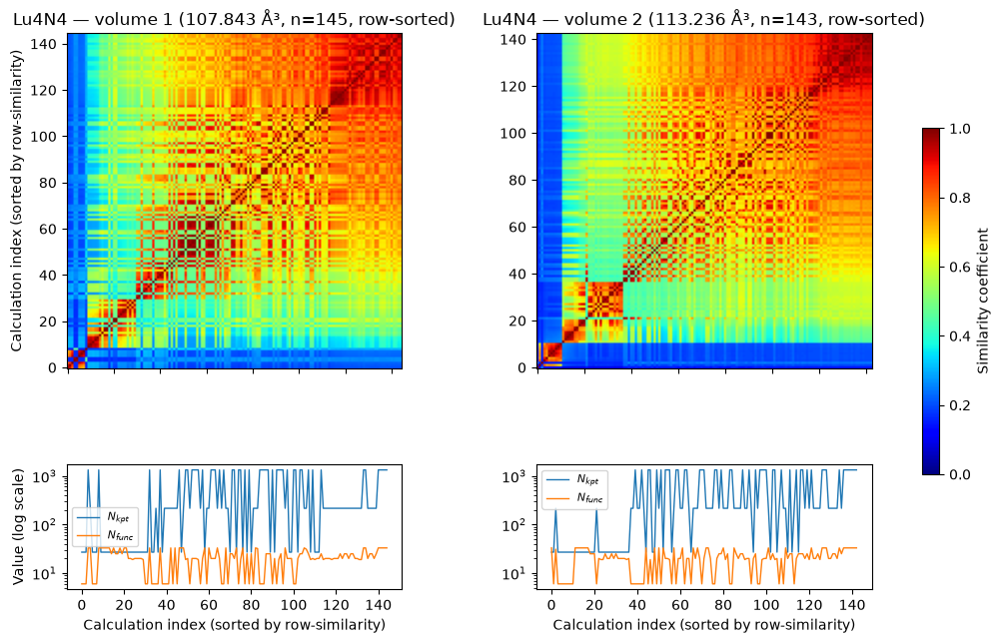

Saved: True

Material: Mg4O4   (formula: Mg4O4, 8 atoms/cell)
Cell: a=4.18 b=4.18 c=4.18 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:50,547 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Mg4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [73.192, 76.852]


  0%|          | 0/288 [00:00<?, ?it/s]

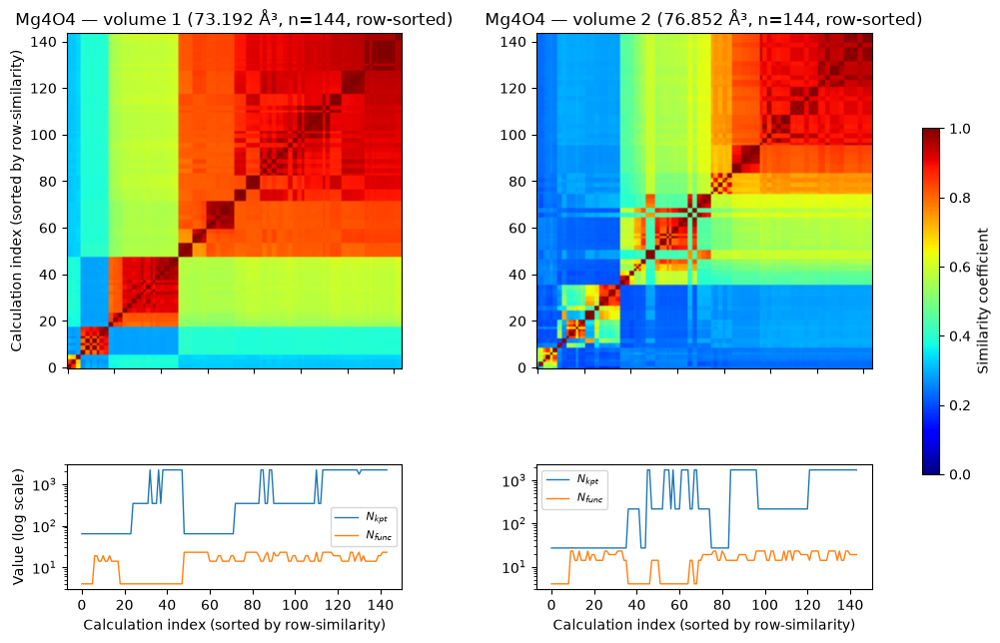

Saved: True

Material: Mn4   (formula: Mn4, 4 atoms/cell)
Cell: a=3.65 b=3.65 c=3.65 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:33:56,042 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Mn4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [46.482, 48.806, 51.246]


  0%|          | 0/325 [00:00<?, ?it/s]

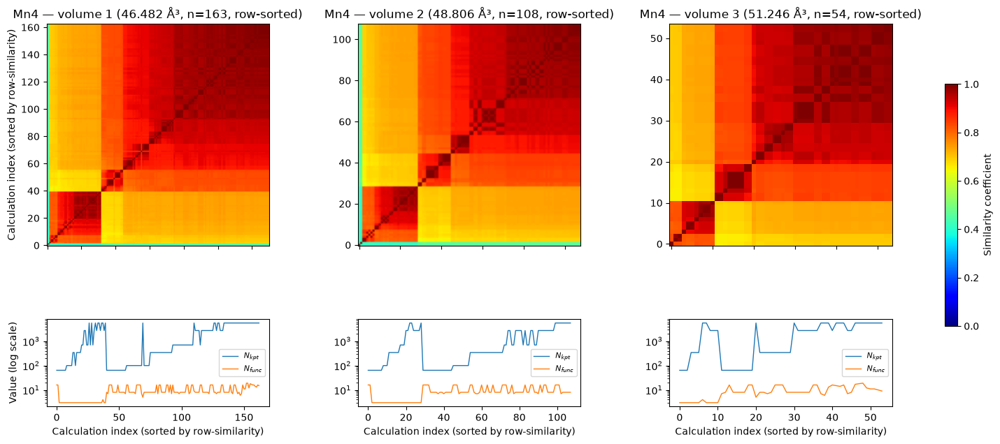

Saved: True

Material: Mn4S4   (formula: Mn4S4, 8 atoms/cell)
Cell: a=5.31 b=5.31 c=5.31 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:02,036 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Mn4S4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [142.564, 149.692]


  0%|          | 0/288 [00:00<?, ?it/s]

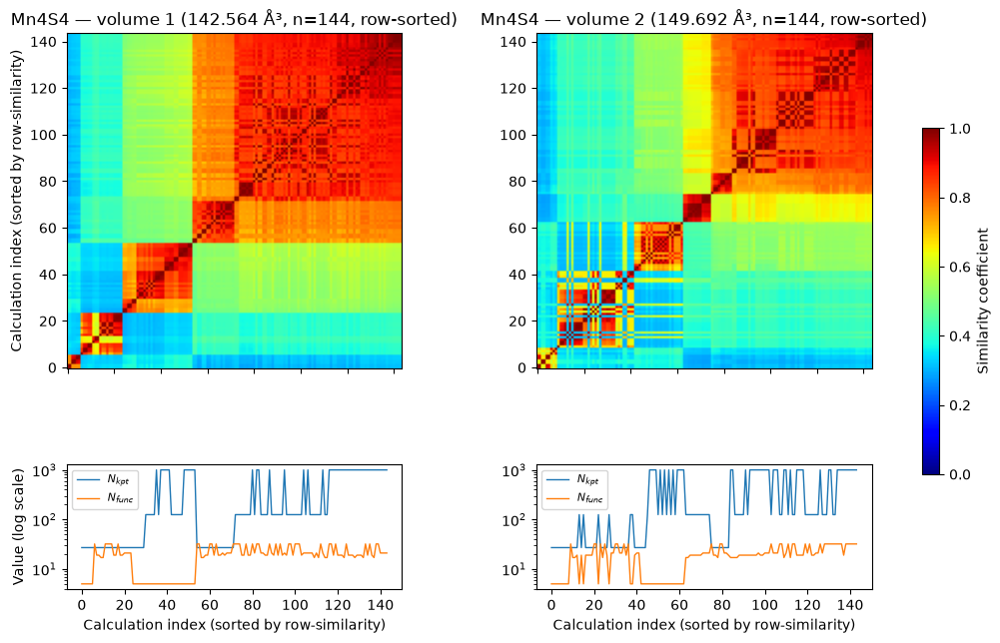

Saved: True

Material: Mo2   (formula: Mo2, 2 atoms/cell)
Cell: a=3.17 b=3.17 c=3.17 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:07,004 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Mo2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [31.834, 33.426]


  0%|          | 0/321 [00:00<?, ?it/s]

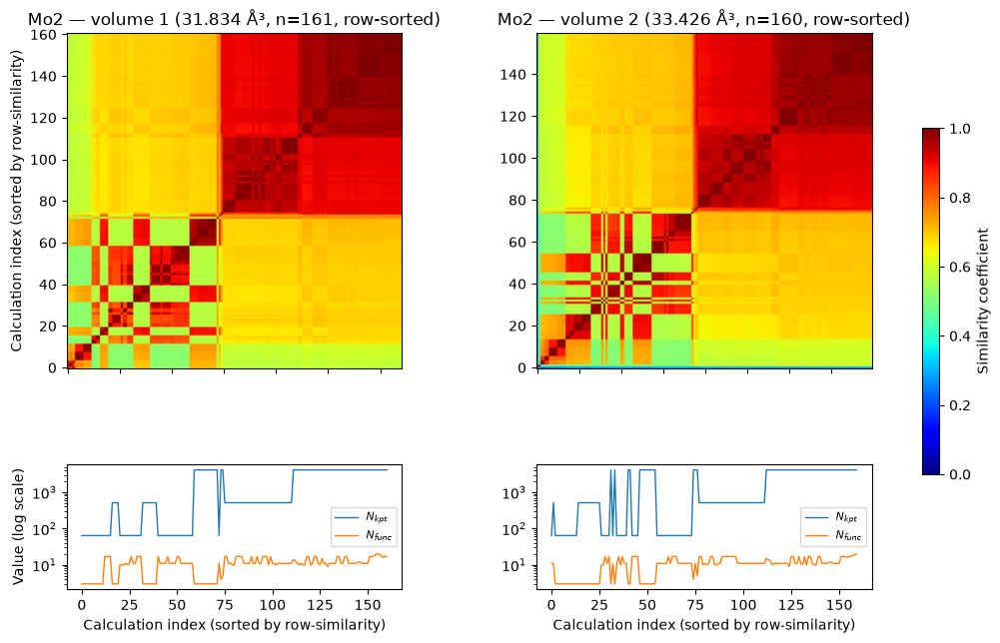

Saved: True

Material: N4Nd4   (formula: N4Nd4, 8 atoms/cell)
Cell: a=5.10 b=5.10 c=5.10 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:12,413 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Nd4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [132.573, 139.202]


  0%|          | 0/288 [00:00<?, ?it/s]

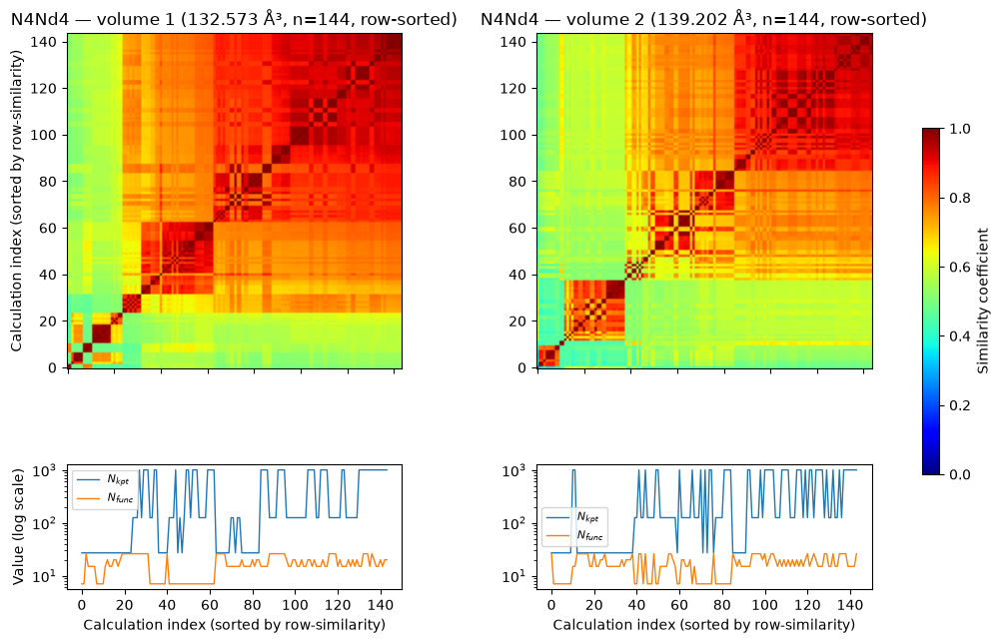

Saved: True

Material: N4Pr4   (formula: N4Pr4, 8 atoms/cell)
Cell: a=5.16 b=5.16 c=5.16 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:17,446 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Pr4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [137.628, 144.509]


  0%|          | 0/288 [00:00<?, ?it/s]

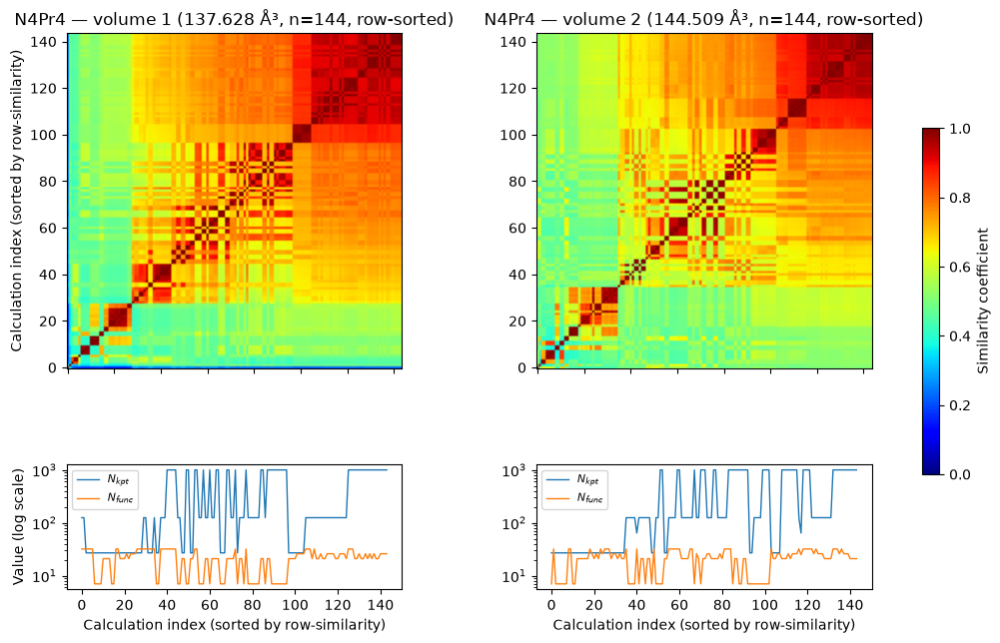

Saved: True

Material: N4Sm4   (formula: N4Sm4, 8 atoms/cell)
Cell: a=5.03 b=5.03 c=5.03 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:22,169 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Sm4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [127.339, 133.706]


  0%|          | 0/288 [00:00<?, ?it/s]

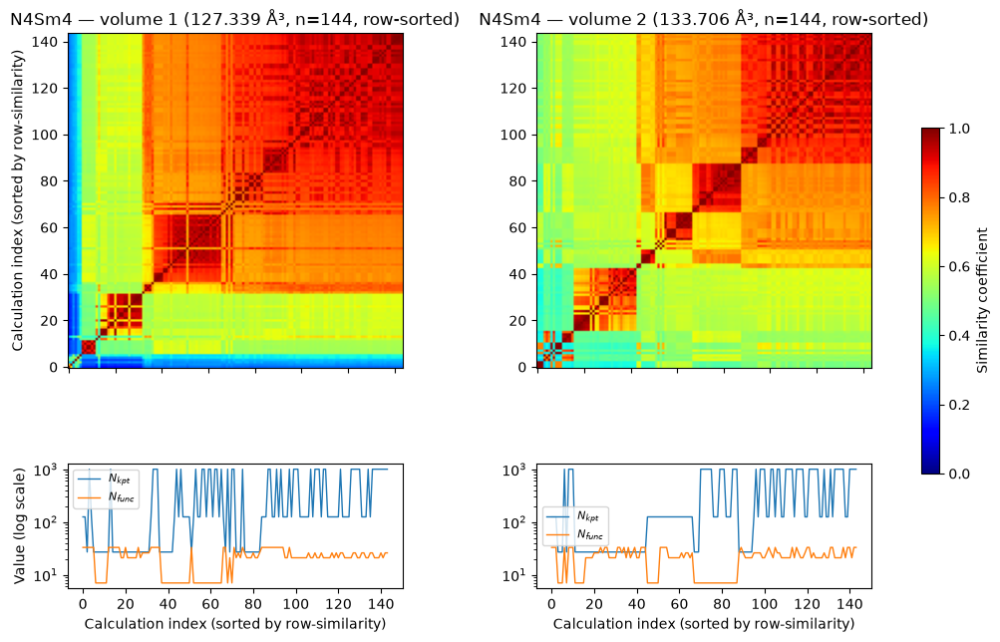

Saved: True

Material: N4Tb4   (formula: N4Tb4, 8 atoms/cell)
Cell: a=4.94 b=4.94 c=4.94 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:27,075 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Tb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [120.407, 126.428]


  0%|          | 0/288 [00:00<?, ?it/s]

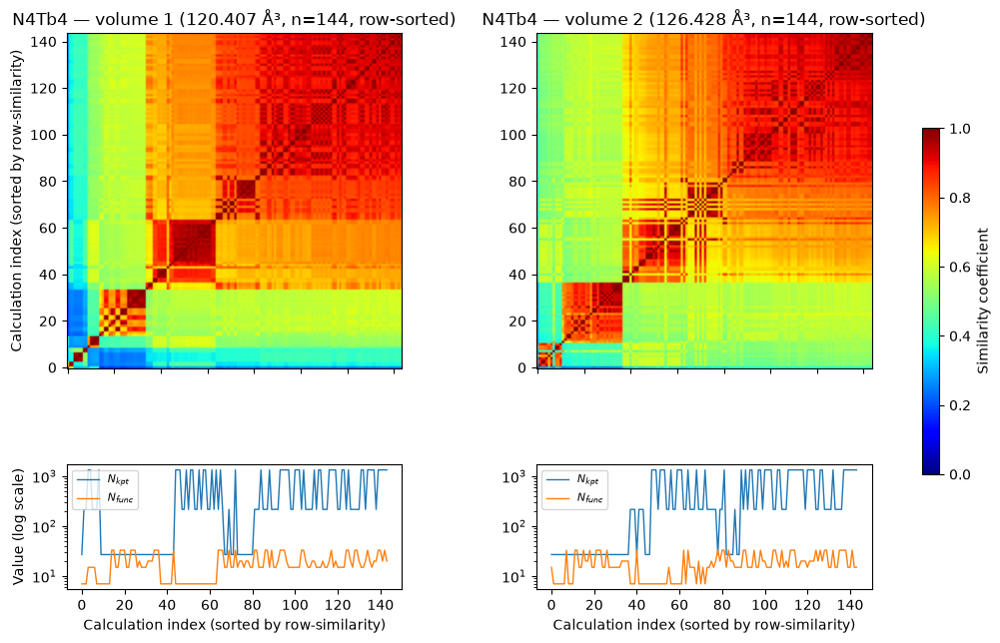

Saved: True

Material: N4Ti4   (formula: N4Ti4, 8 atoms/cell)
Cell: a=4.31 b=4.31 c=4.31 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:31,645 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Ti4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [76.333, 80.15]


  0%|          | 0/288 [00:00<?, ?it/s]

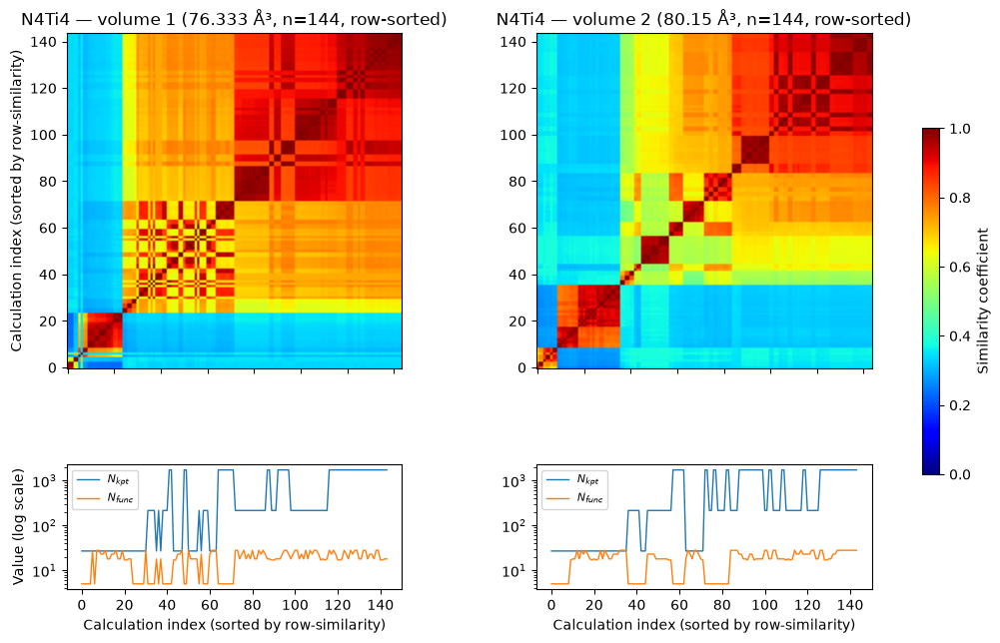

Saved: True

Material: N4Tm4   (formula: N4Tm4, 8 atoms/cell)
Cell: a=4.81 b=4.81 c=4.81 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:37,226 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Tm4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [111.285, 116.849]


  0%|          | 0/288 [00:00<?, ?it/s]

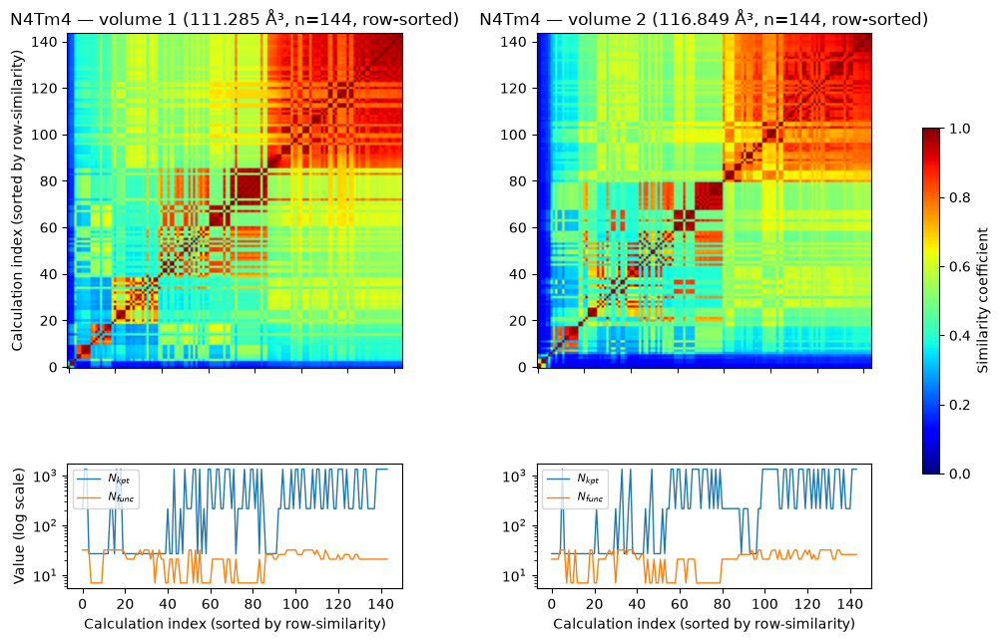

Saved: True

Material: N4V4   (formula: N4V4, 8 atoms/cell)
Cell: a=4.20 b=4.20 c=4.20 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:42,091 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4V4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [70.445, 73.967]


  0%|          | 0/288 [00:00<?, ?it/s]

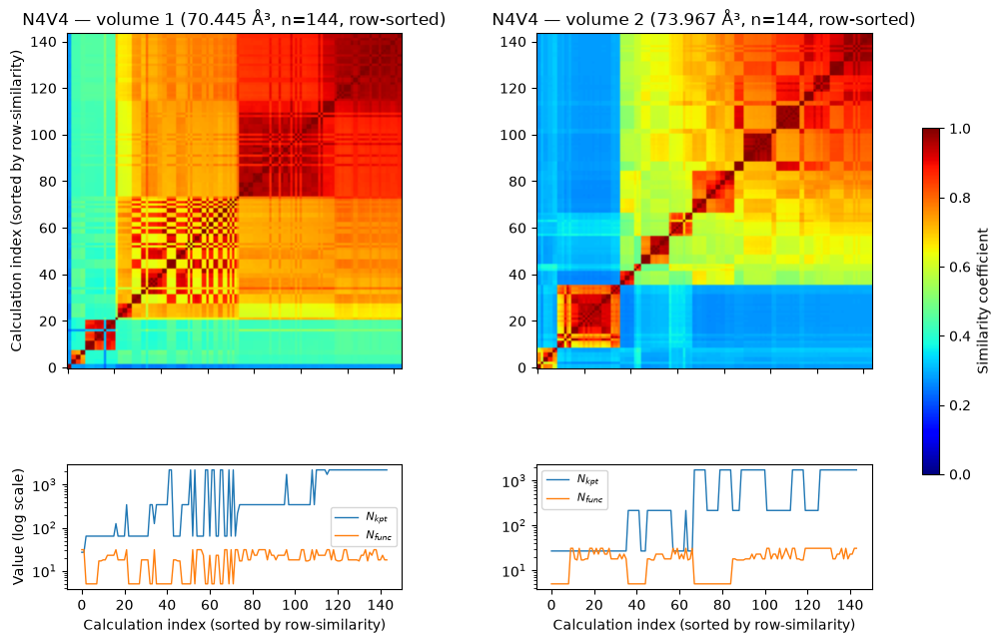

Saved: True

Material: N4Y4   (formula: N4Y4, 8 atoms/cell)
Cell: a=4.96 b=4.96 c=4.96 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [116.214, 122.025]


2026-09-06 15:34:46,890 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Y4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

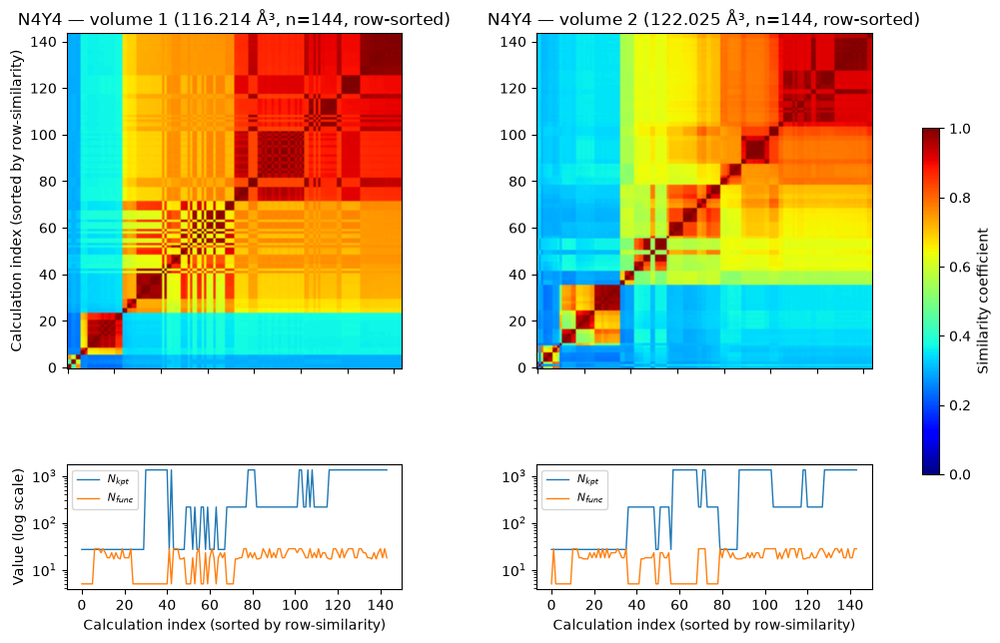

Saved: True

Material: N4Yb4   (formula: N4Yb4, 8 atoms/cell)
Cell: a=4.79 b=4.79 c=4.79 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:52,387 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N4Yb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [109.696, 115.181]


  0%|          | 0/288 [00:00<?, ?it/s]

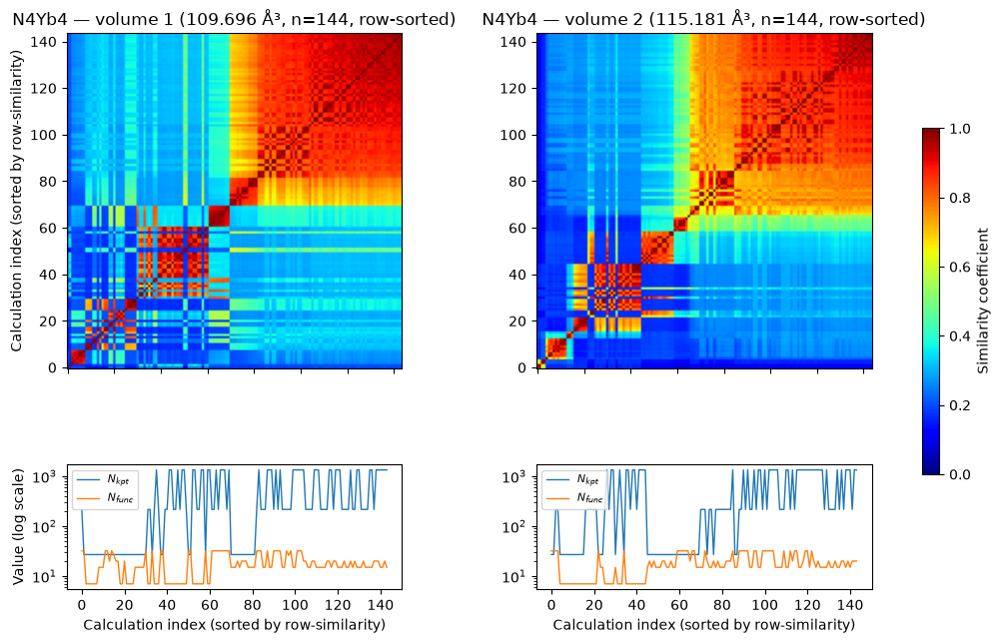

Saved: True

Material: N8   (formula: N8, 8 atoms/cell)
Cell: a=6.29 b=6.29 c=6.29 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:34:58,037 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/N8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [237.198, 249.058]


  0%|          | 0/329 [00:00<?, ?it/s]

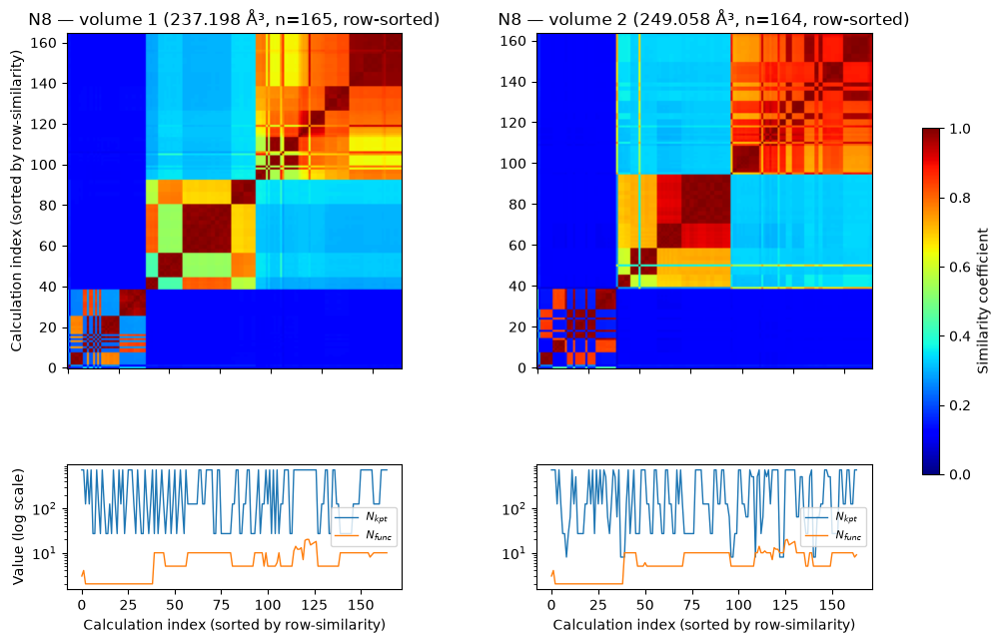

Saved: True

Material: Na3   (formula: Na3, 3 atoms/cell)
Cell: a=9.42 b=9.42 c=9.42 Å, α=22.9 β=22.9 γ=22.9°
Volume groups: [111.21, 116.77, 122.609]


2026-09-06 15:35:03,081 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Na3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/323 [00:00<?, ?it/s]

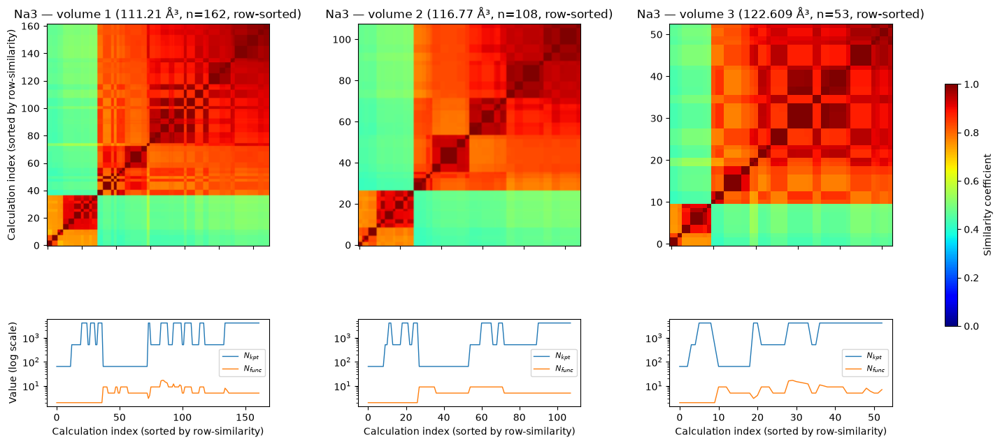

Saved: True

Material: Nb2   (formula: Nb2, 2 atoms/cell)
Cell: a=3.32 b=3.32 c=3.32 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:08,767 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Nb2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [36.673, 38.507]


  0%|          | 0/319 [00:00<?, ?it/s]

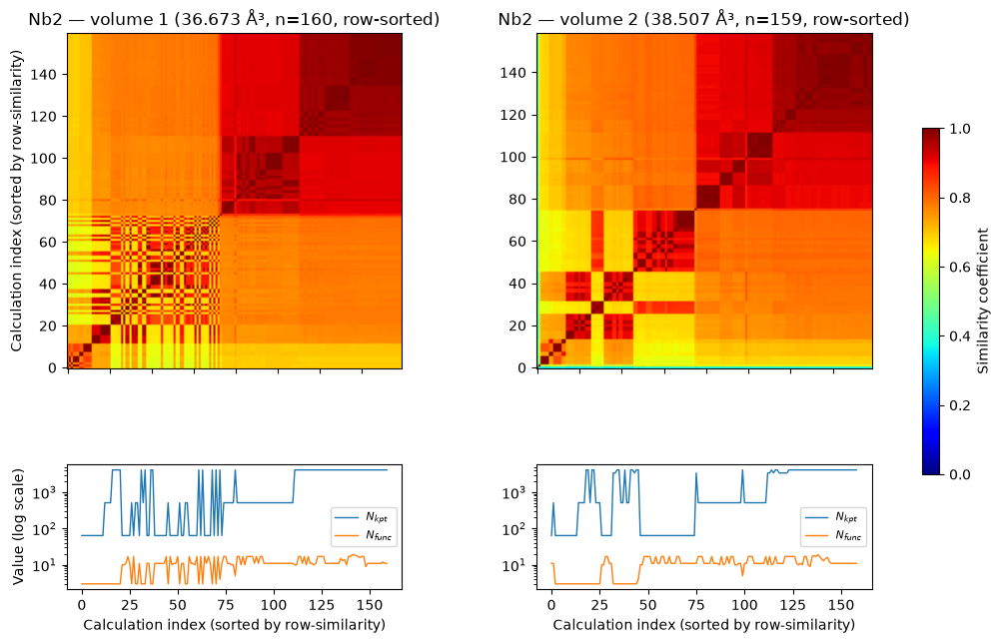

Saved: True

Material: Ni4   (formula: Ni4, 4 atoms/cell)
Cell: a=3.58 b=3.58 c=3.58 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:15,220 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ni4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [43.768, 45.957]


  0%|          | 0/325 [00:00<?, ?it/s]

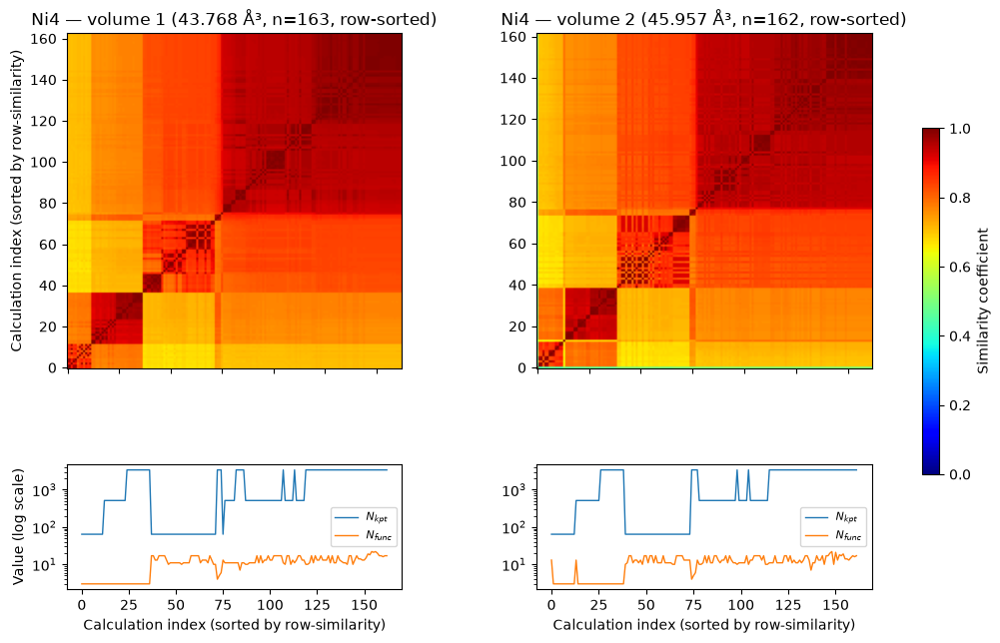

Saved: True

Material: Ni4O4   (formula: Ni4O4, 8 atoms/cell)
Cell: a=4.18 b=4.18 c=4.18 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [72.982, 76.631]


2026-09-06 15:35:20,248 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ni4O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

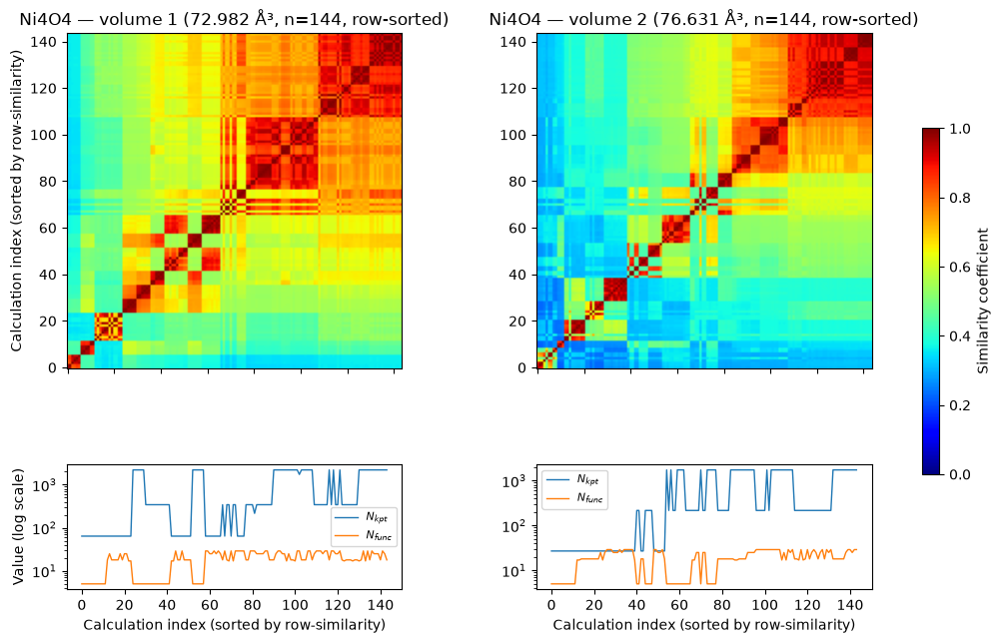

Saved: True

Material: O2Pd2   (formula: O2Pd2, 4 atoms/cell)
Cell: a=3.03 b=3.03 c=5.33 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:25,835 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O2Pd2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [48.934, 51.381]


  0%|          | 0/288 [00:00<?, ?it/s]

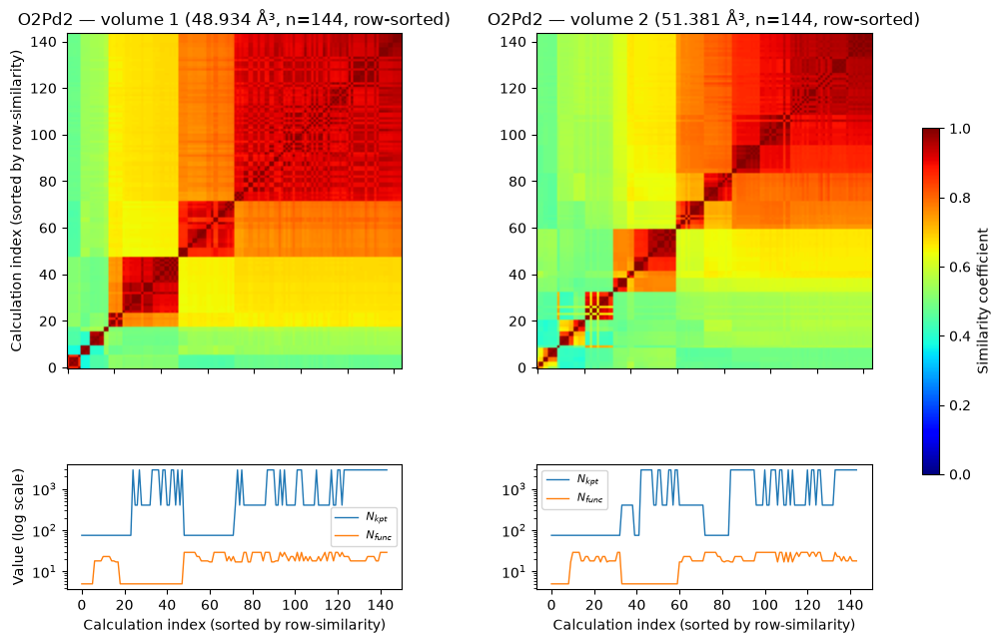

Saved: True

Material: O2Pt2   (formula: O2Pt2, 4 atoms/cell)
Cell: a=3.09 b=3.09 c=5.43 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:30,617 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O2Pt2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [49.35, 51.818]


  0%|          | 0/288 [00:00<?, ?it/s]

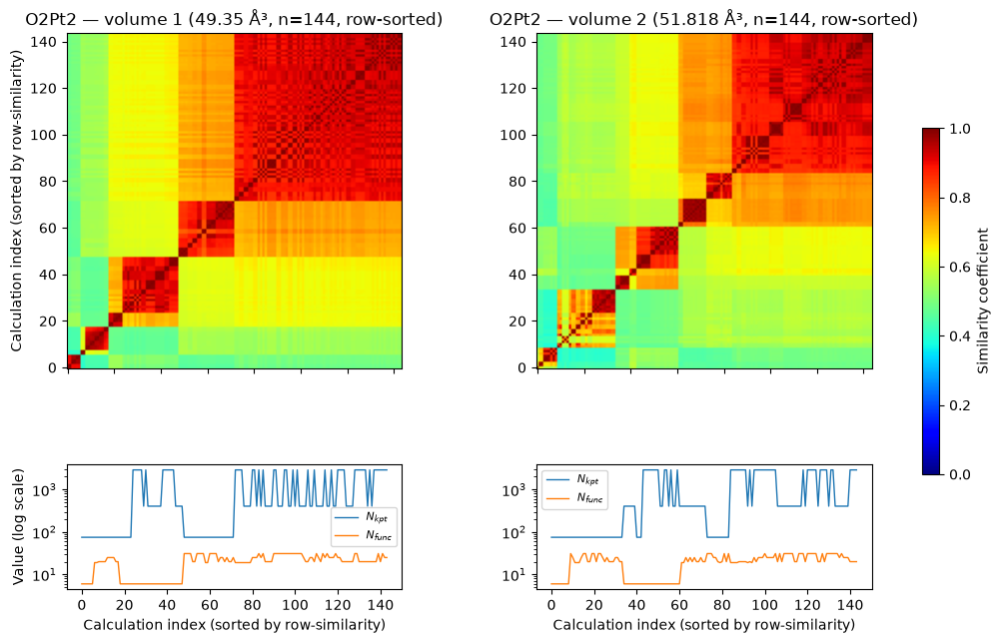

Saved: True

Material: O3Pm2   (formula: O3Pm2, 5 atoms/cell)
Cell: a=3.80 b=3.80 c=5.95 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:35:35,866 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O3Pm2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [74.536, 78.262]


  0%|          | 0/288 [00:00<?, ?it/s]

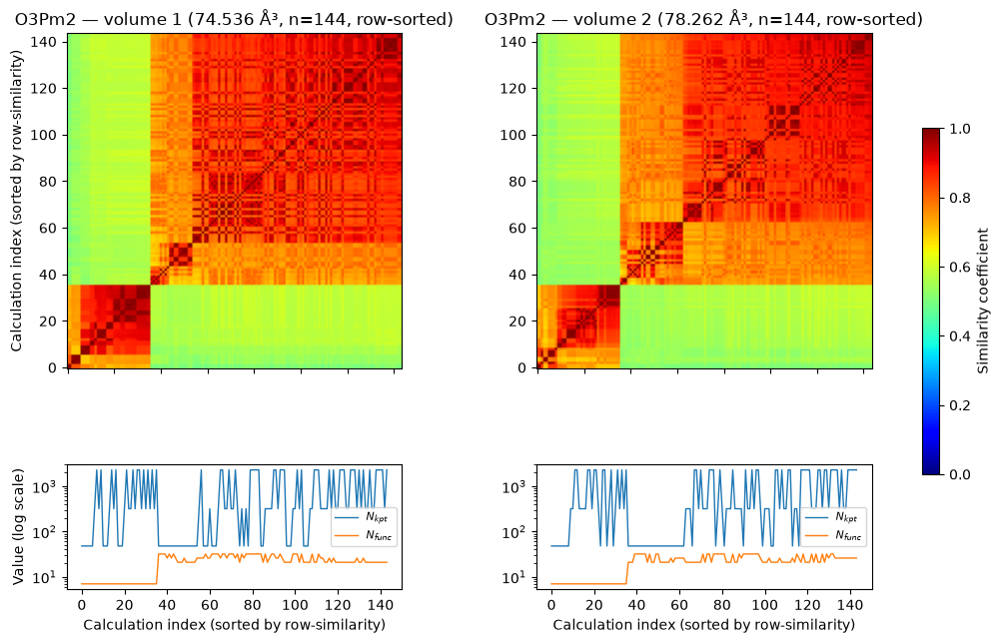

Saved: True

Material: O3Re   (formula: O3Re, 4 atoms/cell)
Cell: a=3.81 b=3.81 c=3.81 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:40,489 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O3Re_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [52.701, 55.336]


  0%|          | 0/288 [00:00<?, ?it/s]

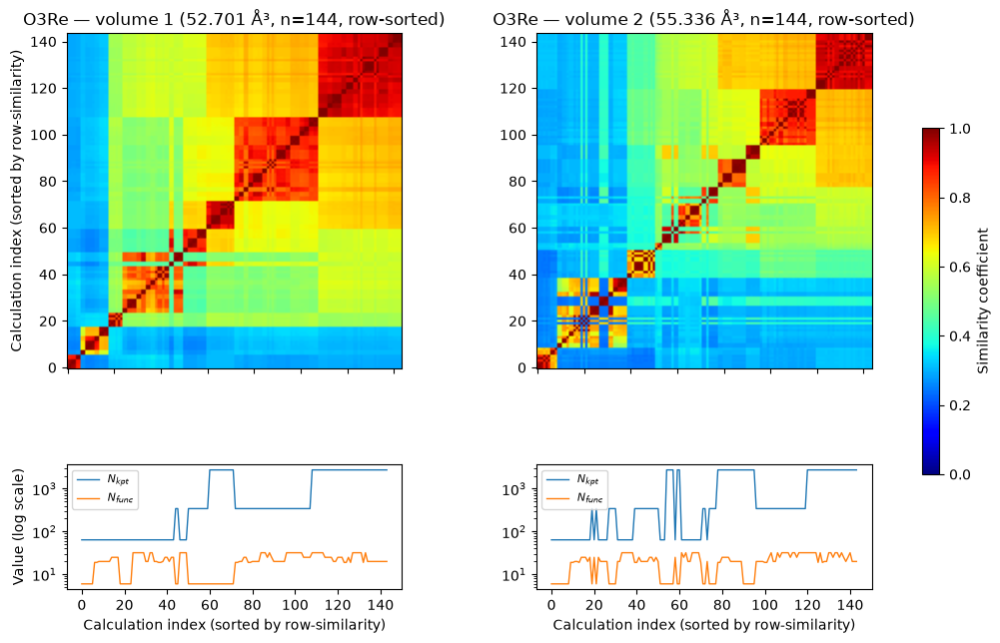

Saved: True

Material: O4   (formula: O4, 4 atoms/cell)
Cell: a=4.34 b=4.35 c=4.65 Å, α=90.0 β=66.7 γ=90.0°


2026-09-06 15:35:45,299 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [76.718, 80.553, 84.581]


  0%|          | 0/329 [00:00<?, ?it/s]

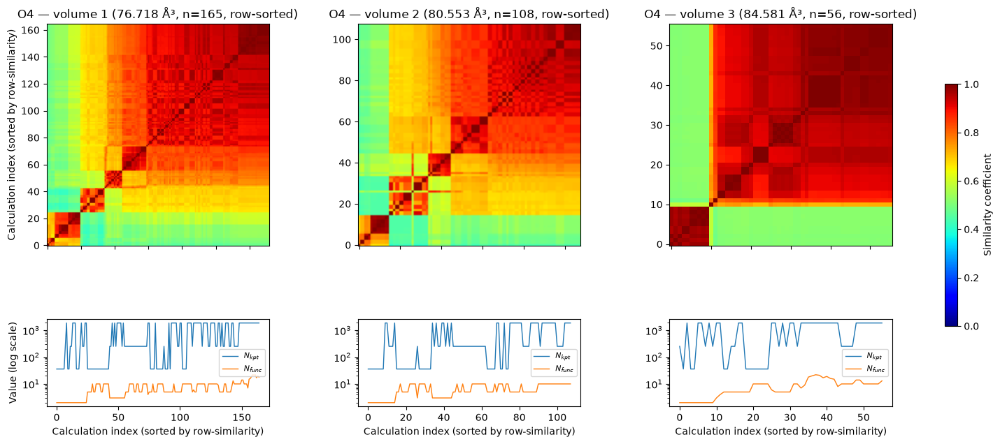

Saved: True

Material: O4Rh2   (formula: O4Rh2, 6 atoms/cell)
Cell: a=4.49 b=4.49 c=3.09 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:50,375 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O4Rh2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [62.267, 65.38]


  0%|          | 0/288 [00:00<?, ?it/s]

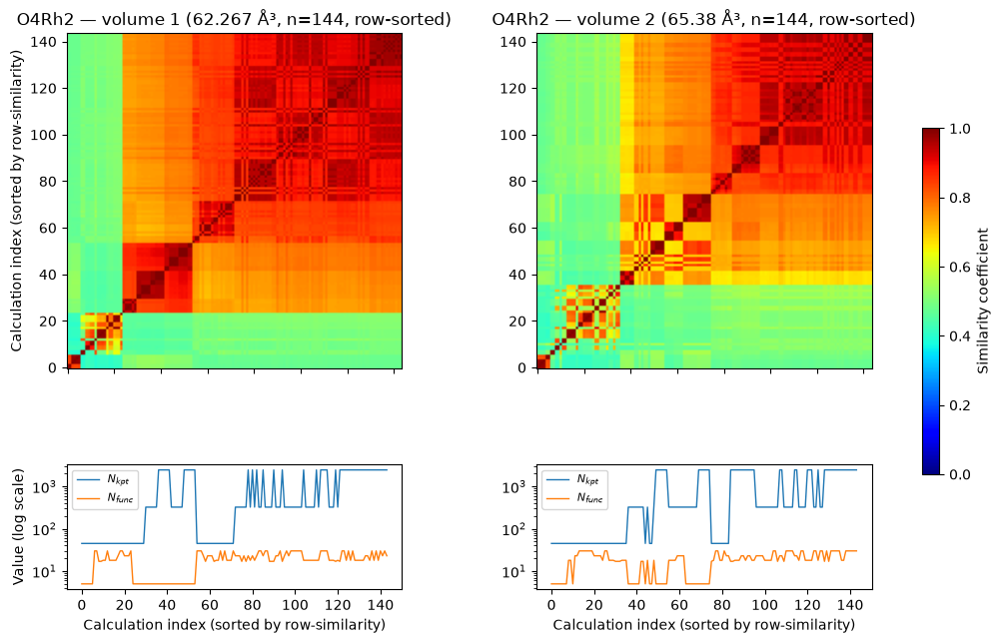

Saved: True

Material: O4Ru2   (formula: O4Ru2, 6 atoms/cell)
Cell: a=4.56 b=4.56 c=3.16 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:35:55,217 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O4Ru2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [62.653, 65.786]


  0%|          | 0/288 [00:00<?, ?it/s]

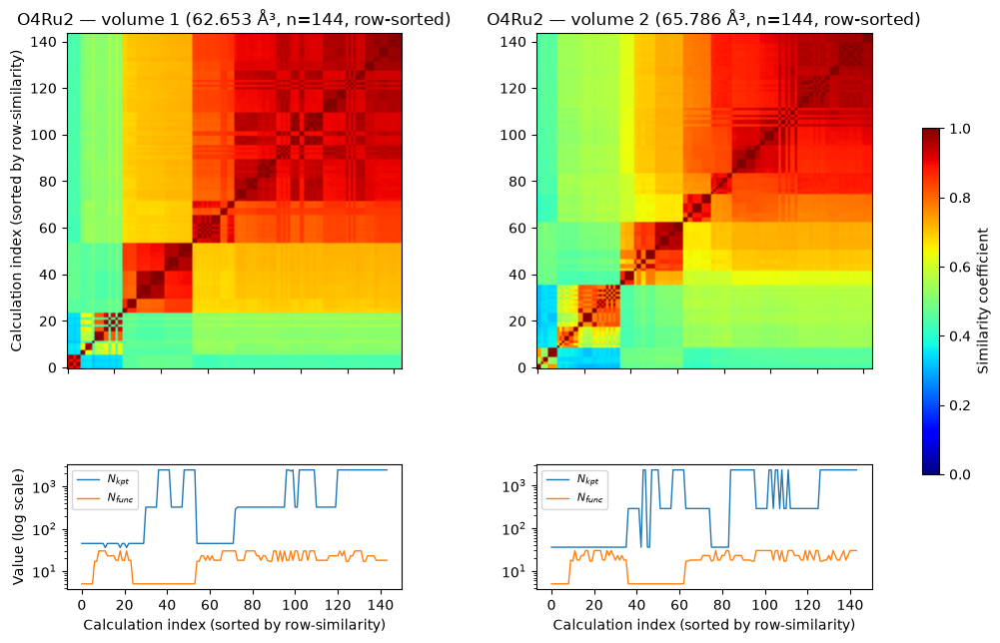

Saved: True

Material: O4Sr4   (formula: O4Sr4, 8 atoms/cell)
Cell: a=5.31 b=5.31 c=5.31 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:00,619 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O4Sr4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [142.728, 149.864]


  0%|          | 0/288 [00:00<?, ?it/s]

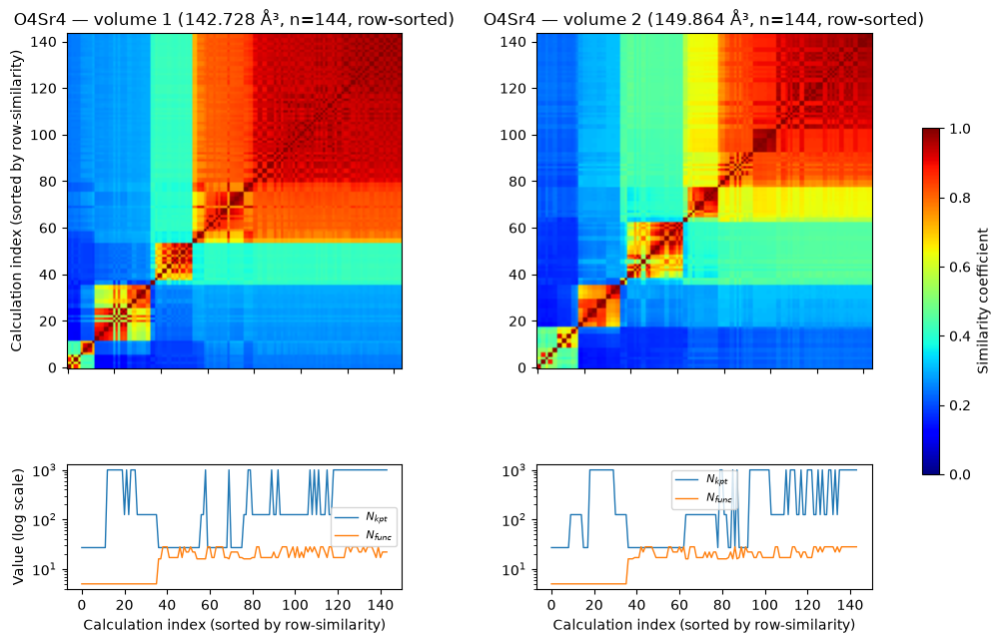

Saved: True

Material: O4Zn4   (formula: O4Zn4, 8 atoms/cell)
Cell: a=4.64 b=4.64 c=4.64 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:05,146 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O4Zn4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [95.381, 100.15]


  0%|          | 0/288 [00:00<?, ?it/s]

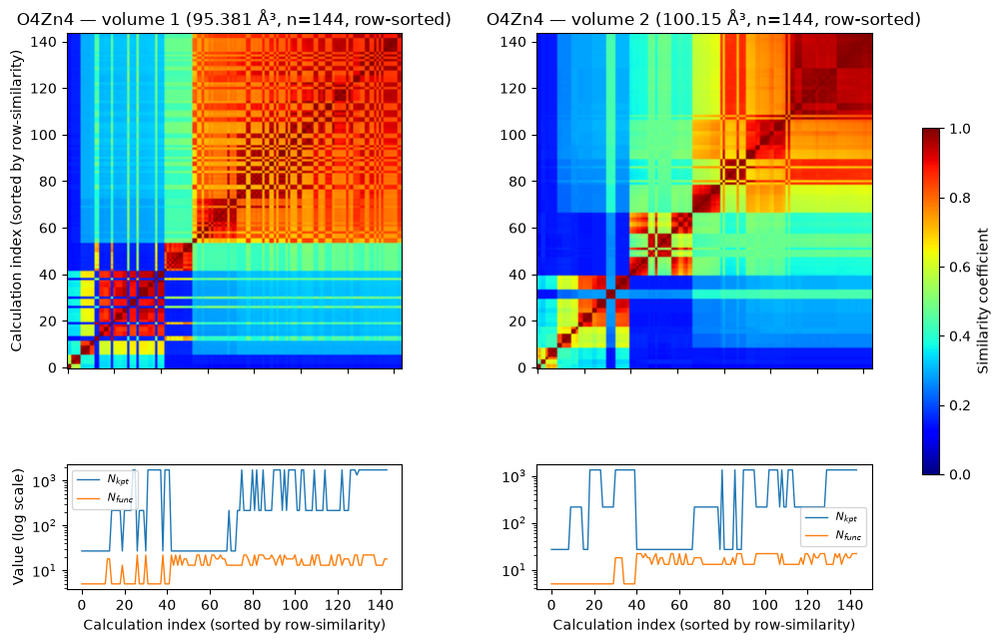

Saved: True

Material: O8Po4   (formula: O8Po4, 12 atoms/cell)
Cell: a=5.65 b=5.65 c=5.65 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:09,998 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O8Po4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [171.88, 180.474]


  0%|          | 0/288 [00:00<?, ?it/s]

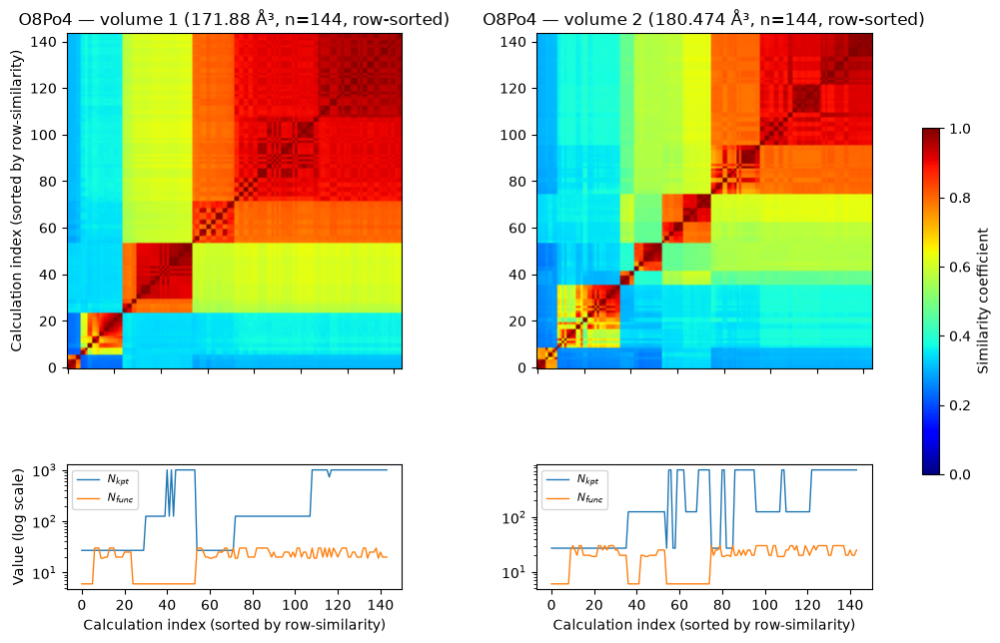

Saved: True

Material: O8Tc4   (formula: O8Tc4, 12 atoms/cell)
Cell: a=5.48 b=4.75 c=5.52 Å, α=90.0 β=117.7 γ=90.0°


2026-09-06 15:36:14,352 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/O8Tc4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [127.364, 133.732]


  0%|          | 0/288 [00:00<?, ?it/s]

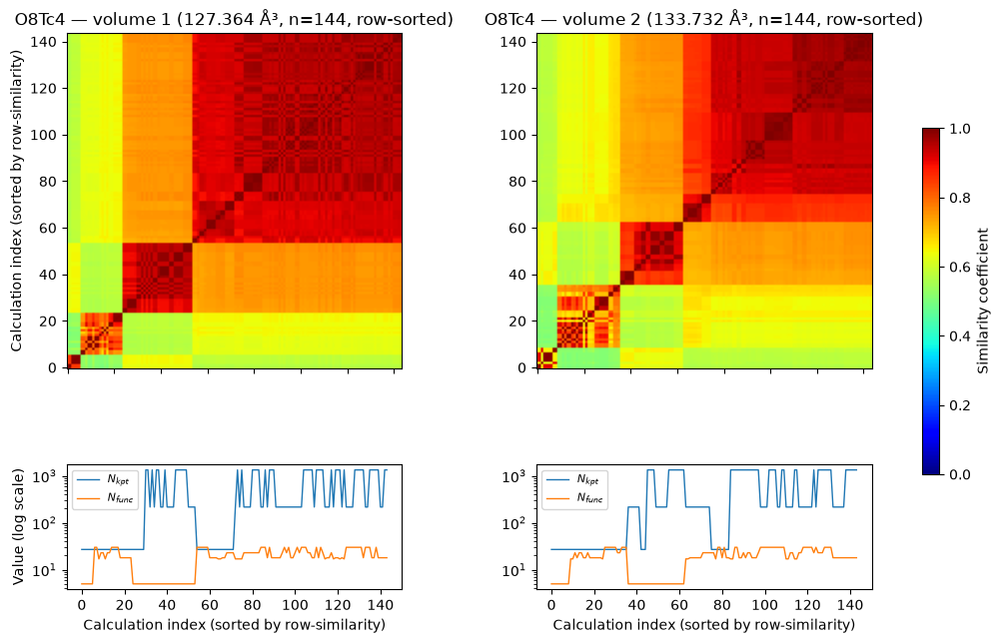

Saved: True

Material: Os2   (formula: Os2, 2 atoms/cell)
Cell: a=2.80 b=2.80 c=4.43 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:36:19,952 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Os2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [28.721, 30.157]


  0%|          | 0/321 [00:00<?, ?it/s]

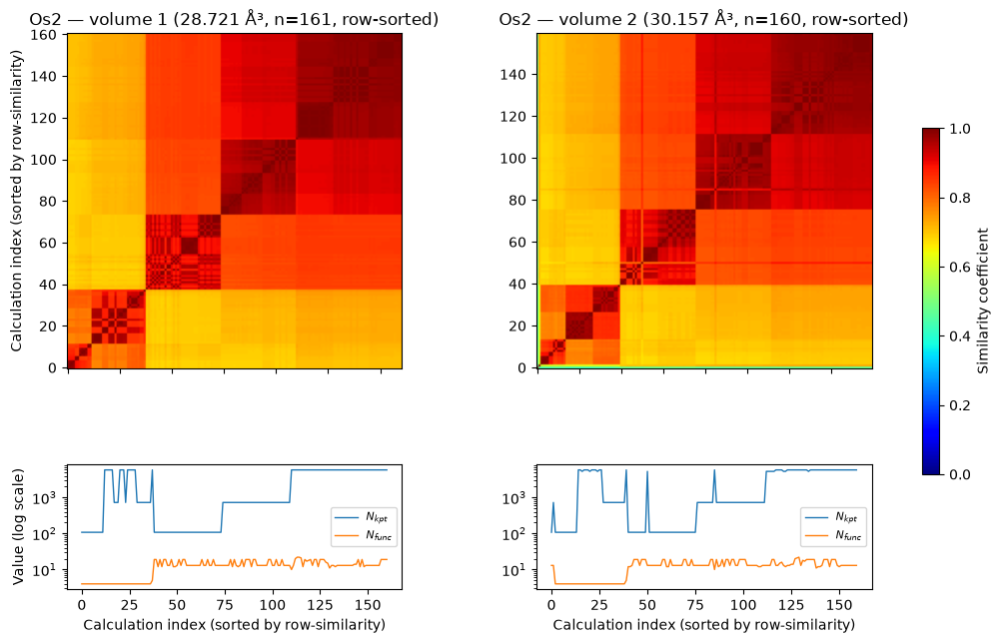

Saved: True

Material: P8   (formula: P8, 8 atoms/cell)
Cell: a=3.30 b=11.32 c=4.57 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:25,209 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/P8_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [171.034, 179.586]


  0%|          | 0/331 [00:00<?, ?it/s]

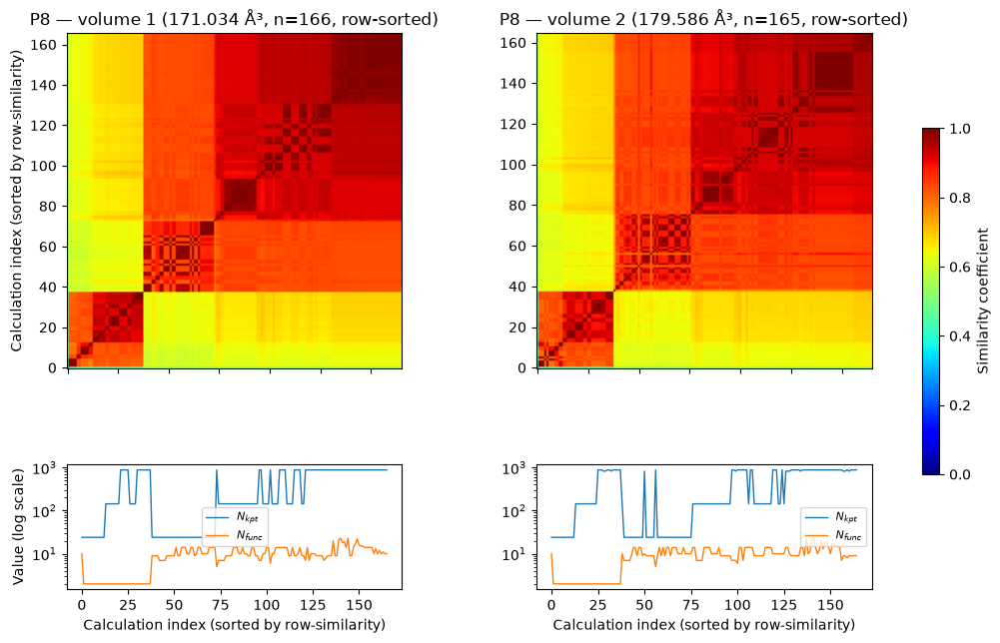

Saved: True

Material: Pb4   (formula: Pb4, 4 atoms/cell)
Cell: a=5.13 b=5.13 c=5.13 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:30,820 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Pb4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [128.318, 134.734]


  0%|          | 0/321 [00:00<?, ?it/s]

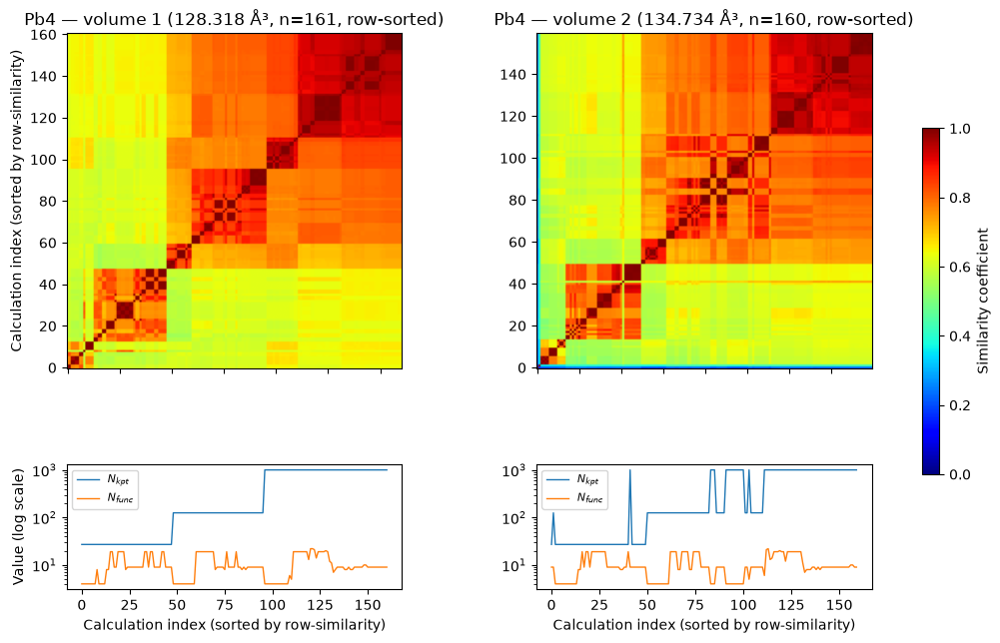

Saved: True

Material: Pb4S4   (formula: Pb4S4, 8 atoms/cell)
Cell: a=6.03 b=6.03 c=6.03 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:35,720 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Pb4S4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [209.14, 219.597]


  0%|          | 0/288 [00:00<?, ?it/s]

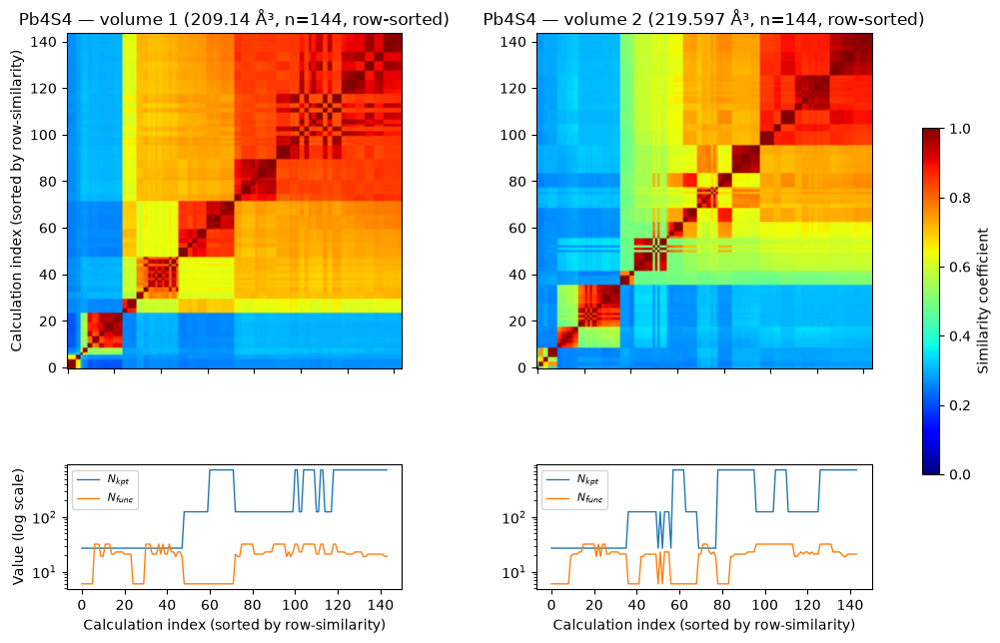

Saved: True

Material: Pd4   (formula: Pd4, 4 atoms/cell)
Cell: a=3.95 b=3.95 c=3.95 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:41,227 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Pd4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [61.777, 64.866]


  0%|          | 0/317 [00:00<?, ?it/s]

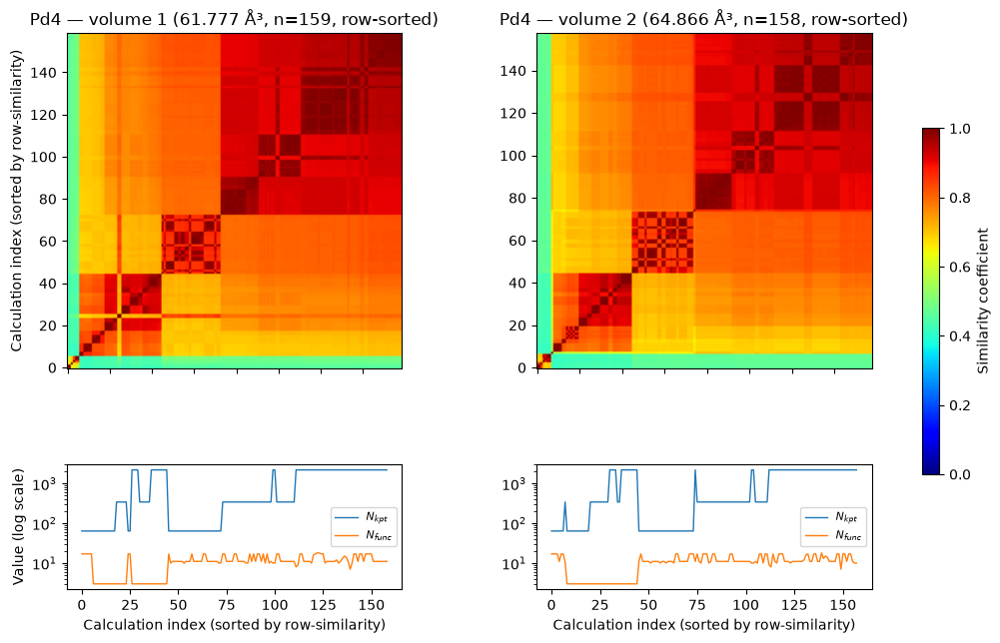

Saved: True

Material: Po   (formula: Po, 1 atoms/cell)
Cell: a=3.35 b=3.35 c=3.35 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:46,389 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Po_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [37.534, 39.411]


  0%|          | 0/321 [00:00<?, ?it/s]

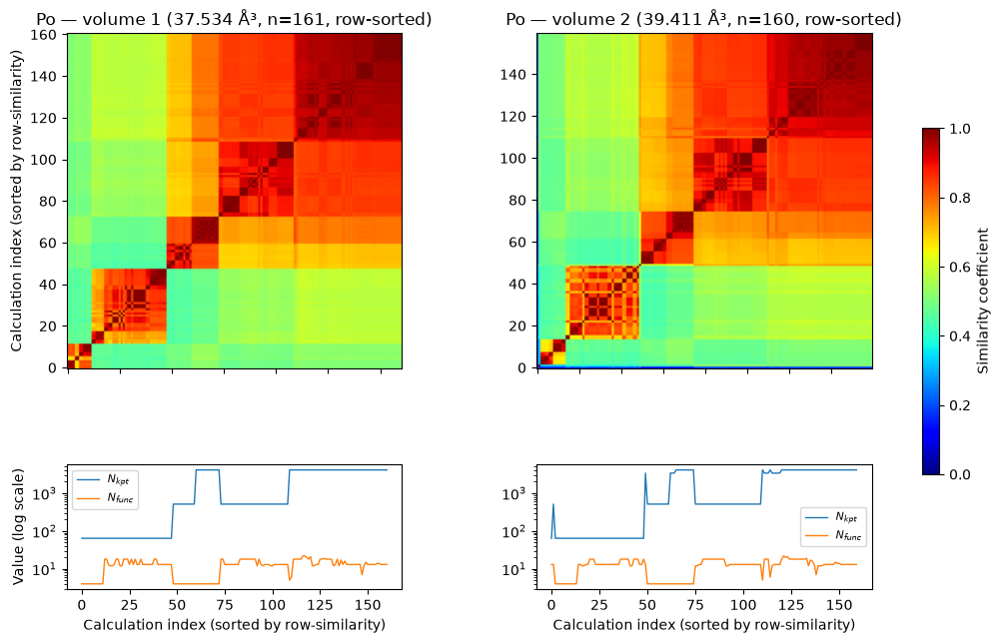

Saved: True

Material: Pt4   (formula: Pt4, 4 atoms/cell)
Cell: a=4.04 b=4.04 c=4.04 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:51,712 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Pt4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [62.89, 66.035]


  0%|          | 0/307 [00:00<?, ?it/s]

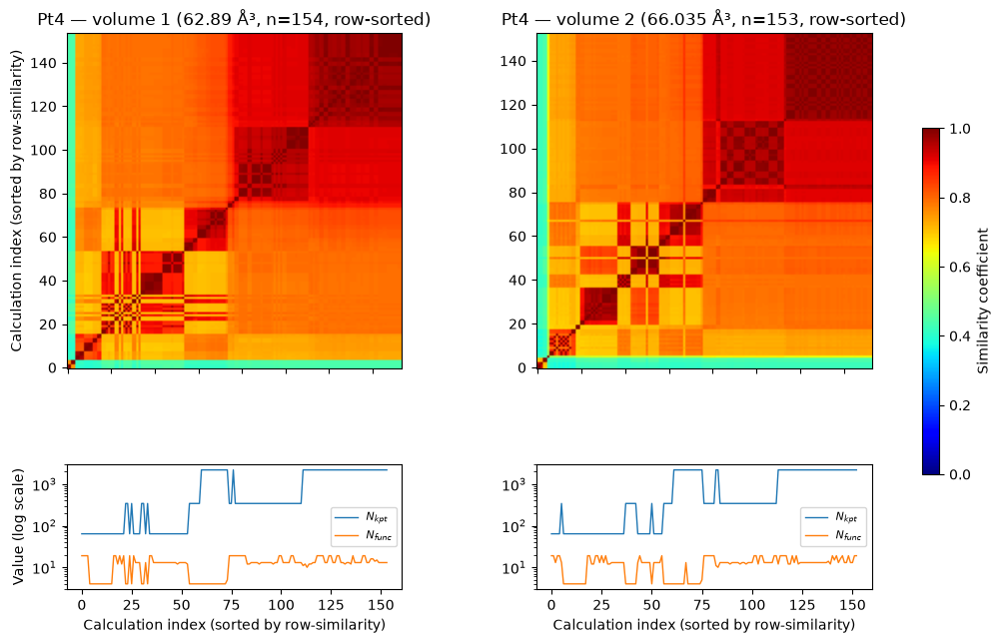

Saved: True

Material: Rb2   (formula: Rb2, 2 atoms/cell)
Cell: a=5.67 b=5.67 c=5.67 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:36:57,757 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Rb2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [182.474, 191.598]


  0%|          | 0/315 [00:00<?, ?it/s]

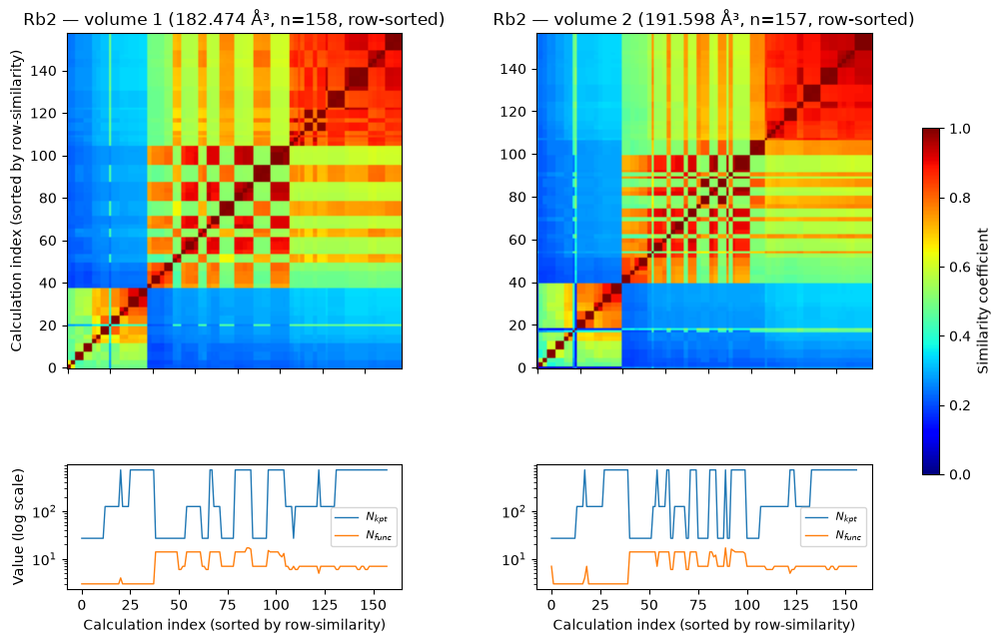

Saved: True

Material: Re2   (formula: Re2, 2 atoms/cell)
Cell: a=2.77 b=2.77 c=4.48 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:37:02,812 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Re2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [29.865, 31.358]


  0%|          | 0/321 [00:00<?, ?it/s]

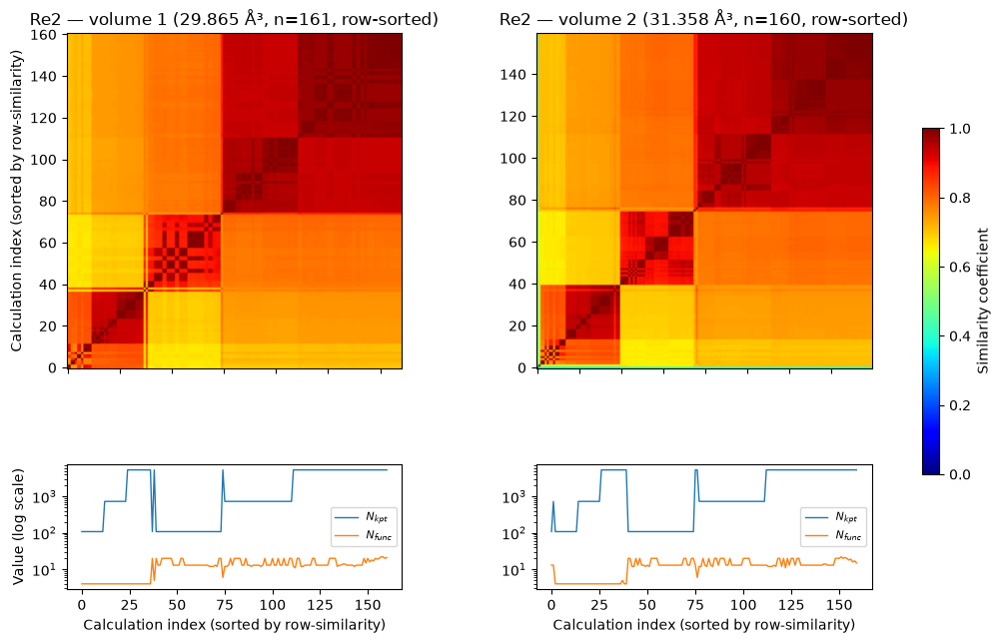

Saved: True

Material: Rh4   (formula: Rh4, 4 atoms/cell)
Cell: a=3.91 b=3.91 c=3.91 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:37:08,672 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Rh4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [56.716, 59.552]


  0%|          | 0/315 [00:00<?, ?it/s]

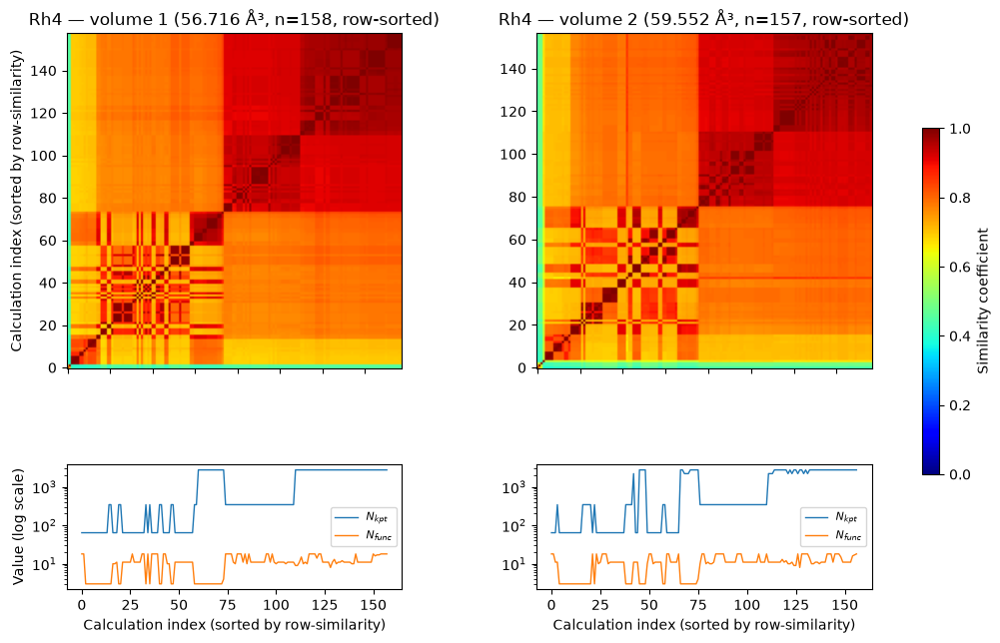

Saved: True

Material: Ru2   (formula: Ru2, 2 atoms/cell)
Cell: a=2.77 b=2.77 c=4.37 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:37:14,594 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ru2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [27.688, 29.073]


  0%|          | 0/321 [00:00<?, ?it/s]

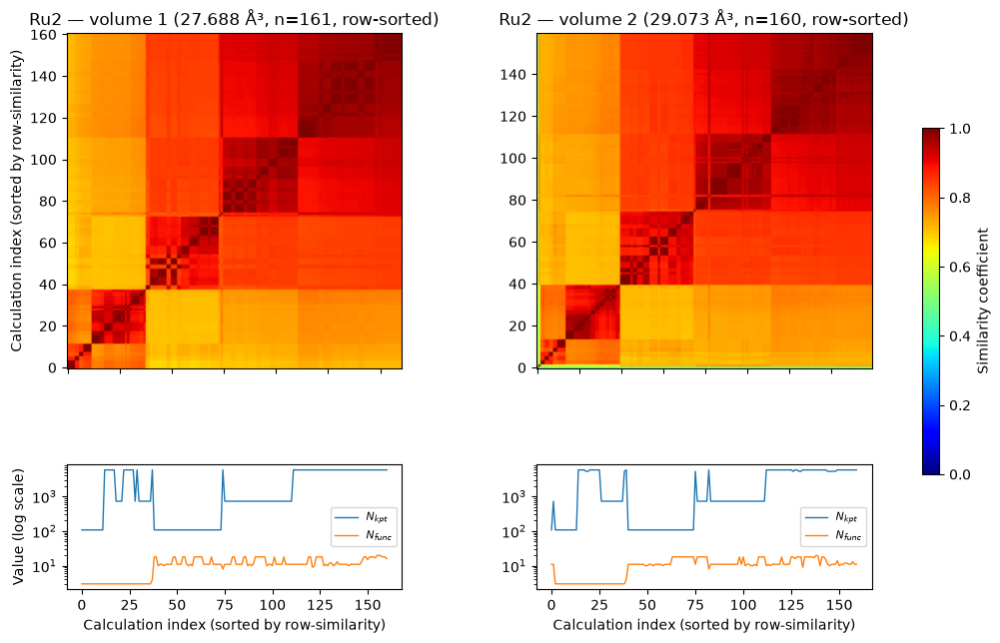

Saved: True

Material: S   (formula: S, 1 atoms/cell)
Cell: a=2.67 b=2.67 c=2.67 Å, α=91.5 β=91.5 γ=91.5°


2026-09-06 15:37:20,224 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/S_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [17.187, 18.047, 18.949]


  0%|          | 0/329 [00:00<?, ?it/s]

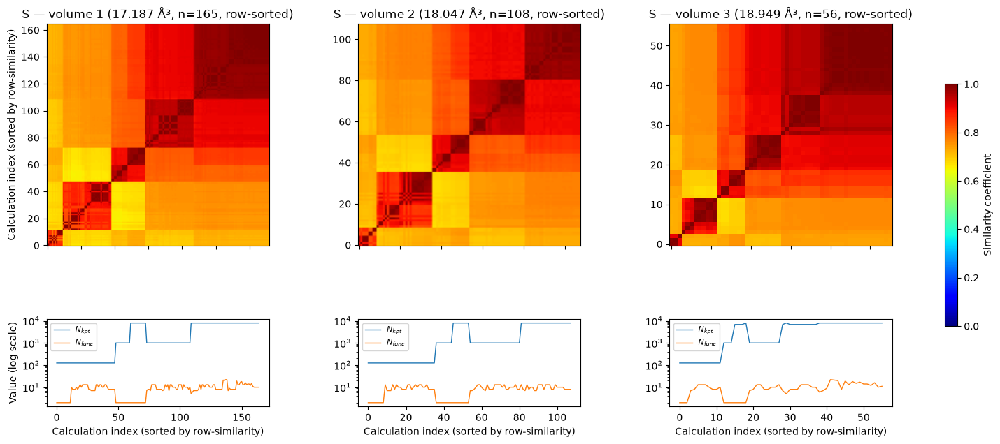

Saved: True

Material: S4Sc4   (formula: S4Sc4, 8 atoms/cell)
Cell: a=5.20 b=5.20 c=5.20 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:37:25,809 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/S4Sc4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [140.527, 147.553]


  0%|          | 0/288 [00:00<?, ?it/s]

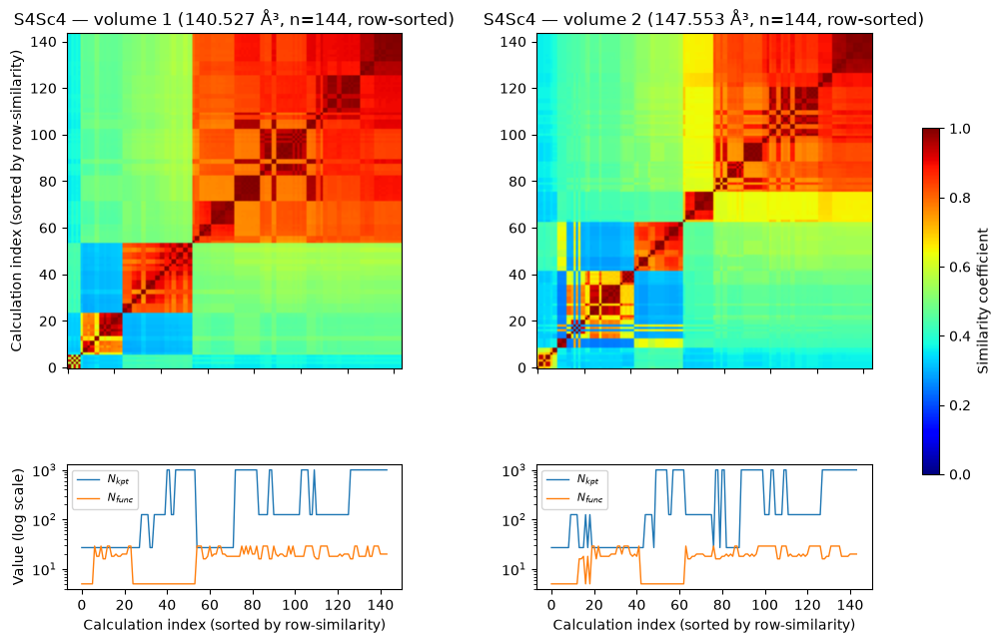

Saved: True

Material: S4Sn4   (formula: S4Sn4, 8 atoms/cell)
Cell: a=11.33 b=4.04 c=4.41 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:37:30,944 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/S4Sn4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [191.863, 201.456]


  0%|          | 0/288 [00:00<?, ?it/s]

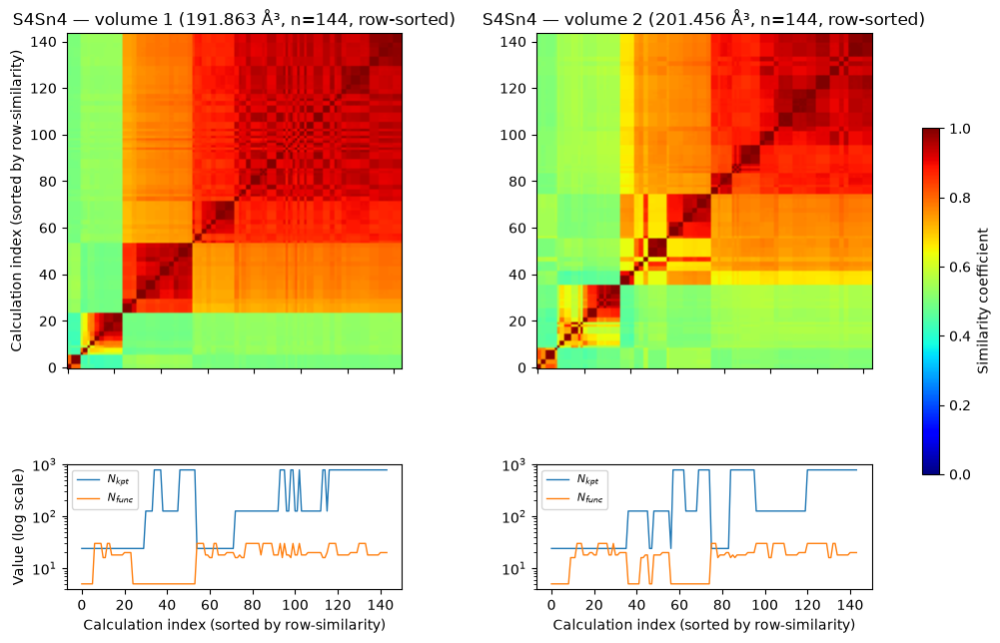

Saved: True

Material: S4Zn4   (formula: S4Zn4, 8 atoms/cell)
Cell: a=5.49 b=5.49 c=5.49 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:37:35,972 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/S4Zn4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [157.814, 165.705]


  0%|          | 0/288 [00:00<?, ?it/s]

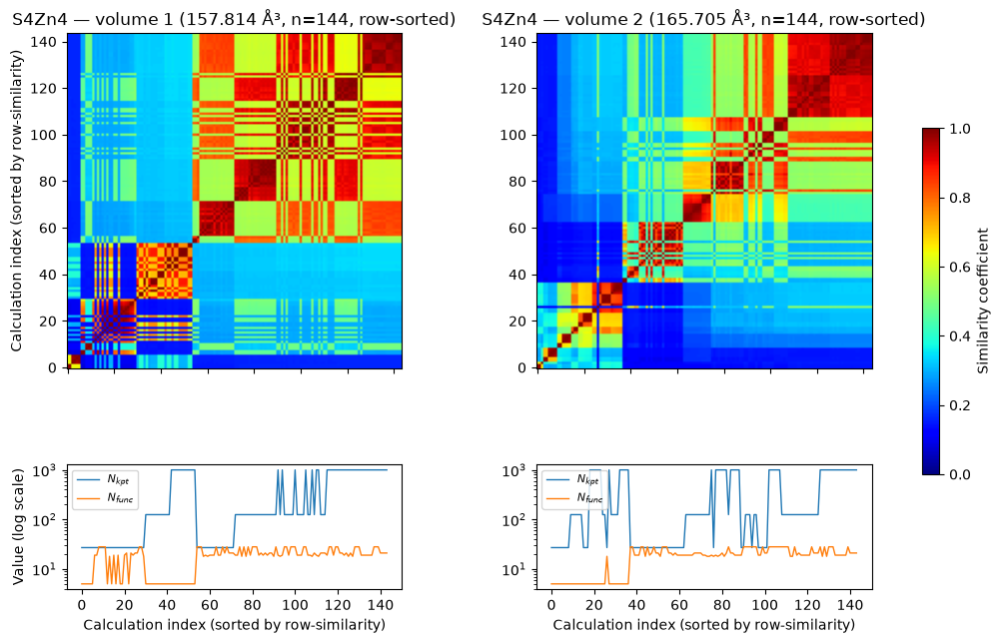

Saved: True

Material: Sb6   (formula: Sb6, 6 atoms/cell)
Cell: a=4.38 b=4.38 c=11.48 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:37:42,062 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Sb6_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [190.739, 200.276, 210.29]


  0%|          | 0/321 [00:00<?, ?it/s]

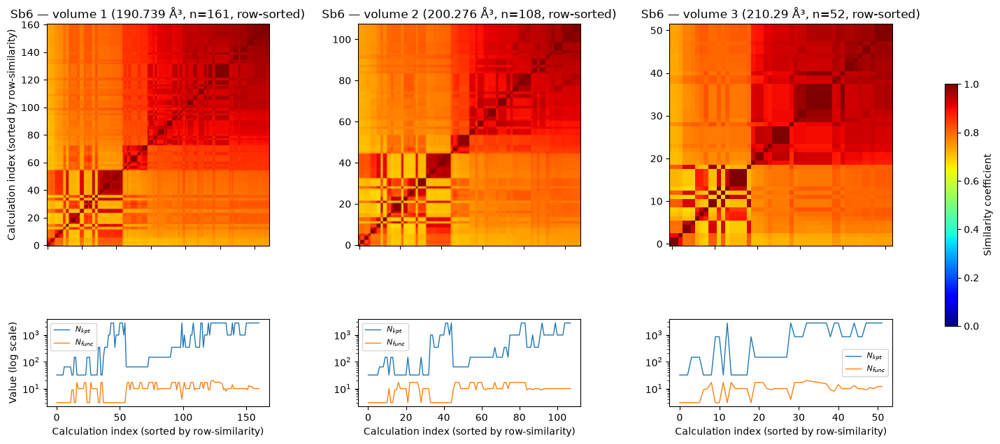

Saved: True

Material: Sc2   (formula: Sc2, 2 atoms/cell)
Cell: a=3.38 b=3.38 c=5.25 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:37:48,137 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Sc2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [49.317, 51.783]


  0%|          | 0/325 [00:00<?, ?it/s]

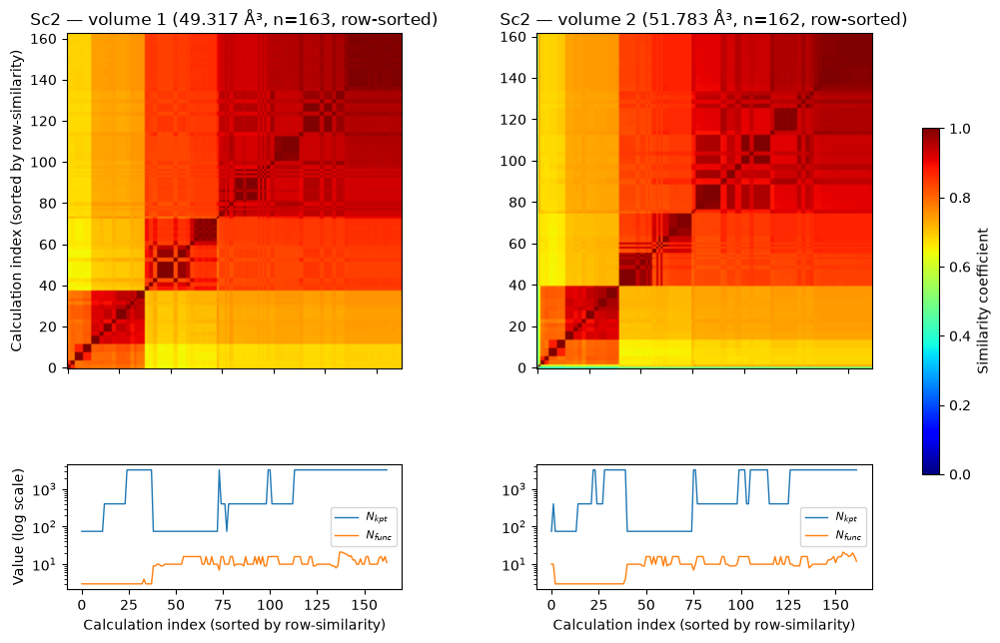

Saved: True

Material: Se3   (formula: Se3, 3 atoms/cell)
Cell: a=4.60 b=4.60 c=5.13 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:37:53,891 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Se3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [89.53, 94.007]


  0%|          | 0/321 [00:00<?, ?it/s]

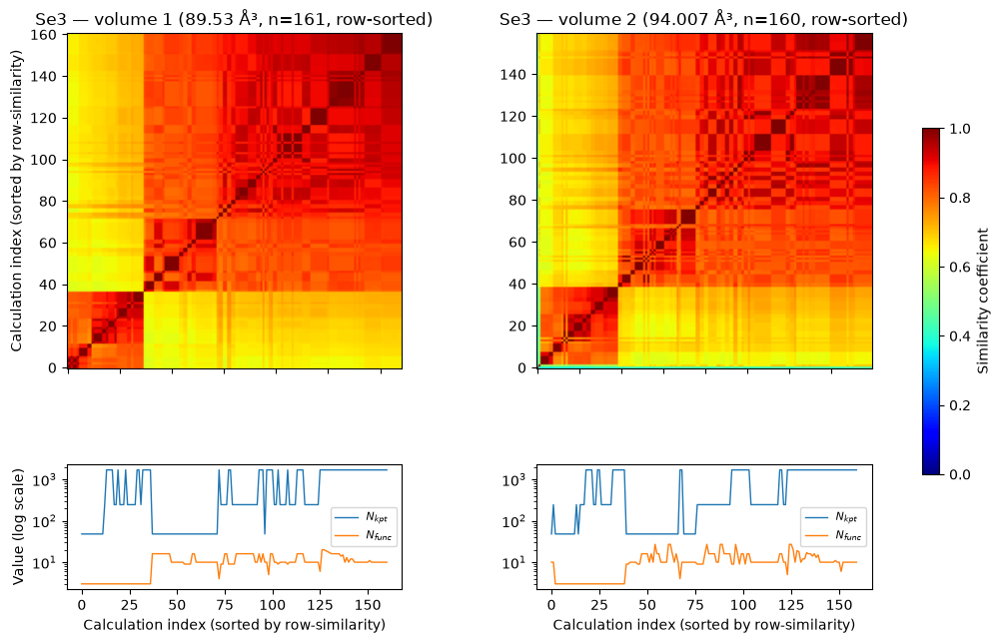

Saved: True

Material: Si2   (formula: Si2, 2 atoms/cell)
Cell: a=3.93 b=3.93 c=3.93 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:37:58,932 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Si2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [40.892, 42.937, 45.083]


  0%|          | 0/333 [00:00<?, ?it/s]

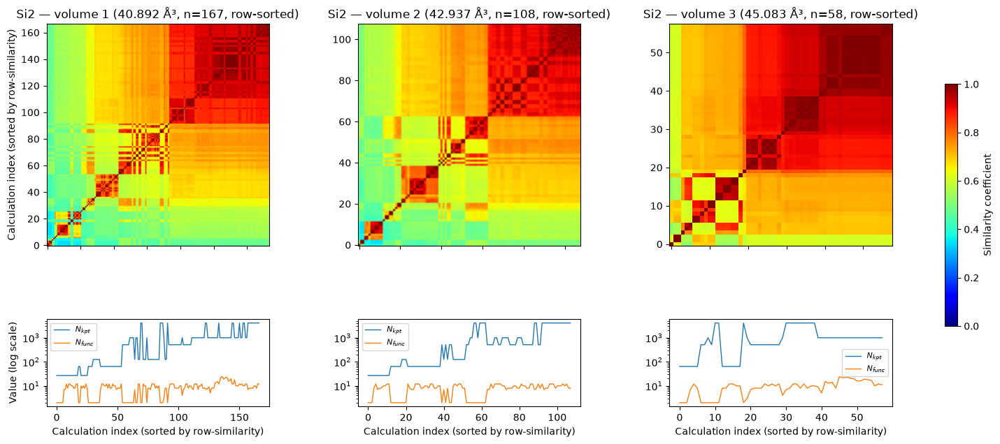

Saved: True

Material: Sn2   (formula: Sn2, 2 atoms/cell)
Cell: a=4.71 b=4.71 c=4.71 Å, α=60.0 β=60.0 γ=60.0°


2026-09-06 15:38:05,645 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Sn2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [73.718, 77.403, 81.274]


  0%|          | 0/321 [00:00<?, ?it/s]

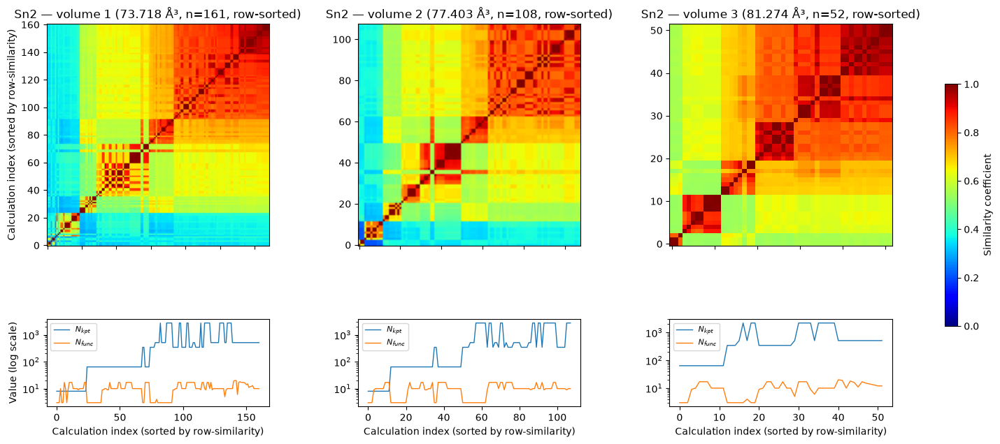

Saved: True

Material: Ta2   (formula: Ta2, 2 atoms/cell)
Cell: a=3.32 b=3.32 c=3.32 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:38:11,256 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ta2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [36.65, 38.483]


  0%|          | 0/317 [00:00<?, ?it/s]

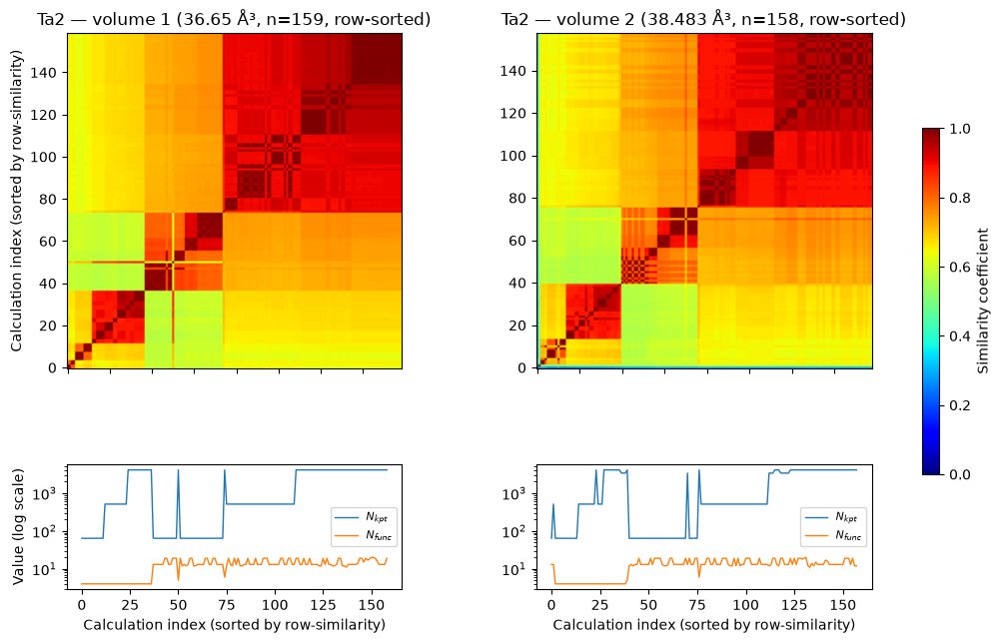

Saved: True

Material: Tc2   (formula: Tc2, 2 atoms/cell)
Cell: a=2.81 b=2.81 c=4.49 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:38:16,438 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Tc2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [29.192, 30.652]


  0%|          | 0/327 [00:00<?, ?it/s]

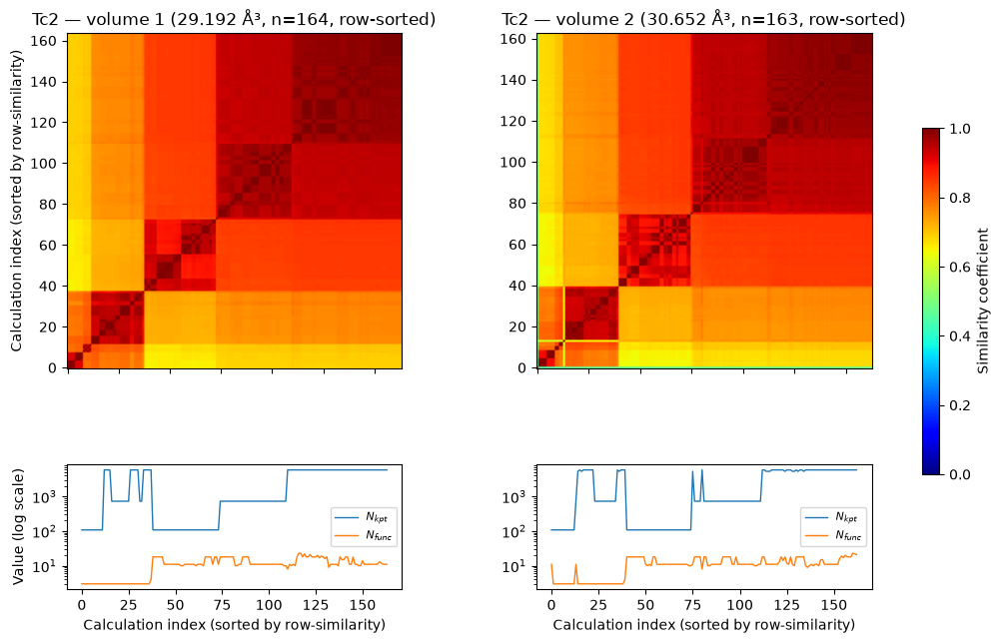

Saved: True

Material: Te3   (formula: Te3, 3 atoms/cell)
Cell: a=4.51 b=4.51 c=5.96 Å, α=90.0 β=90.0 γ=120.0°
Volume groups: [104.948, 110.195]


2026-09-06 15:38:23,100 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Te3_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/323 [00:00<?, ?it/s]

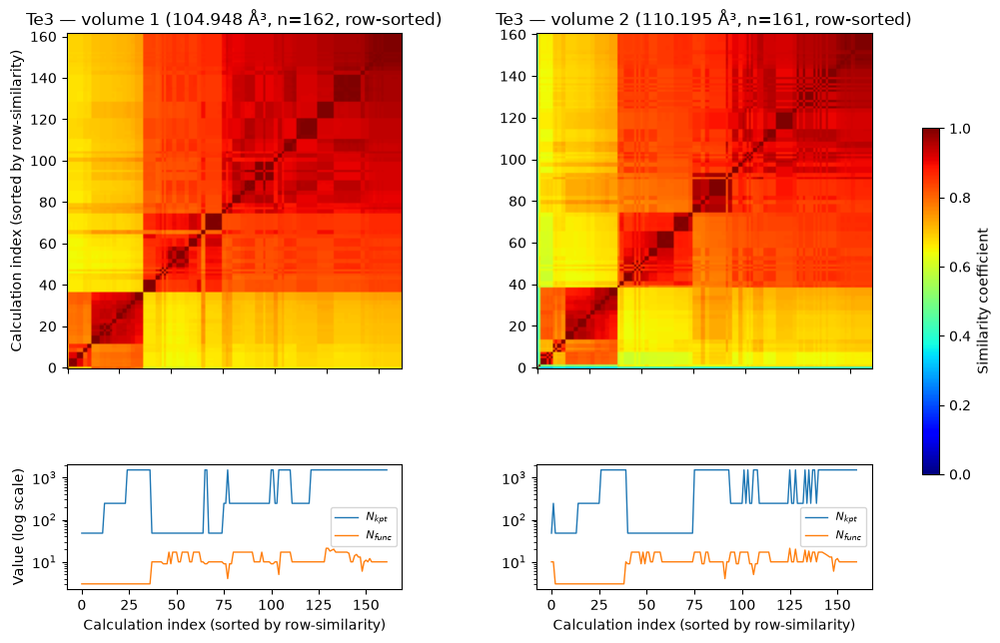

Saved: True

Material: Te4Zn4   (formula: Te4Zn4, 8 atoms/cell)
Cell: a=6.17 b=6.17 c=6.17 Å, α=90.0 β=90.0 γ=90.0°
Volume groups: [223.98, 235.179]


2026-09-06 15:38:28,664 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Te4Zn4_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/288 [00:00<?, ?it/s]

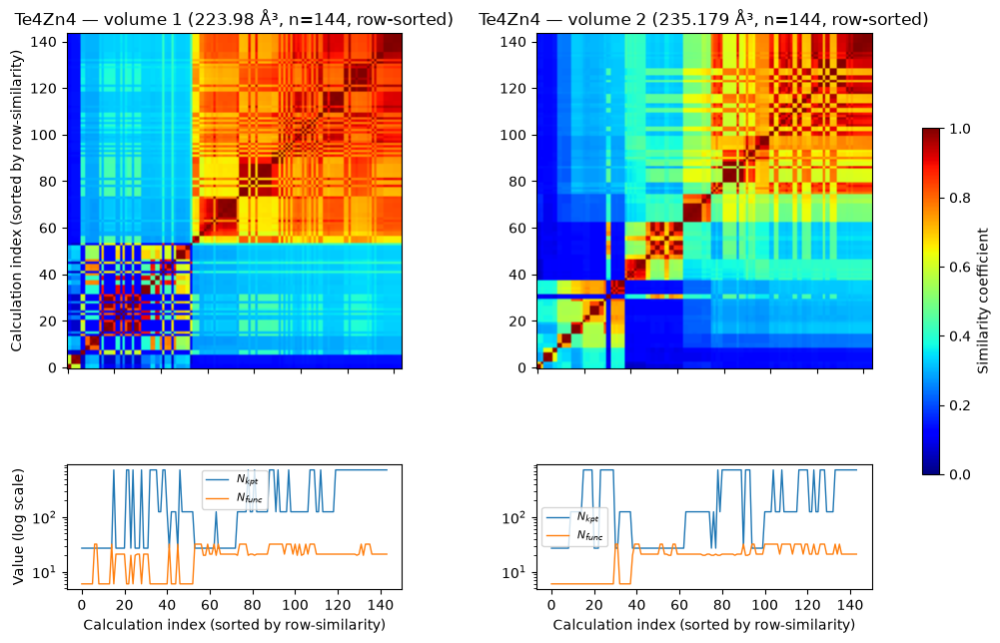

Saved: True

Material: Ti2   (formula: Ti2, 2 atoms/cell)
Cell: a=2.98 b=2.98 c=4.73 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:38:33,678 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Ti2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [34.743, 36.48]


  0%|          | 0/329 [00:00<?, ?it/s]

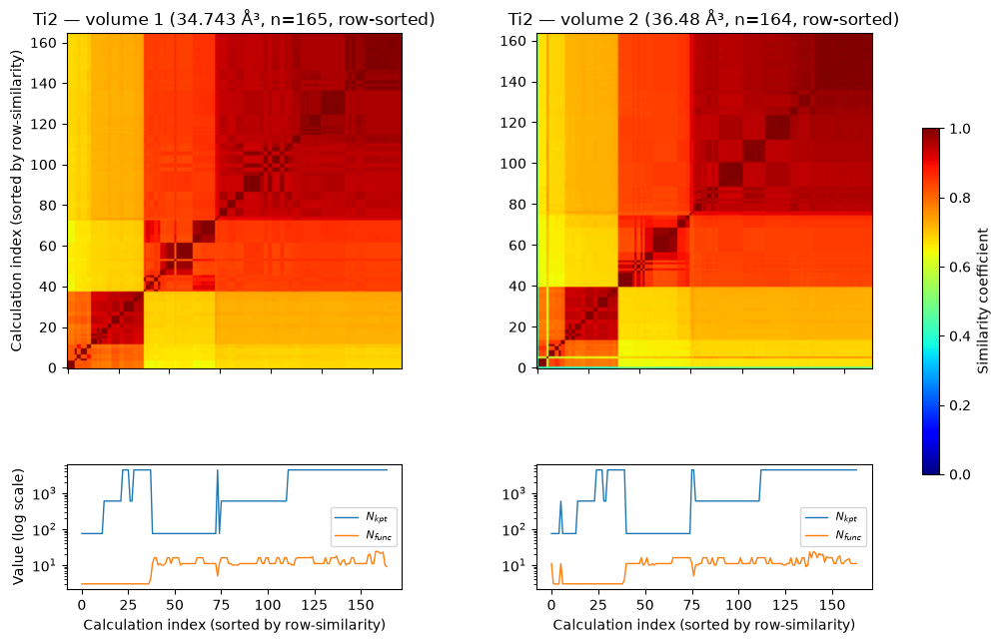

Saved: True

Material: Tl2   (formula: Tl2, 2 atoms/cell)
Cell: a=3.59 b=3.59 c=5.64 Å, α=90.0 β=90.0 γ=60.0°


2026-09-06 15:38:39,206 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Tl2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [63.062, 66.215]


  0%|          | 0/317 [00:00<?, ?it/s]

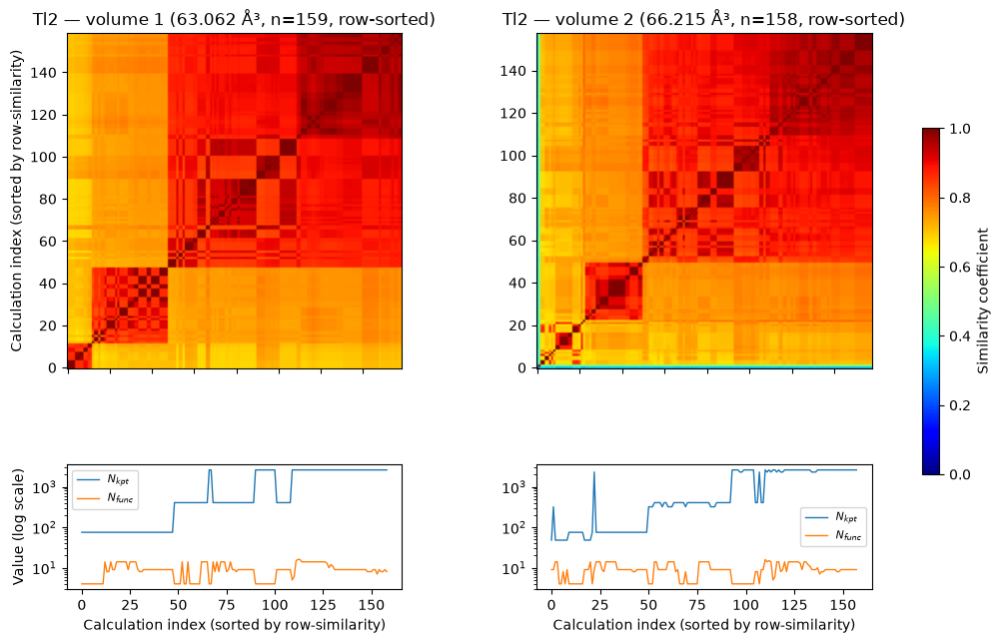

Saved: True

Material: V2   (formula: V2, 2 atoms/cell)
Cell: a=3.05 b=3.05 c=3.05 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:38:44,849 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/V2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [26.971, 28.32]


  0%|          | 0/331 [00:00<?, ?it/s]

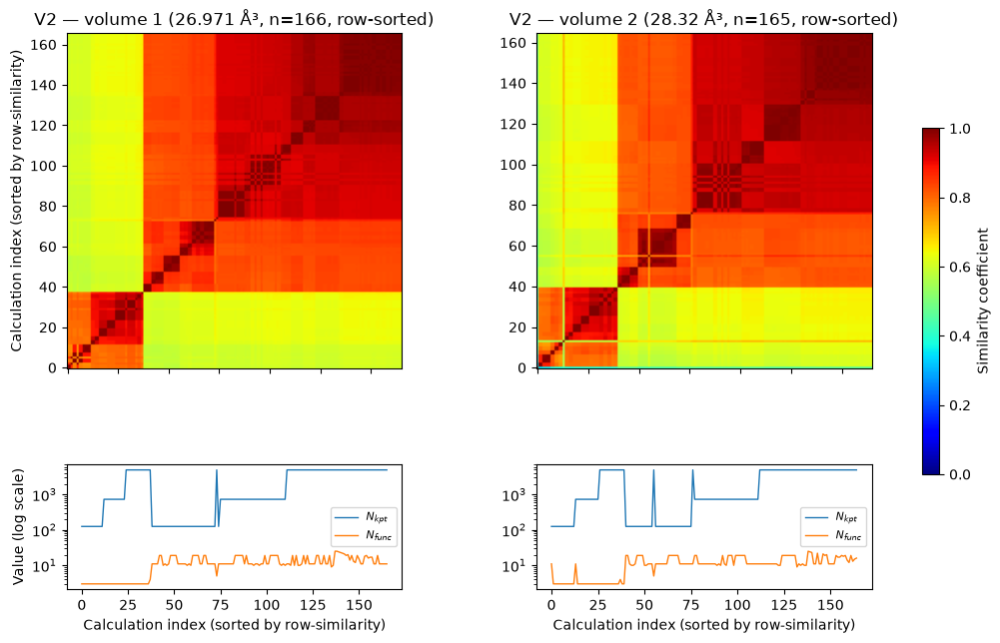

Saved: True

Material: W2   (formula: W2, 2 atoms/cell)
Cell: a=3.19 b=3.19 c=3.19 Å, α=90.0 β=90.0 γ=90.0°


2026-09-06 15:38:50,483 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/W2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [32.452, 34.075]


  0%|          | 0/321 [00:00<?, ?it/s]

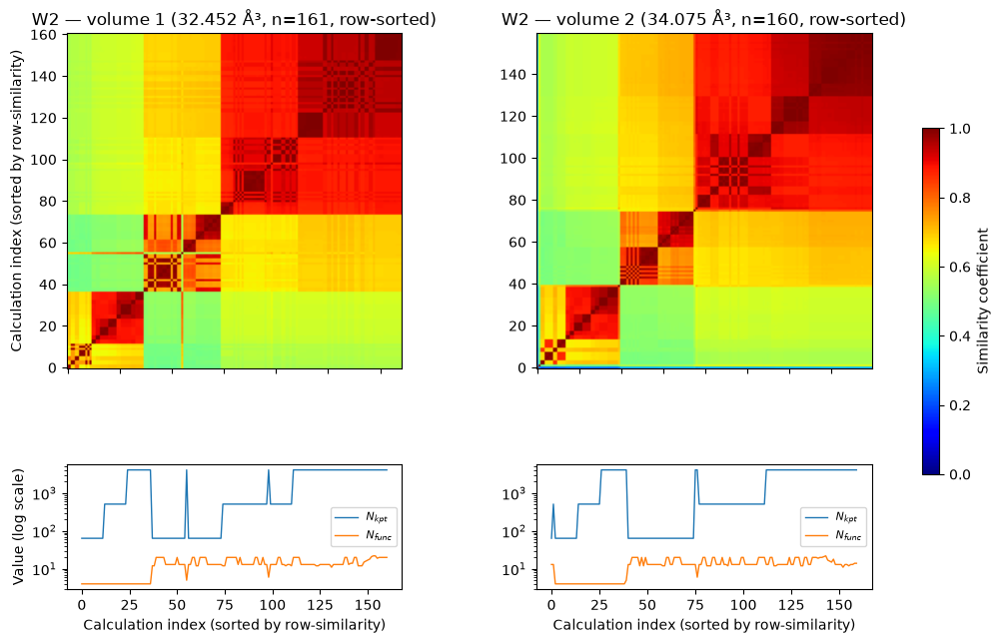

Saved: True

Material: Y2   (formula: Y2, 2 atoms/cell)
Cell: a=3.72 b=3.72 c=5.77 Å, α=90.0 β=90.0 γ=120.0°
Volume groups: [65.842, 69.134]


2026-09-06 15:38:56,116 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Y2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


  0%|          | 0/319 [00:00<?, ?it/s]

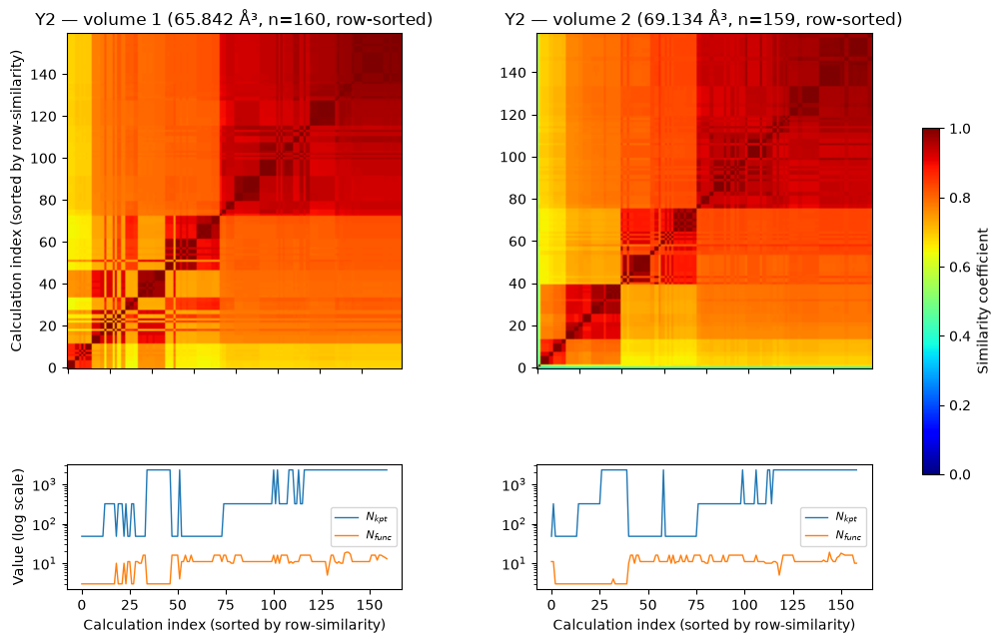

Saved: True

Material: Zr2   (formula: Zr2, 2 atoms/cell)
Cell: a=3.29 b=3.29 c=5.27 Å, α=90.0 β=90.0 γ=120.0°


2026-09-06 15:39:01,727 - /home/ahmed/SOL_Research/dos-convergence-analysis/notebooks/data/full_run/Zr2_log - INFO - Fingerprints with name "DOS" exist. Reading from database.


Volume groups: [47.063, 49.417]


  0%|          | 0/321 [00:00<?, ?it/s]

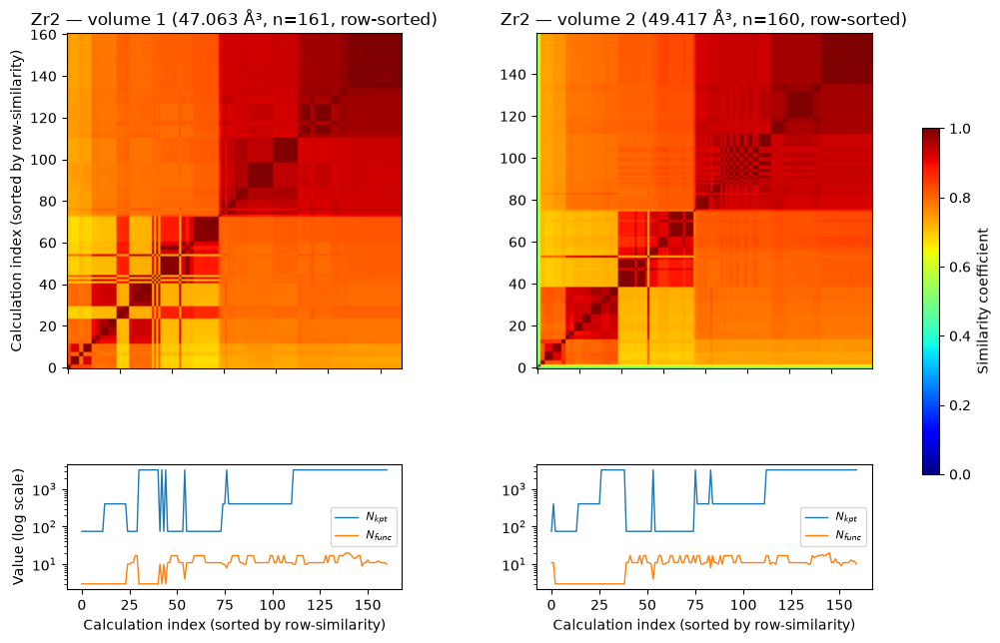

Saved: True
status
success    146
Name: count, dtype: int64


,material,status


In [20]:
run_log = []

for material_name in full_run_materials:
    try:
        mat_db = MaterialsDatabase(filename=str(database_dir / f"{material_name}.db"))
        print_material_header(material_name, mat_db)
        id_to_group, group_centers = assign_volume_groups(mat_db)
        print(f"Volume groups: {group_centers}")
        plot_volume_split_heatmaps_row_sorted(material_name, mat_db, id_to_group, group_centers, volume_test_dir)
        run_log.append({"material": material_name, "status": "success"})
    except Exception as e:
        print(f"FAILED on {material_name}: {e}")
        run_log.append({"material": material_name, "status": "failed", "error": str(e)})

run_log_df = pd.DataFrame(run_log)
print(run_log_df["status"].value_counts())
run_log_df[run_log_df["status"] == "failed"]

In [21]:
import os
svg_files = list(volume_test_dir.glob("*.svg"))
print(f"SVGs saved: {len(svg_files)}")
print(f"Materials in run: {len(full_run_materials)}")
print("Match:", len(svg_files) == len(full_run_materials))

SVGs saved: 146
Materials in run: 146
Match: True
